# 09 — Baseline Machine Learning

## Objective
Build and evaluate baseline machine learning models to predict
a player's next recorded appearance performance.

## Workflow
1. Load model datasets
2. Inspect dataset structure
3. Validate prediction targets
4. Audit feature leakage
5. Create chronological train/test splits
6. Establish DummyRegressor baselines
7. Train and evaluate baseline regression models

In [1]:

from pathlib import Path
import sys
import pandas as pd
import numpy as np

PROJECT_ROOT = Path.cwd().parent

print("Project root:", PROJECT_ROOT)
print("Project exists:", PROJECT_ROOT.exists())
print("Python:", sys.version)
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)

Project root: d:\Git\Personal\ipl-player-performance-v2
Project exists: True
Python: 3.12.16 | packaged by Anaconda, Inc. | (main, Oct 26 2026, 20:13:05) [MSC v.1942 64 bit (AMD64)]
Pandas: 3.1.0
NumPy: 2.5.4


In [2]:
FEATURE_DIR = PROJECT_ROOT / "data" / "processed" / "features"

batting_path = FEATURE_DIR / "batting_model_dataset.csv"
bowling_path = FEATURE_DIR / "bowling_model_dataset.csv"

assert batting_path.exists(), f"Missing file: {batting_path}"
assert bowling_path.exists(), f"Missing file: {bowling_path}"

batting_df = pd.read_csv(batting_path)
bowling_df = pd.read_csv(bowling_path)

print("BATTING DATASET")
print("Shape:", batting_df.shape)
display(batting_df.head())

print("\nBOWLING DATASET")
print("Shape:", bowling_df.shape)
display(bowling_df.head())

BATTING DATASET
Shape: (18083, 56)


,match_id,player,is_super_over,batting_team,runs_scored,balls_faced,fours,sixes,dismissals,retired_hurt_count,...,strike_rate_rolling_mean_3,strike_rate_rolling_mean_5,strike_rate_rolling_mean_10,strike_rate_expanding_mean,previous_dismissals,dismissals_rolling_mean_3,dismissals_rolling_mean_5,dismissals_rolling_mean_10,dismissals_expanding_mean,matches_played_before
0,548346,A Ashish Reddy,False,Deccan Chargers,10,10,0,1,1,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
1,548352,A Ashish Reddy,False,Deccan Chargers,3,3,0,0,1,0,...,100.0,100.0,100.0,100.0,1.0,1.000000,1.00,1.00,1.00,1
2,548359,A Ashish Reddy,False,Deccan Chargers,8,8,1,0,1,0,...,100.0,100.0,100.0,100.0,1.0,1.000000,1.00,1.00,1.00,2
3,548373,A Ashish Reddy,False,Deccan Chargers,10,4,2,0,0,0,...,100.0,100.0,100.0,100.0,1.0,1.000000,1.00,1.00,1.00,3
4,548376,A Ashish Reddy,False,Deccan Chargers,4,4,0,0,1,0,...,150.0,137.5,137.5,137.5,0.0,0.666667,0.75,0.75,0.75,4



BOWLING DATASET
Shape: (14123, 43)


,match_id,player,is_super_over,runs_conceded,legal_balls,wides_conceded,noballs_conceded,innings_bowled,wickets,overs_bowled,...,legal_balls_rolling_mean_3,legal_balls_rolling_mean_5,legal_balls_rolling_mean_10,legal_balls_expanding_mean,previous_economy_rate,economy_rate_rolling_mean_3,economy_rate_rolling_mean_5,economy_rate_rolling_mean_10,economy_rate_expanding_mean,matches_played_before
0,548341,A Ashish Reddy,False,32,24,0,0,1,2,4.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
1,548346,A Ashish Reddy,False,11,13,1,0,1,1,2.166667,...,24.000000,24.000000,24.000000,24.000000,8.000000,8.000000,8.000000,8.000000,8.000000,1
2,548348,A Ashish Reddy,False,32,18,0,1,1,1,3.000000,...,18.500000,18.500000,18.500000,18.500000,5.076923,6.538462,6.538462,6.538462,6.538462,2
3,548352,A Ashish Reddy,False,16,12,0,1,1,1,2.000000,...,18.333333,18.333333,18.333333,18.333333,10.666667,7.914530,7.914530,7.914530,7.914530,3
4,548356,A Ashish Reddy,False,36,24,1,0,1,1,4.000000,...,14.333333,16.750000,16.750000,16.750000,8.000000,7.914530,7.935897,7.935897,7.935897,4


In [3]:
for name, df in {
    "Batting": batting_df,
    "Bowling": bowling_df
}.items():

    print(f"\n{name} DATA QUALITY")
    print("Rows:", len(df))
    print("Duplicate rows:", df.duplicated().sum())
    print("Missing values:", df.isna().sum().sum())
    print("Duplicate columns:", df.columns.duplicated().sum())
    print("Date columns:", [
        col for col in df.columns
        if "date" in col.lower()
    ])


Batting DATA QUALITY
Rows: 18083
Duplicate rows: 0
Missing values: 24424
Duplicate columns: 0
Date columns: ['date', 'previous_match_date']

Bowling DATA QUALITY
Rows: 14123
Duplicate rows: 0
Missing values: 22837
Duplicate columns: 0
Date columns: ['date', 'previous_match_date']


## 2. Target Variable and Missing-Value Audit

Objectives:
- Identify missing values by column.
- Verify target availability.
- Inspect target distributions.
- Identify columns requiring preprocessing.

In [4]:
# Expected prediction targets

batting_targets = [
    "target_next_match_runs_scored",
    "target_next_match_balls_faced",
    "target_next_match_fours",
    "target_next_match_sixes",
    "target_next_match_strike_rate",
    "target_next_match_dismissals"
]

bowling_targets = [
    "target_next_match_wickets",
    "target_next_match_runs_conceded",
    "target_next_match_legal_balls",
    "target_next_match_economy_rate"
]


def audit_missing_values(df, dataset_name, targets):

    print(f"\n{'=' * 65}")
    print(dataset_name)
    print("=" * 65)

    missing = df.isna().sum()
    missing = missing[missing > 0].sort_values(ascending=False)

    print("\nMissing-value columns:")
    if missing.empty:
        print("No missing values.")
    else:
        display(
            pd.DataFrame({
                "missing_count": missing,
                "missing_percentage": (
                    missing / len(df) * 100
                ).round(2)
            })
        )

    print("\nTarget availability:")

    for target in targets:

        if target not in df.columns:
            print(f"MISSING TARGET COLUMN: {target}")
            continue

        print(
            f"{target}: "
            f"Missing={df[target].isna().sum():,}, "
            f"Available={df[target].notna().sum():,}"
        )


audit_missing_values(
    batting_df,
    "BATTING DATASET",
    batting_targets
)

audit_missing_values(
    bowling_df,
    "BOWLING DATASET",
    bowling_targets
)


BATTING DATASET

Missing-value columns:


,missing_count,missing_percentage
batting_average,3962,21.91
previous_strike_rate,688,3.80
strike_rate_rolling_mean_5,636,3.52
strike_rate_expanding_mean,636,3.52
strike_rate_rolling_mean_10,636,3.52
strike_rate_rolling_mean_3,636,3.52
fours_rolling_mean_5,634,3.51
fours_rolling_mean_10,634,3.51
previous_match_date,634,3.51
previous_runs_scored,634,3.51



Target availability:
target_next_match_runs_scored: Missing=0, Available=18,083
target_next_match_balls_faced: Missing=0, Available=18,083
target_next_match_fours: Missing=0, Available=18,083
target_next_match_sixes: Missing=0, Available=18,083
target_next_match_strike_rate: Missing=55, Available=18,028
target_next_match_dismissals: Missing=0, Available=18,083

BOWLING DATASET

Missing-value columns:


,missing_count,missing_percentage
bowling_average,5884,41.66
bowling_strike_rate,5884,41.66
previous_economy_rate,504,3.57
wickets_rolling_mean_5,503,3.56
days_since_previous_match,503,3.56
previous_match_date,503,3.56
wickets_rolling_mean_10,503,3.56
wickets_rolling_mean_3,503,3.56
wickets_expanding_mean,503,3.56
previous_wickets,503,3.56



Target availability:
target_next_match_wickets: Missing=0, Available=14,123
target_next_match_runs_conceded: Missing=0, Available=14,123
target_next_match_legal_balls: Missing=0, Available=14,123
target_next_match_economy_rate: Missing=1, Available=14,122


## 3. Investigation of Missing Target Values

Objectives:
- Identify missing next-match batting strike rates.
- Identify missing next-match bowling economy rates.
- Check related next-match balls and legal deliveries.
- Determine whether missing targets are structural or data-quality issues.

No imputation or deletion will be performed in this checkpoint.

In [5]:
# Missing batting strike-rate targets

batting_missing_sr = batting_df[
    batting_df["target_next_match_strike_rate"].isna()
]

print("MISSING BATTING STRIKE-RATE TARGETS")
print("Rows:", len(batting_missing_sr))

display(
    batting_missing_sr[
        [
            "player",
            "date",
            "target_next_match_runs_scored",
            "target_next_match_balls_faced",
            "target_next_match_strike_rate"
        ]
    ]
)

# Missing bowling economy-rate targets

bowling_missing_economy = bowling_df[
    bowling_df["target_next_match_economy_rate"].isna()
]

print("\nMISSING BOWLING ECONOMY-RATE TARGETS")
print("Rows:", len(bowling_missing_economy))

display(
    bowling_missing_economy[
        [
            "player",
            "date",
            "target_next_match_wickets",
            "target_next_match_runs_conceded",
            "target_next_match_legal_balls",
            "target_next_match_economy_rate"
        ]
    ]
)

MISSING BATTING STRIKE-RATE TARGETS
Rows: 55


,player,date,target_next_match_runs_scored,target_next_match_balls_faced,target_next_match_strike_rate
169,A Mishra,2012-05-08,0.0,0.0,NaN
176,A Mishra,2013-05-08,0.0,0.0,NaN
344,AB Agarkar,2010-04-13,0.0,0.0,NaN
653,AD Mathews,2010-03-16,0.0,0.0,NaN
1530,AT Rayudu,2013-04-24,0.0,0.0,NaN
1533,AT Rayudu,2013-05-05,0.0,0.0,NaN
2002,Avesh Khan,2024-05-15,0.0,0.0,NaN
2565,C Munro,2018-04-08,0.0,0.0,NaN
3223,DA Miller,2019-04-29,0.0,0.0,NaN
4337,EJG Morgan,2021-04-21,0.0,0.0,NaN



MISSING BOWLING ECONOMY-RATE TARGETS
Rows: 1


,player,date,target_next_match_wickets,target_next_match_runs_conceded,target_next_match_legal_balls,target_next_match_economy_rate
5200,JP Duminy,2012-04-19,0.0,1.0,0.0,NaN


In [6]:
# Verify structurally undefined target rates

print("=" * 65)
print("STRUCTURAL TARGET MISSINGNESS VALIDATION")
print("=" * 65)

# Batting strike rate
batting_missing_sr = batting_df[
    batting_df["target_next_match_strike_rate"].isna()
]

batting_zero_denominator = (
    batting_missing_sr["target_next_match_runs_scored"].eq(0)
    & batting_missing_sr["target_next_match_balls_faced"].eq(0)
)

print("\nBATTING STRIKE RATE")
print("Missing targets:", len(batting_missing_sr))
print("Zero runs and zero balls:", batting_zero_denominator.sum())

assert batting_zero_denominator.all(), (
    "Some missing batting strike rates have non-zero runs or balls."
)

print("BATTING TARGET VALIDATION: PASS")


# Bowling economy rate
bowling_missing_economy = bowling_df[
    bowling_df["target_next_match_economy_rate"].isna()
]

bowling_zero_denominator = (
    bowling_missing_economy["target_next_match_legal_balls"].eq(0)
)

print("\nBOWLING ECONOMY RATE")
print("Missing targets:", len(bowling_missing_economy))
print("Zero legal balls:", bowling_zero_denominator.sum())

assert bowling_zero_denominator.all(), (
    "Some missing bowling economy rates have non-zero legal balls."
)

print("BOWLING TARGET VALIDATION: PASS")

print("\nSTRUCTURAL MISSINGNESS VALIDATION: PASS")

STRUCTURAL TARGET MISSINGNESS VALIDATION

BATTING STRIKE RATE
Missing targets: 55
Zero runs and zero balls: 55
BATTING TARGET VALIDATION: PASS

BOWLING ECONOMY RATE
Missing targets: 1
Zero legal balls: 1
BOWLING TARGET VALIDATION: PASS

STRUCTURAL MISSINGNESS VALIDATION: PASS


## 4. Feature Leakage Audit

Objective:
Identify identifiers, target columns, historical features and metadata.

Prediction timing:
After the current player appearance, before the player's next recorded appearance.

Rules:
- Exclude all next-match target columns from X.
- Exclude identifiers from model features.
- Retain legitimate historical and current-match performance features.
- Investigate any feature that may contain future information.

In [7]:
# Inspect batting and bowling column names

print("=" * 70)
print("BATTING DATASET COLUMNS")
print("=" * 70)

for i, col in enumerate(batting_df.columns, start=1):
    print(f"{i:02d}. {col}")

print("\n" + "=" * 70)
print("BOWLING DATASET COLUMNS")
print("=" * 70)

for i, col in enumerate(bowling_df.columns, start=1):
    print(f"{i:02d}. {col}")

BATTING DATASET COLUMNS
01. match_id
02. player
03. is_super_over
04. batting_team
05. runs_scored
06. balls_faced
07. fours
08. sixes
09. dismissals
10. retired_hurt_count
11. strike_rate
12. batting_average
13. innings_batted
14. not_out_innings
15. season
16. date
17. match_type
18. target_next_match_runs_scored
19. target_next_match_balls_faced
20. target_next_match_fours
21. target_next_match_sixes
22. target_next_match_strike_rate
23. target_next_match_dismissals
24. previous_match_date
25. days_since_previous_match
26. previous_runs_scored
27. runs_scored_rolling_mean_3
28. runs_scored_rolling_mean_5
29. runs_scored_rolling_mean_10
30. runs_scored_expanding_mean
31. previous_balls_faced
32. balls_faced_rolling_mean_3
33. balls_faced_rolling_mean_5
34. balls_faced_rolling_mean_10
35. balls_faced_expanding_mean
36. previous_fours
37. fours_rolling_mean_3
38. fours_rolling_mean_5
39. fours_rolling_mean_10
40. fours_expanding_mean
41. previous_sixes
42. sixes_rolling_mean_3
43. sixe

In [8]:
# Automatically identify target columns

batting_target_cols = [
    col for col in batting_df.columns
    if col.startswith("target_next_match_")
]

bowling_target_cols = [
    col for col in bowling_df.columns
    if col.startswith("target_next_match_")
]

# Identifiers and date metadata
identifier_cols = [
    "match_id",
    "player"
]

print("BATTING TARGET COLUMNS:")
print(batting_target_cols)

print("\nBOWLING TARGET COLUMNS:")
print(bowling_target_cols)

print("\nIDENTIFIER COLUMNS:")
print(identifier_cols)

print("\nBAT & BOWL TARGET AUDIT:")
assert len(batting_target_cols) == 6
assert len(bowling_target_cols) == 4

print("TARGET COLUMN AUDIT: PASS")

BATTING TARGET COLUMNS:
['target_next_match_runs_scored', 'target_next_match_balls_faced', 'target_next_match_fours', 'target_next_match_sixes', 'target_next_match_strike_rate', 'target_next_match_dismissals']

BOWLING TARGET COLUMNS:
['target_next_match_wickets', 'target_next_match_runs_conceded', 'target_next_match_legal_balls', 'target_next_match_economy_rate']

IDENTIFIER COLUMNS:
['match_id', 'player']

BAT & BOWL TARGET AUDIT:
TARGET COLUMN AUDIT: PASS


## 5. Automated Feature Leakage Audit

Objectives:
- Verify that no target columns enter candidate features.
- Verify identifiers and date columns are excluded.
- Check whether historical features exist.
- Verify current prediction timing assumptions.
- Identify redundant mathematical features.

No model training in this checkpoint.

In [9]:
def feature_leakage_audit(df, dataset_name):

    target_cols = [
        col for col in df.columns
        if col.startswith("target_next_match_")
    ]

    excluded_cols = [
        "match_id",
        "player",
        "date",
        "previous_match_date"
    ]

    feature_cols = [
        col for col in df.columns
        if col not in target_cols + excluded_cols
    ]

    historical_cols = [
        col for col in feature_cols
        if (
            col.startswith("previous_")
            or "_rolling_mean_" in col
            or "_expanding_mean" in col
        )
    ]

    print(f"\n{'=' * 65}")
    print(dataset_name)
    print("=" * 65)

    print("Total columns:", len(df.columns))
    print("Target columns:", len(target_cols))
    print("Excluded columns:", len(excluded_cols))
    print("Candidate features:", len(feature_cols))
    print("Historical features:", len(historical_cols))

    print("\nTargets excluded from X:")

    leakage_targets = set(target_cols).intersection(feature_cols)

    print("Target leakage columns:", leakage_targets)

    assert len(leakage_targets) == 0

    print("\nExcluded identifiers/date columns:")
    print([c for c in excluded_cols if c in df.columns])

    print("\nHistorical feature sample:")
    print(historical_cols[:10])

    print("\nFEATURE LEAKAGE AUDIT: PASS")

    return feature_cols


batting_candidate_features = feature_leakage_audit(
    batting_df,
    "BATTING"
)

bowling_candidate_features = feature_leakage_audit(
    bowling_df,
    "BOWLING"
)


BATTING
Total columns: 56
Target columns: 6
Excluded columns: 4
Candidate features: 46
Historical features: 30

Targets excluded from X:
Target leakage columns: set()

Excluded identifiers/date columns:
['match_id', 'player', 'date', 'previous_match_date']

Historical feature sample:
['previous_runs_scored', 'runs_scored_rolling_mean_3', 'runs_scored_rolling_mean_5', 'runs_scored_rolling_mean_10', 'runs_scored_expanding_mean', 'previous_balls_faced', 'balls_faced_rolling_mean_3', 'balls_faced_rolling_mean_5', 'balls_faced_rolling_mean_10', 'balls_faced_expanding_mean']

FEATURE LEAKAGE AUDIT: PASS

BOWLING
Total columns: 43
Target columns: 4
Excluded columns: 4
Candidate features: 35
Historical features: 20

Targets excluded from X:
Target leakage columns: set()

Excluded identifiers/date columns:
['match_id', 'player', 'date', 'previous_match_date']

Historical feature sample:
['previous_wickets', 'wickets_rolling_mean_3', 'wickets_rolling_mean_5', 'wickets_rolling_mean_10', 'wickets

## 6. Historical Feature Temporal Validation

Objectives:
- Verify previous-match features use shift(1).
- Verify rolling means exclude the current appearance.
- Verify expanding means exclude the current appearance.
- Validate days_since_previous_match.
- Validate matches_played_before.

Ordering:
player → date → match_id

In [10]:
def validate_historical_features(df, dataset_name, feature_map):

    data = df.copy()

    data["date"] = pd.to_datetime(data["date"])

    data = data.sort_values(
        ["player", "date", "match_id"]
    ).reset_index(drop=True)

    grouped = data.groupby("player", sort=False)

    results = []

    for base_col, feature_prefix in feature_map.items():

        previous_col = f"previous_{base_col}"

        if previous_col in data.columns:

            expected = grouped[base_col].shift(1)

            actual = data[previous_col]

            passed = np.allclose(
                actual.to_numpy(dtype=float),
                expected.to_numpy(dtype=float),
                equal_nan=True,
                rtol=1e-6,
                atol=1e-8
            )

            results.append((previous_col, passed))

        for window in [3, 5, 10]:

            rolling_col = (
                f"{feature_prefix}_rolling_mean_{window}"
            )

            if rolling_col in data.columns:

                expected = grouped[base_col].transform(
                    lambda s: s.shift(1).rolling(
                        window=window,
                        min_periods=1
                    ).mean()
                )

                actual = data[rolling_col]

                passed = np.allclose(
                    actual.to_numpy(dtype=float),
                    expected.to_numpy(dtype=float),
                    equal_nan=True,
                    rtol=1e-6,
                    atol=1e-8
                )

                results.append((rolling_col, passed))

        expanding_col = f"{feature_prefix}_expanding_mean"

        if expanding_col in data.columns:

            expected = grouped[base_col].transform(
                lambda s: s.shift(1).expanding(
                    min_periods=1
                ).mean()
            )

            actual = data[expanding_col]

            passed = np.allclose(
                actual.to_numpy(dtype=float),
                expected.to_numpy(dtype=float),
                equal_nan=True,
                rtol=1e-6,
                atol=1e-8
            )

            results.append((expanding_col, passed))

    # Validate previous appearance count
    expected_count = grouped.cumcount()

    count_passed = np.array_equal(
        data["matches_played_before"].to_numpy(),
        expected_count.to_numpy()
    )

    results.append(("matches_played_before", count_passed))

    # Validate days since previous appearance
    expected_days = (
        data["date"] -
        grouped["date"].shift(1)
    ).dt.days

    days_passed = np.allclose(
        data["days_since_previous_match"].to_numpy(dtype=float),
        expected_days.to_numpy(dtype=float),
        equal_nan=True
    )

    results.append(("days_since_previous_match", days_passed))

    print(f"\n{'=' * 65}")
    print(dataset_name)
    print("=" * 65)

    for feature, passed in results:
        print(f"{feature}: {'PASS' if passed else 'FAIL'}")

    failed = [name for name, passed in results if not passed]

    print("\nTotal checks:", len(results))
    print("Failed checks:", len(failed))

    if failed:
        print("Failed features:", failed)
        raise AssertionError(
            f"{dataset_name}: Historical feature validation failed"
        )

    print(f"\n{dataset_name} TEMPORAL VALIDATION: PASS")


batting_feature_map = {
    "runs_scored": "runs_scored",
    "balls_faced": "balls_faced",
    "fours": "fours",
    "sixes": "sixes",
    "strike_rate": "strike_rate",
    "dismissals": "dismissals"
}

bowling_feature_map = {
    "wickets": "wickets",
    "runs_conceded": "runs_conceded",
    "legal_balls": "legal_balls",
    "economy_rate": "economy_rate"
}

validate_historical_features(
    batting_df,
    "BATTING",
    batting_feature_map
)

validate_historical_features(
    bowling_df,
    "BOWLING",
    bowling_feature_map
)


BATTING
previous_runs_scored: PASS
runs_scored_rolling_mean_3: PASS
runs_scored_rolling_mean_5: PASS
runs_scored_rolling_mean_10: PASS
runs_scored_expanding_mean: PASS
previous_balls_faced: PASS
balls_faced_rolling_mean_3: PASS
balls_faced_rolling_mean_5: PASS
balls_faced_rolling_mean_10: PASS
balls_faced_expanding_mean: PASS
previous_fours: PASS
fours_rolling_mean_3: PASS
fours_rolling_mean_5: PASS
fours_rolling_mean_10: PASS
fours_expanding_mean: PASS
previous_sixes: PASS
sixes_rolling_mean_3: PASS
sixes_rolling_mean_5: PASS
sixes_rolling_mean_10: PASS
sixes_expanding_mean: PASS
previous_strike_rate: PASS
strike_rate_rolling_mean_3: PASS
strike_rate_rolling_mean_5: PASS
strike_rate_rolling_mean_10: PASS
strike_rate_expanding_mean: PASS
previous_dismissals: PASS
dismissals_rolling_mean_3: PASS
dismissals_rolling_mean_5: PASS
dismissals_rolling_mean_10: PASS
dismissals_expanding_mean: PASS
matches_played_before: PASS
days_since_previous_match: PASS

Total checks: 32
Failed checks: 0



## 7. Batting Runs — Target Distribution Analysis

Target: target_next_match_runs_scored

Objectives:
- Inspect target distribution.
- Calculate descriptive statistics.
- Identify zero-run observations.
- Examine skewness and outliers.
- Understand the baseline prediction challenge.

In [11]:
target_col = "target_next_match_runs_scored"

y = batting_df[target_col]

print("=" * 65)
print("NEXT-MATCH RUNS TARGET AUDIT")
print("=" * 65)

print("\nDescriptive statistics:")
display(y.describe())

print("\nTarget distribution:")
print("Total observations:", len(y))
print("Missing values:", y.isna().sum())
print("Zero-run observations:", (y == 0).sum())
print("Positive-run observations:", (y > 0).sum())
print("Negative-run observations:", (y < 0).sum())

print("\nSkewness:", y.skew())
print("Kurtosis:", y.kurtosis())

assert y.notna().all()
assert (y >= 0).all()

print("\nTARGET VALIDATION: PASS")

NEXT-MATCH RUNS TARGET AUDIT

Descriptive statistics:


count    18083.000000
mean        20.627330
std         21.818108
min          0.000000
25%          4.000000
50%         13.000000
75%         31.000000
max        175.000000
Name: target_next_match_runs_scored, dtype: float64


Target distribution:
Total observations: 18083
Missing values: 0
Zero-run observations: 1563
Positive-run observations: 16520
Negative-run observations: 0

Skewness: 1.5238528297470995
Kurtosis: 2.398286182248984

TARGET VALIDATION: PASS


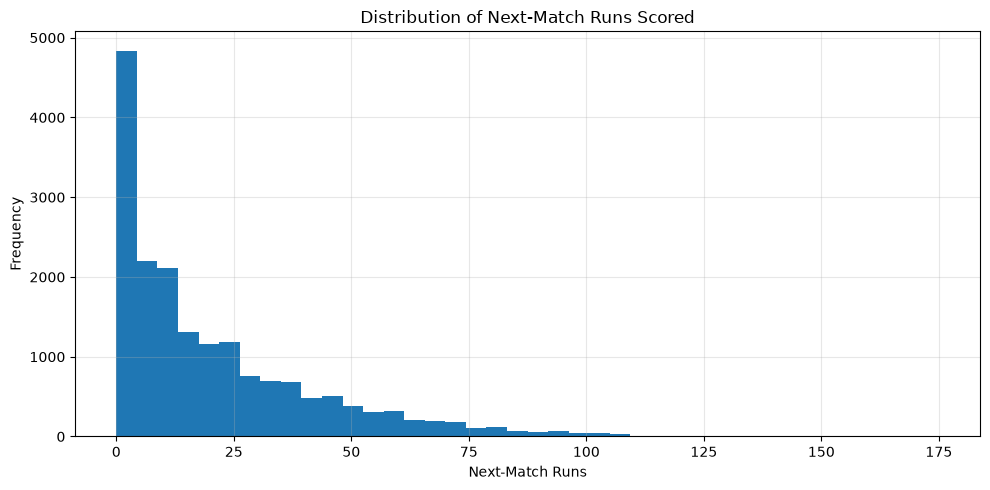

In [12]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(y, bins=40)

plt.title("Distribution of Next-Match Runs Scored")
plt.xlabel("Next-Match Runs")
plt.ylabel("Frequency")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 8. Chronological Train / Validation / Test Split

Objective:
Prepare temporally ordered datasets.

Proposed proportions:
- Training: 70%
- Validation: 15%
- Testing: 15%

Rules:
- Sort observations by date.
- Never train on observations later than the test period.
- Keep observations from the same date in the same partition.
- Preserve player history.

In [13]:
# Convert date columns to datetime
batting_df["date"] = pd.to_datetime(
    batting_df["date"],
    errors="coerce"
)

# Validate date conversion
assert batting_df["date"].notna().all(), (
    "Missing or invalid dates detected."
)

# Sort unique dates
unique_dates = np.sort(
    batting_df["date"].unique()
)

print("=" * 65)
print("CHRONOLOGICAL DATA AUDIT")
print("=" * 65)

print("Total observations:", len(batting_df))
print("Unique match dates:", len(unique_dates))
print("Earliest date:", unique_dates[0])
print("Latest date:", unique_dates[-1])

# Calculate date boundaries
n_dates = len(unique_dates)

train_end_idx = int(n_dates * 0.70)
validation_end_idx = int(n_dates * 0.85)

train_end_date = unique_dates[train_end_idx - 1]
validation_end_date = unique_dates[validation_end_idx - 1]

print("\nPROPOSED DATE BOUNDARIES")
print("Training ends:", train_end_date)
print("Validation ends:", validation_end_date)

# Create chronological partitions
train_mask = batting_df["date"] <= train_end_date

validation_mask = (
    (batting_df["date"] > train_end_date)
    & (batting_df["date"] <= validation_end_date)
)

test_mask = batting_df["date"] > validation_end_date

print("\nPROPOSED PARTITIONS")
print("Training rows:", train_mask.sum())
print("Validation rows:", validation_mask.sum())
print("Testing rows:", test_mask.sum())

# Validate partitions
assert train_mask.sum() > 0
assert validation_mask.sum() > 0
assert test_mask.sum() > 0

assert not (train_mask & validation_mask).any()
assert not (validation_mask & test_mask).any()
assert not (train_mask & test_mask).any()

assert (
    train_mask.sum()
    + validation_mask.sum()
    + test_mask.sum()
    == len(batting_df)
)

print("\nCHRONOLOGICAL SPLIT AUDIT: PASS")

CHRONOLOGICAL DATA AUDIT
Total observations: 18083
Unique match dates: 945
Earliest date: 2008-04-18T00:00:00.000000
Latest date: 2026-05-29T00:00:00.000000

PROPOSED DATE BOUNDARIES
Training ends: 2022-04-11T00:00:00.000000
Validation ends: 2024-05-01T00:00:00.000000

PROPOSED PARTITIONS
Training rows: 13045
Validation rows: 2663
Testing rows: 2375

CHRONOLOGICAL SPLIT AUDIT: PASS


In [14]:
# Validate chronological partition integrity

train_dates = batting_df.loc[train_mask, "date"]
val_dates = batting_df.loc[validation_mask, "date"]
test_dates = batting_df.loc[test_mask, "date"]

print("=" * 65)
print("PARTITION INTEGRITY VALIDATION")
print("=" * 65)

print("\nTRAINING")
print("Rows:", len(train_dates))
print("Date range:", train_dates.min(), "to", train_dates.max())

print("\nVALIDATION")
print("Rows:", len(val_dates))
print("Date range:", val_dates.min(), "to", val_dates.max())

print("\nTESTING")
print("Rows:", len(test_dates))
print("Date range:", test_dates.min(), "to", test_dates.max())

# Strict chronological ordering
assert train_dates.max() < val_dates.min()
assert val_dates.max() < test_dates.min()

# No missing dates
assert batting_df["date"].notna().all()

# Every row assigned exactly once
assert (
    train_mask.astype(int)
    + validation_mask.astype(int)
    + test_mask.astype(int)
).eq(1).all()

print("\nPARTITION INTEGRITY: PASS")

PARTITION INTEGRITY VALIDATION

TRAINING
Rows: 13045
Date range: 2008-04-18 00:00:00 to 2022-04-11 00:00:00

VALIDATION
Rows: 2663
Date range: 2022-04-12 00:00:00 to 2024-05-01 00:00:00

TESTING
Rows: 2375
Date range: 2024-05-02 00:00:00 to 2026-05-29 00:00:00

PARTITION INTEGRITY: PASS


## 10. Feature Preprocessing Audit

Target: target_next_match_runs_scored

Training: 2008–2022
Validation: 2022–2024
Testing: 2024–2026

Objectives:
1. Separate numerical and categorical features.
2. Inspect missing values by partition.
3. Identify constant features.
4. Inspect categorical cardinality.
5. Prepare leakage-safe preprocessing.

In [15]:
target_col = "target_next_match_runs_scored"

excluded_cols = [
    "match_id",
    "player",
    "date",
    "previous_match_date"
]

target_cols = [
    col for col in batting_df.columns
    if col.startswith("target_next_match_")
]

feature_cols = [
    col for col in batting_df.columns
    if col not in excluded_cols + target_cols
]

X = batting_df[feature_cols].copy()
y = batting_df[target_col].copy()

X_train = X.loc[train_mask].copy()
X_val = X.loc[validation_mask].copy()
X_test = X.loc[test_mask].copy()

y_train = y.loc[train_mask].copy()
y_val = y.loc[validation_mask].copy()
y_test = y.loc[test_mask].copy()

print("FEATURE COUNT:", len(feature_cols))
print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Testing:", X_test.shape, y_test.shape)

assert len(X_train) == len(y_train)
assert len(X_val) == len(y_val)
assert len(X_test) == len(y_test)

assert not set(target_cols).intersection(X.columns)

print("\nMODELLING DATASET PREPARATION: PASS")

FEATURE COUNT: 46
Training: (13045, 46) (13045,)
Validation: (2663, 46) (2663,)
Testing: (2375, 46) (2375,)

MODELLING DATASET PREPARATION: PASS


In [16]:
numerical_cols = X_train.select_dtypes(
    include=["number", "bool"]
).columns.tolist()

categorical_cols = X_train.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

print("Numerical features:", len(numerical_cols))
print(numerical_cols)

print("\nCategorical features:", len(categorical_cols))
print(categorical_cols)

Numerical features: 43
['is_super_over', 'runs_scored', 'balls_faced', 'fours', 'sixes', 'dismissals', 'retired_hurt_count', 'strike_rate', 'batting_average', 'innings_batted', 'not_out_innings', 'days_since_previous_match', 'previous_runs_scored', 'runs_scored_rolling_mean_3', 'runs_scored_rolling_mean_5', 'runs_scored_rolling_mean_10', 'runs_scored_expanding_mean', 'previous_balls_faced', 'balls_faced_rolling_mean_3', 'balls_faced_rolling_mean_5', 'balls_faced_rolling_mean_10', 'balls_faced_expanding_mean', 'previous_fours', 'fours_rolling_mean_3', 'fours_rolling_mean_5', 'fours_rolling_mean_10', 'fours_expanding_mean', 'previous_sixes', 'sixes_rolling_mean_3', 'sixes_rolling_mean_5', 'sixes_rolling_mean_10', 'sixes_expanding_mean', 'previous_strike_rate', 'strike_rate_rolling_mean_3', 'strike_rate_rolling_mean_5', 'strike_rate_rolling_mean_10', 'strike_rate_expanding_mean', 'previous_dismissals', 'dismissals_rolling_mean_3', 'dismissals_rolling_mean_5', 'dismissals_rolling_mean_10',

In [17]:
for name, dataset in {
    "TRAIN": X_train,
    "VALIDATION": X_val,
    "TEST": X_test
}.items():

    missing = dataset.isna().sum()
    missing = missing[missing > 0].sort_values(
        ascending=False
    )

    print(f"\n{'=' * 60}")
    print(name, "MISSING VALUE AUDIT")
    print("=" * 60)

    if missing.empty:
        print("No missing values.")
    else:
        display(
            pd.DataFrame({
                "missing_count": missing,
                "missing_percentage": (
                    missing / len(dataset) * 100
                ).round(2)
            })
        )


TRAIN MISSING VALUE AUDIT


,missing_count,missing_percentage
batting_average,2879,22.07
previous_strike_rate,564,4.32
strike_rate_rolling_mean_5,522,4.00
strike_rate_rolling_mean_3,522,4.00
strike_rate_rolling_mean_10,522,4.00
strike_rate_expanding_mean,522,4.00
fours_rolling_mean_10,520,3.99
previous_runs_scored,520,3.99
days_since_previous_match,520,3.99
balls_faced_rolling_mean_3,520,3.99



VALIDATION MISSING VALUE AUDIT


,missing_count,missing_percentage
batting_average,577,21.67
previous_strike_rate,72,2.70
fours_rolling_mean_10,65,2.44
previous_runs_scored,65,2.44
days_since_previous_match,65,2.44
runs_scored_rolling_mean_5,65,2.44
runs_scored_rolling_mean_10,65,2.44
runs_scored_expanding_mean,65,2.44
runs_scored_rolling_mean_3,65,2.44
balls_faced_rolling_mean_3,65,2.44



TEST MISSING VALUE AUDIT


,missing_count,missing_percentage
batting_average,506,21.31
previous_strike_rate,52,2.19
fours_rolling_mean_10,49,2.06
previous_runs_scored,49,2.06
days_since_previous_match,49,2.06
runs_scored_rolling_mean_5,49,2.06
runs_scored_rolling_mean_10,49,2.06
runs_scored_expanding_mean,49,2.06
runs_scored_rolling_mean_3,49,2.06
balls_faced_rolling_mean_3,49,2.06


In [18]:
# Feature cardinality and constant feature audit

print("=" * 70)
print("FEATURE CARDINALITY AUDIT")
print("=" * 70)

# Numerical feature cardinality
numerical_cardinality = X_train[numerical_cols].nunique(
    dropna=False
).sort_values()

print("\nNUMERICAL FEATURE CARDINALITY")
display(numerical_cardinality.to_frame("unique_values"))

# Constant numerical features
constant_numerical = numerical_cardinality[
    numerical_cardinality <= 1
].index.tolist()

print("\nConstant numerical features:")
print(constant_numerical)

# Categorical feature cardinality
categorical_cardinality = X_train[categorical_cols].nunique(
    dropna=False
).sort_values()

print("\nCATEGORICAL FEATURE CARDINALITY")
display(categorical_cardinality.to_frame("unique_values"))

# Constant categorical features
constant_categorical = categorical_cardinality[
    categorical_cardinality <= 1
].index.tolist()

print("\nConstant categorical features:")
print(constant_categorical)

# Season inspection
print("\nSEASON AUDIT")
print("Season dtype:", X_train["season"].dtype)
print("Unique seasons:", sorted(X_train["season"].dropna().unique()))
print("Missing seasons:", X_train["season"].isna().sum())

print("\nFEATURE CARDINALITY AUDIT COMPLETED")

FEATURE CARDINALITY AUDIT

NUMERICAL FEATURE CARDINALITY


,unique_values
is_super_over,1
innings_batted,1
retired_hurt_count,2
dismissals,2
not_out_innings,2
previous_dismissals,3
dismissals_rolling_mean_3,6
dismissals_rolling_mean_5,12
sixes,15
previous_sixes,16



Constant numerical features:
['is_super_over', 'innings_batted']

CATEGORICAL FEATURE CARDINALITY


,unique_values
match_type,1
season,15
batting_team,18



Constant categorical features:
['match_type']

SEASON AUDIT
Season dtype: str
Unique seasons: ['2007/08', '2009', '2009/10', '2011', '2012', '2013', '2014', '2015', '2016', '2017', '2018', '2019', '2020/21', '2021', '2022']
Missing seasons: 0

FEATURE CARDINALITY AUDIT COMPLETED


## 12. Final Feature Selection

Remove constant features identified using training data.

Categorical features:
- batting_team
- season

Numerical features:
- Remaining numerical predictors

Excluded:
- Identifiers
- Dates
- Targets
- Constant features

Prediction target:
target_next_match_runs_scored

In [19]:
# Remove constant features identified from training data

constant_features = [
    "is_super_over",
    "innings_batted",
    "match_type"
]

final_feature_cols = [
    col for col in feature_cols
    if col not in constant_features
]

# Rebuild X using selected features
X = batting_df[final_feature_cols].copy()

# Rebuild chronological partitions
X_train = X.loc[train_mask].copy()
X_val = X.loc[validation_mask].copy()
X_test = X.loc[test_mask].copy()

# Explicitly define categorical columns
categorical_cols = [
    "batting_team",
    "season"
]

# Remaining numerical columns
numerical_cols = [
    col for col in final_feature_cols
    if col not in categorical_cols
]

print("Removed constant features:", constant_features)

print("\nFinal feature count:", len(final_feature_cols))
print("Numerical features:", len(numerical_cols))
print("Categorical features:", len(categorical_cols))

print("\nCategorical columns:", categorical_cols)

print("\nFeature count validation:")
assert len(final_feature_cols) == 43
assert len(numerical_cols) == 41
assert len(categorical_cols) == 2

assert set(numerical_cols).isdisjoint(categorical_cols)
assert set(numerical_cols + categorical_cols) == set(final_feature_cols)

print("FINAL FEATURE SELECTION: PASS")

Removed constant features: ['is_super_over', 'innings_batted', 'match_type']

Final feature count: 43
Numerical features: 41
Categorical features: 2

Categorical columns: ['batting_team', 'season']

Feature count validation:
FINAL FEATURE SELECTION: PASS


In [20]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

In [21]:
# Numerical preprocessing
numerical_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

# Categorical preprocessing
categorical_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]
)

print("Numerical pipeline: CREATED")
print("Categorical pipeline: CREATED")

Numerical pipeline: CREATED
Categorical pipeline: CREATED


In [22]:
preprocessor = ColumnTransformer(
    transformers=[
        ("numerical", numerical_pipeline, numerical_cols),
        ("categorical", categorical_pipeline, categorical_cols)
    ],
    remainder="drop"
)

print(preprocessor)

ColumnTransformer(transformers=[('numerical',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['runs_scored', 'balls_faced', 'fours',
                                  'sixes', 'dismissals', 'retired_hurt_count',
                                  'strike_rate', 'batting_average',
                                  'not_out_innings',
                                  'days_since_previous_match',
                                  'previous_runs_scored',
                                  'runs_scored_rolling_mean_3',
                                  'runs...
                                  'fours_rolling_mean_5',
                                  'fours_rolling_mean_10',
                                  'fours_expanding_mean', 'previous_sixes',
                                 

In [23]:
# Fit transformations using training data only
X_train_processed = preprocessor.fit_transform(X_train)

# Apply the already-fitted transformations
X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)

print("=" * 65)
print("PREPROCESSING RESULTS")
print("=" * 65)

print("Training:", X_train_processed.shape)
print("Validation:", X_val_processed.shape)
print("Testing:", X_test_processed.shape)

print("\nMissing values after preprocessing:")

for name, data in {
    "Training": X_train_processed,
    "Validation": X_val_processed,
    "Testing": X_test_processed
}.items():

    if hasattr(data, "data"):
        values = data.data
    else:
        values = np.asarray(data)

    print(name, "NaN count:", np.isnan(values).sum())

print("\nPREPROCESSING COMPLETED")

PREPROCESSING RESULTS
Training: (13045, 74)
Validation: (2663, 74)
Testing: (2375, 74)

Missing values after preprocessing:
Training NaN count: 0
Validation NaN count: 0
Testing NaN count: 0

PREPROCESSING COMPLETED


In [24]:
assert X_train_processed.shape[0] == len(y_train)
assert X_val_processed.shape[0] == len(y_val)
assert X_test_processed.shape[0] == len(y_test)

assert X_train_processed.shape[1] == X_val_processed.shape[1]
assert X_train_processed.shape[1] == X_test_processed.shape[1]

assert np.isfinite(X_train_processed.data if hasattr(X_train_processed, "data") else X_train_processed).all()
assert np.isfinite(X_val_processed.data if hasattr(X_val_processed, "data") else X_val_processed).all()
assert np.isfinite(X_test_processed.data if hasattr(X_test_processed, "data") else X_test_processed).all()

print("PREPROCESSING VALIDATION: PASS")

PREPROCESSING VALIDATION: PASS


In [25]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import pandas as pd
import numpy as np

In [26]:
dummy_mean = DummyRegressor(strategy="mean")
dummy_median = DummyRegressor(strategy="median")

dummy_mean.fit(X_train_processed, y_train)
dummy_median.fit(X_train_processed, y_train)

print("Dummy Mean: TRAINED")
print("Dummy Median: TRAINED")

Dummy Mean: TRAINED
Dummy Median: TRAINED


In [27]:
def evaluate_regression_model(model, X, y, model_name):

    predictions = model.predict(X)

    mae = mean_absolute_error(y, predictions)
    rmse = np.sqrt(mean_squared_error(y, predictions))
    r2 = r2_score(y, predictions)

    return {
        "Model": model_name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    }


baseline_results = []

baseline_results.append(
    evaluate_regression_model(
        dummy_mean,
        X_val_processed,
        y_val,
        "Dummy Mean"
    )
)

baseline_results.append(
    evaluate_regression_model(
        dummy_median,
        X_val_processed,
        y_val,
        "Dummy Median"
    )
)

baseline_df = pd.DataFrame(baseline_results)

display(
    baseline_df.round(4)
)

,Model,MAE,RMSE,R2
0,Dummy Mean,17.3611,22.8352,-0.0031
1,Dummy Median,16.6831,24.2533,-0.1316


In [28]:
baseline_df.to_csv(
    PROJECT_ROOT / "data" / "processed" / "features"
    / "batting_baseline_results.csv",
    index=False
)

print("Baseline results saved successfully.")

Baseline results saved successfully.


In [29]:
from sklearn.linear_model import LinearRegression, Ridge

regression_models = {
    "Linear Regression": LinearRegression(),
    "Ridge Alpha 1": Ridge(alpha=1.0),
    "Ridge Alpha 10": Ridge(alpha=10.0),
    "Ridge Alpha 100": Ridge(alpha=100.0)
}

In [30]:
trained_models = {}

for name, model in regression_models.items():

    model.fit(X_train_processed, y_train)

    trained_models[name] = model

    print(f"{name}: TRAINED")

Linear Regression: TRAINED
Ridge Alpha 1: TRAINED
Ridge Alpha 10: TRAINED
Ridge Alpha 100: TRAINED


In [31]:
regression_results = []

for name, model in trained_models.items():

    result = evaluate_regression_model(
        model,
        X_val_processed,
        y_val,
        name
    )

    regression_results.append(result)

regression_df = pd.DataFrame(regression_results)

regression_df = regression_df.sort_values(
    by="MAE",
    ascending=True
).reset_index(drop=True)

display(regression_df.round(4))

,Model,MAE,RMSE,R2
0,Ridge Alpha 100,16.1052,21.4523,0.1147
1,Ridge Alpha 10,16.1584,21.4638,0.1137
2,Ridge Alpha 1,16.1884,21.4778,0.1126
3,Linear Regression,16.1933,21.4804,0.1124


In [32]:
all_results = pd.concat(
    [baseline_df, regression_df],
    ignore_index=True
)

all_results = all_results.sort_values(
    by="MAE",
    ascending=True
).reset_index(drop=True)

display(all_results.round(4))

,Model,MAE,RMSE,R2
0,Ridge Alpha 100,16.1052,21.4523,0.1147
1,Ridge Alpha 10,16.1584,21.4638,0.1137
2,Ridge Alpha 1,16.1884,21.4778,0.1126
3,Linear Regression,16.1933,21.4804,0.1124
4,Dummy Median,16.6831,24.2533,-0.1316
5,Dummy Mean,17.3611,22.8352,-0.0031


In [33]:
all_results.to_csv(
    PROJECT_ROOT / "data" / "processed" / "features"
    / "batting_baseline_comparison.csv",
    index=False
)

print("Baseline comparison saved successfully.")

Baseline comparison saved successfully.


## 16. Ridge Regression Hyperparameter Tuning

Objective:
Identify the best Ridge regularization strength using validation MAE.

Candidate alpha values:
0.01, 0.1, 1, 10, 100, 1000

Training:
Fit each model using training data only.

Validation:
Select the best alpha using validation MAE.

Testing:
Reserved for final evaluation.

In [34]:
ridge_alphas = [0.01, 0.1, 1, 10, 100, 1000]

ridge_tuning_results = []

for alpha in ridge_alphas:

    model = Ridge(alpha=alpha)

    model.fit(X_train_processed, y_train)

    result = evaluate_regression_model(
        model,
        X_val_processed,
        y_val,
        f"Ridge Alpha {alpha}"
    )

    result["Alpha"] = alpha

    ridge_tuning_results.append(result)

ridge_tuning_df = pd.DataFrame(ridge_tuning_results)

ridge_tuning_df = ridge_tuning_df.sort_values(
    by="MAE"
).reset_index(drop=True)

display(ridge_tuning_df.round(4))

,Model,MAE,RMSE,R2,Alpha
0,Ridge Alpha 1000,16.0786,21.4472,0.1151,1000.00
1,Ridge Alpha 100,16.1052,21.4523,0.1147,100.00
2,Ridge Alpha 10,16.1584,21.4638,0.1137,10.00
3,Ridge Alpha 1,16.1884,21.4778,0.1126,1.00
4,Ridge Alpha 0.1,16.1928,21.4801,0.1124,0.10
5,Ridge Alpha 0.01,16.1933,21.4804,0.1124,0.01


In [35]:
best_ridge_row = ridge_tuning_df.iloc[0]

best_alpha = best_ridge_row["Alpha"]

print("Best Ridge alpha:", best_alpha)
print("Validation MAE:", best_ridge_row["MAE"])
print("Validation RMSE:", best_ridge_row["RMSE"])
print("Validation R2:", best_ridge_row["R2"])

Best Ridge alpha: 1000.0
Validation MAE: 16.078628681368738
Validation RMSE: 21.447240547456435
Validation R2: 0.11510060535670397


In [36]:
# Extended Ridge regularization search

extended_alphas = [
    1000,
    3000,
    10000,
    30000,
    100000
]

extended_results = []

for alpha in extended_alphas:

    model = Ridge(alpha=alpha)

    model.fit(X_train_processed, y_train)

    result = evaluate_regression_model(
        model,
        X_val_processed,
        y_val,
        f"Ridge Alpha {alpha}"
    )

    result["Alpha"] = alpha

    extended_results.append(result)

extended_ridge_df = pd.DataFrame(extended_results)

# Combine previous and extended search results
complete_ridge_df = pd.concat(
    [ridge_tuning_df, extended_ridge_df],
    ignore_index=True
)

complete_ridge_df = (
    complete_ridge_df
    .drop_duplicates(subset=["Alpha"])
    .sort_values("MAE")
    .reset_index(drop=True)
)

display(complete_ridge_df.round(4))

best_ridge_row = complete_ridge_df.iloc[0]

print("\nBEST RIDGE CONFIGURATION")
print("Alpha:", best_ridge_row["Alpha"])
print("MAE:", best_ridge_row["MAE"])
print("RMSE:", best_ridge_row["RMSE"])
print("R2:", best_ridge_row["R2"])

,Model,MAE,RMSE,R2,Alpha
0,Ridge Alpha 1000,16.0786,21.4472,0.1151,1000.00
1,Ridge Alpha 3000,16.0856,21.4460,0.1152,3000.00
2,Ridge Alpha 100,16.1052,21.4523,0.1147,100.00
3,Ridge Alpha 10000,16.1185,21.4571,0.1143,10000.00
4,Ridge Alpha 10,16.1584,21.4638,0.1137,10.00
5,Ridge Alpha 1,16.1884,21.4778,0.1126,1.00
6,Ridge Alpha 0.1,16.1928,21.4801,0.1124,0.10
7,Ridge Alpha 0.01,16.1933,21.4804,0.1124,0.01
8,Ridge Alpha 30000,16.2015,21.5118,0.1098,30000.00
9,Ridge Alpha 100000,16.4253,21.7043,0.0938,100000.00



BEST RIDGE CONFIGURATION
Alpha: 1000.0
MAE: 16.078628681368738
RMSE: 21.447240547456435
R2: 0.11510060535670397


In [37]:
from sklearn.ensemble import RandomForestRegressor

rf_models = {
    "Random Forest 200": RandomForestRegressor(
        n_estimators=200,
        max_depth=None,
        min_samples_split=2,
        min_samples_leaf=1,
        max_features=1.0,
        random_state=42,
        n_jobs=-1
    ),

    "Random Forest Depth 15": RandomForestRegressor(
        n_estimators=200,
        max_depth=15,
        min_samples_split=5,
        min_samples_leaf=2,
        max_features=1.0,
        random_state=42,
        n_jobs=-1
    ),

    "Random Forest Depth 10": RandomForestRegressor(
        n_estimators=200,
        max_depth=10,
        min_samples_split=5,
        min_samples_leaf=3,
        max_features=1.0,
        random_state=42,
        n_jobs=-1
    )
}

print("Random Forest configurations:", len(rf_models))

Random Forest configurations: 3


In [38]:
rf_results = []
trained_rf_models = {}

for name, model in rf_models.items():

    print(f"Training {name}...")

    model.fit(X_train_processed, y_train)

    trained_rf_models[name] = model

    result = evaluate_regression_model(
        model,
        X_val_processed,
        y_val,
        name
    )

    rf_results.append(result)

rf_results_df = pd.DataFrame(rf_results)

rf_results_df = rf_results_df.sort_values(
    "MAE"
).reset_index(drop=True)

display(rf_results_df.round(4))

Training Random Forest 200...


Training Random Forest Depth 15...
Training Random Forest Depth 10...


,Model,MAE,RMSE,R2
0,Random Forest Depth 10,16.0026,21.4754,0.1128
1,Random Forest Depth 15,16.1627,21.5628,0.1055
2,Random Forest 200,16.4291,21.7297,0.0916


In [39]:
combined_results = pd.concat(
    [
        all_results,
        rf_results_df
    ],
    ignore_index=True
)

combined_results = combined_results.sort_values(
    "MAE"
).reset_index(drop=True)

display(combined_results.round(4))

,Model,MAE,RMSE,R2
0,Random Forest Depth 10,16.0026,21.4754,0.1128
1,Ridge Alpha 100,16.1052,21.4523,0.1147
2,Ridge Alpha 10,16.1584,21.4638,0.1137
3,Random Forest Depth 15,16.1627,21.5628,0.1055
4,Ridge Alpha 1,16.1884,21.4778,0.1126
5,Linear Regression,16.1933,21.4804,0.1124
6,Random Forest 200,16.4291,21.7297,0.0916
7,Dummy Median,16.6831,24.2533,-0.1316
8,Dummy Mean,17.3611,22.8352,-0.0031


In [40]:
# Combine all model results using the complete Ridge search

final_comparison = pd.concat(
    [
        baseline_df,
        complete_ridge_df[
            ["Model", "MAE", "RMSE", "R2"]
        ],
        rf_results_df
    ],
    ignore_index=True
)

final_comparison = (
    final_comparison
    .drop_duplicates(subset=["Model"])
    .sort_values("MAE")
    .reset_index(drop=True)
)

display(final_comparison.round(4))

print("\nBEST MODEL BY MAE:")
display(final_comparison.iloc[[0]])

print("\nBEST MODEL BY RMSE:")
display(
    final_comparison.loc[
        [final_comparison["RMSE"].idxmin()]
    ]
)

print("\nBEST MODEL BY R2:")
display(
    final_comparison.loc[
        [final_comparison["R2"].idxmax()]
    ]
)

,Model,MAE,RMSE,R2
0,Random Forest Depth 10,16.0026,21.4754,0.1128
1,Ridge Alpha 1000,16.0786,21.4472,0.1151
2,Ridge Alpha 3000,16.0856,21.4460,0.1152
3,Ridge Alpha 100,16.1052,21.4523,0.1147
4,Ridge Alpha 10000,16.1185,21.4571,0.1143
5,Ridge Alpha 10,16.1584,21.4638,0.1137
6,Random Forest Depth 15,16.1627,21.5628,0.1055
7,Ridge Alpha 1,16.1884,21.4778,0.1126
8,Ridge Alpha 0.1,16.1928,21.4801,0.1124
9,Ridge Alpha 0.01,16.1933,21.4804,0.1124



BEST MODEL BY MAE:


,Model,MAE,RMSE,R2
0,Random Forest Depth 10,16.002567,21.475437,0.112772



BEST MODEL BY RMSE:


,Model,MAE,RMSE,R2
2,Ridge Alpha 3000,16.085646,21.445985,0.115204



BEST MODEL BY R2:


,Model,MAE,RMSE,R2
2,Ridge Alpha 3000,16.085646,21.445985,0.115204


In [41]:
final_comparison.to_csv(
    PROJECT_ROOT / "data" / "processed" / "features"
    / "batting_model_comparison.csv",
    index=False
)

print("Complete model comparison saved.")

Complete model comparison saved.


In [42]:
from sklearn.ensemble import GradientBoostingRegressor

gb_models = {
    "Gradient Boosting 100": GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=2,
        min_samples_leaf=5,
        loss="squared_error",
        random_state=42
    ),

    "Gradient Boosting 200": GradientBoostingRegressor(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=2,
        min_samples_leaf=5,
        loss="squared_error",
        random_state=42
    ),

    "Gradient Boosting Depth 3": GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=3,
        min_samples_leaf=5,
        loss="squared_error",
        random_state=42
    )
}

print("Gradient Boosting configurations:", len(gb_models))

Gradient Boosting configurations: 3


In [43]:
gb_results = []
trained_gb_models = {}

for name, model in gb_models.items():

    print(f"Training {name}...")

    model.fit(X_train_processed, y_train)

    trained_gb_models[name] = model

    result = evaluate_regression_model(
        model,
        X_val_processed,
        y_val,
        name
    )

    gb_results.append(result)

gb_results_df = pd.DataFrame(gb_results)

gb_results_df = gb_results_df.sort_values(
    "MAE"
).reset_index(drop=True)

display(gb_results_df.round(4))

Training Gradient Boosting 100...
Training Gradient Boosting 200...
Training Gradient Boosting Depth 3...


,Model,MAE,RMSE,R2
0,Gradient Boosting 200,15.9322,21.4236,0.1171
1,Gradient Boosting 100,15.9536,21.4247,0.1170
2,Gradient Boosting Depth 3,15.9619,21.4196,0.1174


In [44]:
all_model_results = pd.concat(
    [
        final_comparison,
        gb_results_df
    ],
    ignore_index=True
)

all_model_results = (
    all_model_results
    .drop_duplicates(subset=["Model"])
    .sort_values("MAE")
    .reset_index(drop=True)
)

display(all_model_results.round(4))

,Model,MAE,RMSE,R2
0,Gradient Boosting 200,15.9322,21.4236,0.1171
1,Gradient Boosting 100,15.9536,21.4247,0.1170
2,Gradient Boosting Depth 3,15.9619,21.4196,0.1174
3,Random Forest Depth 10,16.0026,21.4754,0.1128
4,Ridge Alpha 1000,16.0786,21.4472,0.1151
5,Ridge Alpha 3000,16.0856,21.4460,0.1152
6,Ridge Alpha 100,16.1052,21.4523,0.1147
7,Ridge Alpha 10000,16.1185,21.4571,0.1143
8,Ridge Alpha 10,16.1584,21.4638,0.1137
9,Random Forest Depth 15,16.1627,21.5628,0.1055


In [45]:
all_model_results.to_csv(
    PROJECT_ROOT / "data" / "processed" / "features"
    / "batting_all_model_comparison.csv",
    index=False
)

print("Gradient Boosting comparison saved.")

Gradient Boosting comparison saved.


In [46]:
from sklearn.ensemble import GradientBoostingRegressor

gb_tuning_configs = [
    {"n_estimators": 100, "learning_rate": 0.03, "max_depth": 2},
    {"n_estimators": 200, "learning_rate": 0.03, "max_depth": 2},
    {"n_estimators": 300, "learning_rate": 0.03, "max_depth": 2},
    {"n_estimators": 100, "learning_rate": 0.05, "max_depth": 2},
    {"n_estimators": 200, "learning_rate": 0.05, "max_depth": 2},
    {"n_estimators": 300, "learning_rate": 0.05, "max_depth": 2},
    {"n_estimators": 100, "learning_rate": 0.05, "max_depth": 3},
    {"n_estimators": 200, "learning_rate": 0.05, "max_depth": 3},
    {"n_estimators": 100, "learning_rate": 0.10, "max_depth": 2},
]

gb_tuning_results = []
tuned_gb_models = {}

for config in gb_tuning_configs:

    model_name = (
        f"GB_n{config['n_estimators']}"
        f"_lr{config['learning_rate']}"
        f"_depth{config['max_depth']}"
    )

    model = GradientBoostingRegressor(
        **config,
        min_samples_leaf=5,
        loss="squared_error",
        random_state=42
    )

    print("Training:", model_name)

    model.fit(X_train_processed, y_train)

    tuned_gb_models[model_name] = model

    result = evaluate_regression_model(
        model,
        X_val_processed,
        y_val,
        model_name
    )

    result.update(config)

    gb_tuning_results.append(result)

gb_tuning_df = pd.DataFrame(gb_tuning_results)

gb_tuning_df = gb_tuning_df.sort_values(
    "MAE"
).reset_index(drop=True)

display(gb_tuning_df.round(4))

Training: GB_n100_lr0.03_depth2
Training: GB_n200_lr0.03_depth2
Training: GB_n300_lr0.03_depth2
Training: GB_n100_lr0.05_depth2
Training: GB_n200_lr0.05_depth2
Training: GB_n300_lr0.05_depth2
Training: GB_n100_lr0.05_depth3
Training: GB_n200_lr0.05_depth3
Training: GB_n100_lr0.1_depth2


,Model,MAE,RMSE,R2,n_estimators,learning_rate,max_depth
0,GB_n200_lr0.05_depth2,15.9322,21.4236,0.1171,200,0.05,2
1,GB_n100_lr0.1_depth2,15.9333,21.4230,0.1171,100,0.10,2
2,GB_n300_lr0.03_depth2,15.9354,21.4192,0.1174,300,0.03,2
3,GB_n200_lr0.03_depth2,15.9434,21.4172,0.1176,200,0.03,2
4,GB_n300_lr0.05_depth2,15.9473,21.4395,0.1157,300,0.05,2
5,GB_n100_lr0.05_depth2,15.9536,21.4247,0.1170,100,0.05,2
6,GB_n100_lr0.05_depth3,15.9619,21.4196,0.1174,100,0.05,3
7,GB_n200_lr0.05_depth3,15.9840,21.4756,0.1128,200,0.05,3
8,GB_n100_lr0.03_depth2,16.0123,21.4679,0.1134,100,0.03,2


In [47]:
best_gb_row = gb_tuning_df.iloc[0]

print("BEST GRADIENT BOOSTING CONFIGURATION")
print("Model:", best_gb_row["Model"])
print("MAE:", best_gb_row["MAE"])
print("RMSE:", best_gb_row["RMSE"])
print("R2:", best_gb_row["R2"])
print("Parameters:")
print(
    best_gb_row[
        ["n_estimators", "learning_rate", "max_depth"]
    ]
)

BEST GRADIENT BOOSTING CONFIGURATION
Model: GB_n200_lr0.05_depth2
MAE: 15.932161069880726
RMSE: 21.423562178375967
R2: 0.1170534354260585
Parameters:
n_estimators      200
learning_rate    0.05
max_depth           2
Name: 0, dtype: object


In [48]:
import sys
import subprocess

print("Python executable:")
print(sys.executable)

print("\nPython version:")
print(sys.version)

print("\nPip associated with this kernel:")
subprocess.run(
    [sys.executable, "-m", "pip", "--version"],
    check=False
)

Python executable:
c:\Users\Vinod\anaconda3\envs\ipl-analytics-v2\python.exe

Python version:
3.12.16 | packaged by Anaconda, Inc. | (main, Oct 26 2026, 20:13:05) [MSC v.1942 64 bit (AMD64)]

Pip associated with this kernel:


CompletedProcess(args=['c:\\Users\\Vinod\\anaconda3\\envs\\ipl-analytics-v2\\python.exe', '-m', 'pip', '--version'], returncode=0)

In [49]:
import sys
import subprocess

subprocess.check_call([
    sys.executable,
    "-m",
    "pip",
    "install",
    "xgboost"
])

0

In [50]:
import xgboost

print("XGBoost version:", xgboost.__version__)
print("Installation: PASS")

XGBoost version: 3.4.1
Installation: PASS


In [51]:
from xgboost import XGBRegressor

xgb_models = {
    "XGBoost 300": XGBRegressor(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=3,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_lambda=1,
        objective="reg:squarederror",
        eval_metric="mae",
        random_state=42,
        n_jobs=-1
    ),

    "XGBoost 500": XGBRegressor(
        n_estimators=500,
        learning_rate=0.03,
        max_depth=3,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_lambda=1,
        objective="reg:squarederror",
        eval_metric="mae",
        random_state=42,
        n_jobs=-1
    ),

    "XGBoost Depth 4": XGBRegressor(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=4,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_lambda=1,
        objective="reg:squarederror",
        eval_metric="mae",
        random_state=42,
        n_jobs=-1
    )
}

print("XGBoost configurations:", len(xgb_models))

XGBoost configurations: 3


In [52]:
xgb_results = []
trained_xgb_models = {}

for name, model in xgb_models.items():

    print(f"Training {name}...")

    model.fit(X_train_processed, y_train)

    trained_xgb_models[name] = model

    result = evaluate_regression_model(
        model,
        X_val_processed,
        y_val,
        name
    )

    xgb_results.append(result)

xgb_results_df = pd.DataFrame(xgb_results)

xgb_results_df = xgb_results_df.sort_values(
    "MAE"
).reset_index(drop=True)

display(xgb_results_df.round(4))

Training XGBoost 300...
Training XGBoost 500...
Training XGBoost Depth 4...


,Model,MAE,RMSE,R2
0,XGBoost 500,15.9914,21.4706,0.1132
1,XGBoost 300,16.0647,21.5550,0.1062
2,XGBoost Depth 4,16.1436,21.6370,0.0994


In [53]:
complete_model_results = pd.concat(
    [
        all_model_results,
        xgb_results_df
    ],
    ignore_index=True
)

complete_model_results = (
    complete_model_results
    .drop_duplicates(subset=["Model"])
    .sort_values("MAE")
    .reset_index(drop=True)
)

display(complete_model_results.round(4))

,Model,MAE,RMSE,R2
0,Gradient Boosting 200,15.9322,21.4236,0.1171
1,Gradient Boosting 100,15.9536,21.4247,0.1170
2,Gradient Boosting Depth 3,15.9619,21.4196,0.1174
3,XGBoost 500,15.9914,21.4706,0.1132
4,Random Forest Depth 10,16.0026,21.4754,0.1128
5,XGBoost 300,16.0647,21.5550,0.1062
6,Ridge Alpha 1000,16.0786,21.4472,0.1151
7,Ridge Alpha 3000,16.0856,21.4460,0.1152
8,Ridge Alpha 100,16.1052,21.4523,0.1147
9,Ridge Alpha 10000,16.1185,21.4571,0.1143


In [54]:
complete_model_results.to_csv(
    PROJECT_ROOT / "data" / "processed" / "features"
    / "batting_complete_model_comparison.csv",
    index=False
)

print("Complete model comparison saved successfully.")

Complete model comparison saved successfully.


In [55]:
best_gb_model = trained_gb_models["Gradient Boosting 200"]
best_xgb_model = trained_xgb_models["XGBoost 500"]

gb_val_predictions = best_gb_model.predict(
    X_val_processed
)

xgb_val_predictions = best_xgb_model.predict(
    X_val_processed
)

print("Gradient Boosting predictions:", len(gb_val_predictions))
print("XGBoost predictions:", len(xgb_val_predictions))
print("Actual validation observations:", len(y_val))

Gradient Boosting predictions: 2663
XGBoost predictions: 2663
Actual validation observations: 2663


In [56]:
residual_df = pd.DataFrame({
    "Actual": np.asarray(y_val),
    "GB_Predicted": gb_val_predictions,
    "XGB_Predicted": xgb_val_predictions
})

residual_df["GB_Residual"] = (
    residual_df["Actual"] - residual_df["GB_Predicted"]
)

residual_df["XGB_Residual"] = (
    residual_df["Actual"] - residual_df["XGB_Predicted"]
)

display(residual_df.head(10))

,Actual,GB_Predicted,XGB_Predicted,GB_Residual,XGB_Residual
0,14.0,18.279623,16.697824,-4.279623,-2.697824
1,4.0,15.415135,14.962729,-11.415135,-10.962729
2,15.0,15.374983,14.607941,-0.374983,0.392059
3,8.0,15.542403,15.291189,-7.542403,-7.291189
4,0.0,17.457337,17.990383,-17.457337,-17.990383
5,18.0,14.441926,14.389357,3.558074,3.610643
6,23.0,14.085115,13.767650,8.914885,9.232350
7,30.0,15.003788,14.379476,14.996212,15.620524
8,5.0,15.625670,15.321376,-10.625670,-10.321376
9,1.0,15.396097,15.613254,-14.396097,-14.613254


In [57]:
residual_summary = pd.DataFrame({
    "Model": ["Gradient Boosting 200", "XGBoost 500"],
    "Mean Residual": [
        residual_df["GB_Residual"].mean(),
        residual_df["XGB_Residual"].mean()
    ],
    "Residual Std": [
        residual_df["GB_Residual"].std(),
        residual_df["XGB_Residual"].std()
    ],
    "Mean Absolute Error": [
        residual_df["GB_Residual"].abs().mean(),
        residual_df["XGB_Residual"].abs().mean()
    ]
})

display(residual_summary.round(4))

,Model,Mean Residual,Residual Std,Mean Absolute Error
0,Gradient Boosting 200,1.0860,21.4000,15.9322
1,XGBoost 500,0.8719,21.4569,15.9914


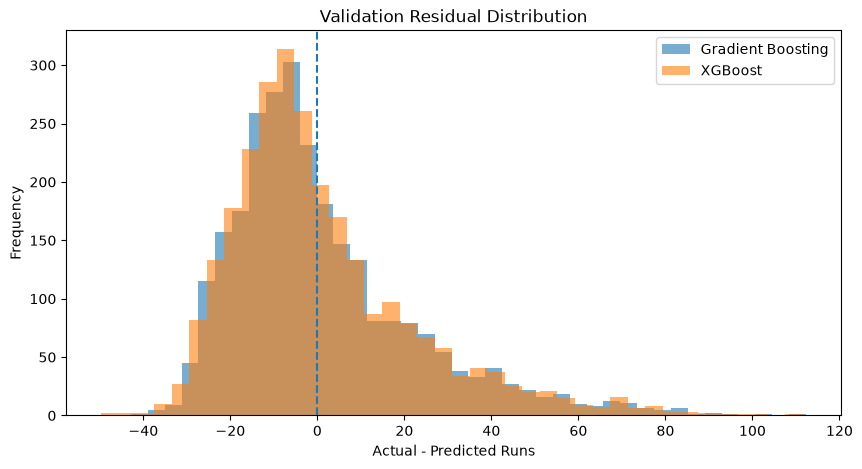

In [58]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(
    residual_df["GB_Residual"],
    bins=40,
    alpha=0.6,
    label="Gradient Boosting"
)

plt.hist(
    residual_df["XGB_Residual"],
    bins=40,
    alpha=0.6,
    label="XGBoost"
)

plt.axvline(0, linestyle="--")

plt.title("Validation Residual Distribution")
plt.xlabel("Actual - Predicted Runs")
plt.ylabel("Frequency")
plt.legend()
plt.show()

In [59]:
residual_df["Run_Category"] = pd.cut(
    residual_df["Actual"],
    bins=[-1, 9, 19, 29, 49, 99, float("inf")],
    labels=[
        "0-9",
        "10-19",
        "20-29",
        "30-49",
        "50-99",
        "100+"
    ]
)

display(
    residual_df[
        ["Actual", "GB_Predicted", "XGB_Predicted", "Run_Category"]
    ].head()
)

,Actual,GB_Predicted,XGB_Predicted,Run_Category
0,14.0,18.279623,16.697824,10-19
1,4.0,15.415135,14.962729,0-9
2,15.0,15.374983,14.607941,10-19
3,8.0,15.542403,15.291189,0-9
4,0.0,17.457337,17.990383,0-9


In [60]:
error_by_category = (
    residual_df
    .groupby("Run_Category", observed=False)
    .apply(
        lambda group: pd.Series({
            "Observations": len(group),

            "GB_MAE": (
                group["Actual"] - group["GB_Predicted"]
            ).abs().mean(),

            "XGB_MAE": (
                group["Actual"] - group["XGB_Predicted"]
            ).abs().mean(),

            "GB_Mean_Residual": group["GB_Residual"].mean(),

            "XGB_Mean_Residual": group["XGB_Residual"].mean()
        }),
        include_groups=False
    )
    .reset_index()
)

display(error_by_category.round(3))

,Run_Category,Observations,GB_MAE,XGB_MAE,GB_Mean_Residual,XGB_Mean_Residual
0,0-9,1113.0,14.361,14.476,-14.318,-14.423
1,10-19,476.0,7.679,8.045,-5.794,-6.061
2,20-29,352.0,5.861,6.133,2.771,2.723
3,30-49,394.0,15.666,15.387,15.376,14.921
4,50-99,299.0,40.848,40.422,40.848,40.422
5,100+,29.0,80.652,80.556,80.652,80.556


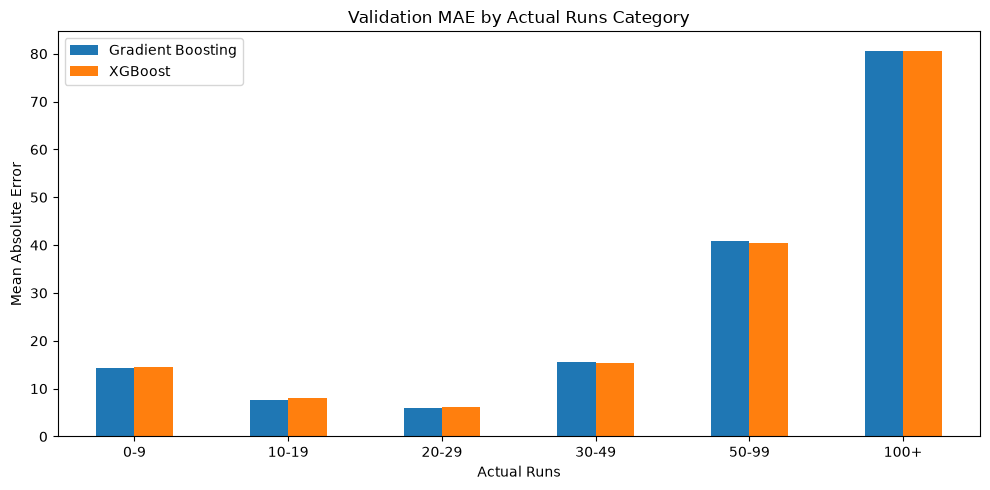

In [61]:
error_by_category.plot(
    x="Run_Category",
    y=["GB_MAE", "XGB_MAE"],
    kind="bar",
    figsize=(10, 5)
)

plt.title("Validation MAE by Actual Runs Category")
plt.xlabel("Actual Runs")
plt.ylabel("Mean Absolute Error")
plt.xticks(rotation=0)
plt.legend(["Gradient Boosting", "XGBoost"])
plt.tight_layout()
plt.show()

In [62]:
category_diagnostics = (
    residual_df
    .groupby("Run_Category", observed=False)
    .apply(
        lambda group: pd.Series({
            "Observations": len(group),

            "GB_MAE": (
                group["Actual"] - group["GB_Predicted"]
            ).abs().mean(),

            "XGB_MAE": (
                group["Actual"] - group["XGB_Predicted"]
            ).abs().mean(),

            "GB_Mean_Residual": group["GB_Residual"].mean(),

            "XGB_Mean_Residual": group["XGB_Residual"].mean(),

            "GB_Underprediction_%": (
                group["GB_Residual"] > 0
            ).mean() * 100,

            "XGB_Underprediction_%": (
                group["XGB_Residual"] > 0
            ).mean() * 100
        })
    )
    .reset_index()
)

display(category_diagnostics.round(3))

,Run_Category,Observations,GB_MAE,XGB_MAE,GB_Mean_Residual,XGB_Mean_Residual,GB_Underprediction_%,XGB_Underprediction_%
0,0-9,1113.0,14.361,14.476,-14.318,-14.423,1.527,1.617
1,10-19,476.0,7.679,8.045,-5.794,-6.061,22.479,23.739
2,20-29,352.0,5.861,6.133,2.771,2.723,66.193,64.489
3,30-49,394.0,15.666,15.387,15.376,14.921,97.716,95.685
4,50-99,299.0,40.848,40.422,40.848,40.422,100.000,100.000
5,100+,29.0,80.652,80.556,80.652,80.556,100.000,100.000


In [63]:
print("MODEL TYPE:", type(best_gb_model).__name__)

print("MODEL INPUT FEATURES:", best_gb_model.n_features_in_)

print(
    "HAS FEATURE NAMES:",
    hasattr(best_gb_model, "feature_names_in_")
)

print("TRAINING DATA SHAPE:", X_train.shape)

print("NUMERICAL FEATURES:", len(numerical_cols))
print("CATEGORICAL FEATURES:", len(categorical_cols))

MODEL TYPE: GradientBoostingRegressor
MODEL INPUT FEATURES: 74
HAS FEATURE NAMES: False
TRAINING DATA SHAPE: (13045, 43)
NUMERICAL FEATURES: 41
CATEGORICAL FEATURES: 2


In [64]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

print("FITTED PREPROCESSING OBJECTS")
print("=" * 65)

for name, obj in globals().copy().items():

    if isinstance(obj, (ColumnTransformer, Pipeline)):
        print(f"\nVariable: {name}")
        print("Type:", type(obj).__name__)

        if hasattr(obj, "get_feature_names_out"):
            try:
                feature_names = obj.get_feature_names_out()
                print("Output feature count:", len(feature_names))
                print("Sample names:", feature_names[:10])
            except Exception as e:
                print("Feature-name extraction error:", repr(e))

FITTED PREPROCESSING OBJECTS

Variable: numerical_pipeline
Type: Pipeline
Feature-name extraction error: NotFittedError("This SimpleImputer instance is not fitted yet. Call 'fit' with appropriate arguments before using this estimator.")

Variable: categorical_pipeline
Type: Pipeline
Feature-name extraction error: NotFittedError("This SimpleImputer instance is not fitted yet. Call 'fit' with appropriate arguments before using this estimator.")

Variable: preprocessor
Type: ColumnTransformer
Output feature count: 74
Sample names: ['numerical__runs_scored' 'numerical__balls_faced' 'numerical__fours'
 'numerical__sixes' 'numerical__dismissals'
 'numerical__retired_hurt_count' 'numerical__strike_rate'
 'numerical__batting_average' 'numerical__not_out_innings'
 'numerical__days_since_previous_match']


In [65]:
# Extract feature names from the fitted ColumnTransformer

transformed_feature_names = preprocessor.get_feature_names_out()

# Get feature importance from the fitted Gradient Boosting model
gb_importance = pd.DataFrame({
    "Feature": transformed_feature_names,
    "Importance": best_gb_model.feature_importances_
})

# Sort by importance
gb_importance = gb_importance.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

# Validate dimensions
assert len(transformed_feature_names) == best_gb_model.n_features_in_
assert len(gb_importance) == 74

print("FEATURE IMPORTANCE VALIDATION: PASS")
print("Total transformed features:", len(gb_importance))

print("\nTOP 20 GRADIENT BOOSTING FEATURES")
display(gb_importance.head(20).round(5))

FEATURE IMPORTANCE VALIDATION: PASS
Total transformed features: 74

TOP 20 GRADIENT BOOSTING FEATURES


,Feature,Importance
0,numerical__runs_scored_expanding_mean,0.17680
1,numerical__fours_expanding_mean,0.16204
2,numerical__balls_faced_rolling_mean_10,0.15502
3,numerical__balls_faced_expanding_mean,0.12741
4,numerical__balls_faced_rolling_mean_3,0.04358
5,numerical__runs_scored_rolling_mean_10,0.04260
6,numerical__matches_played_before,0.04080
7,numerical__dismissals_expanding_mean,0.02966
8,numerical__balls_faced,0.02598
9,numerical__fours_rolling_mean_5,0.02247


In [66]:
# Display complete feature names without truncation

pd.set_option("display.max_colwidth", None)
pd.set_option("display.max_rows", 25)

print("TOP 20 GRADIENT BOOSTING FEATURES")

display(
    gb_importance.head(20).to_string(index=False)
)

TOP 20 GRADIENT BOOSTING FEATURES


'                               Feature  Importance\n numerical__runs_scored_expanding_mean    0.176805\n       numerical__fours_expanding_mean    0.162043\nnumerical__balls_faced_rolling_mean_10    0.155017\n numerical__balls_faced_expanding_mean    0.127412\n numerical__balls_faced_rolling_mean_3    0.043578\nnumerical__runs_scored_rolling_mean_10    0.042603\n      numerical__matches_played_before    0.040800\n  numerical__dismissals_expanding_mean    0.029656\n                numerical__balls_faced    0.025976\n       numerical__fours_rolling_mean_5    0.022474\n       numerical__sixes_expanding_mean    0.021762\n                      numerical__fours    0.016555\n numerical__balls_faced_rolling_mean_5    0.013821\n  numerical__dismissals_rolling_mean_5    0.011236\n            numerical__batting_average    0.009902\n numerical__strike_rate_expanding_mean    0.009401\n      numerical__sixes_rolling_mean_10    0.009152\n      numerical__fours_rolling_mean_10    0.009038\n       nume

In [67]:
# Group related features

def get_feature_group(feature):

    feature = feature.replace("numerical__", "")

    if "runs_scored" in feature:
        return "Runs History"

    elif "balls_faced" in feature:
        return "Balls Faced History"

    elif "fours" in feature:
        return "Fours History"

    elif "sixes" in feature:
        return "Sixes History"

    elif "strike_rate" in feature:
        return "Strike Rate History"

    elif "dismissals" in feature:
        return "Dismissals History"

    elif "matches_played" in feature:
        return "Player Experience"

    elif "batting_average" in feature:
        return "Batting Average"

    elif "batting_team" in feature:
        return "Batting Team"

    elif "season" in feature:
        return "Season"

    else:
        return "Other Features"


grouped_importance = gb_importance.copy()

grouped_importance["Feature_Group"] = (
    grouped_importance["Feature"].apply(get_feature_group)
)

grouped_importance = (
    grouped_importance.groupby("Feature_Group")["Importance"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

grouped_importance["Importance_Percentage"] = (
    grouped_importance["Importance"] * 100
)

print("GROUPED FEATURE IMPORTANCE")

display(grouped_importance.round(4))

assert abs(grouped_importance["Importance"].sum() - 1.0) < 1e-6

print("GROUPED IMPORTANCE VALIDATION: PASS")

GROUPED FEATURE IMPORTANCE


,Feature_Group,Importance,Importance_Percentage
0,Balls Faced History,0.3717,37.1692
1,Runs History,0.2399,23.9851
2,Fours History,0.2170,21.6955
3,Dismissals History,0.0483,4.8258
4,Player Experience,0.0408,4.0800
5,Sixes History,0.0357,3.5733
6,Strike Rate History,0.0254,2.5371
7,Batting Average,0.0099,0.9902
8,Other Features,0.0086,0.8584
9,Batting Team,0.0020,0.2034


GROUPED IMPORTANCE VALIDATION: PASS


In [68]:
from sklearn.inspection import permutation_importance

# Transform validation data using the fitted preprocessor
X_val_transformed = preprocessor.transform(X_val)

# Validate feature dimensions
assert X_val_transformed.shape[1] == best_gb_model.n_features_in_

# Calculate permutation importance
permutation_result = permutation_importance(
    best_gb_model,
    X_val_transformed,
    y_val,
    scoring="neg_mean_absolute_error",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

# Build importance report
permutation_df = pd.DataFrame({
    "Feature": preprocessor.get_feature_names_out(),
    "Importance_Mean": permutation_result.importances_mean,
    "Importance_Std": permutation_result.importances_std
}).sort_values(
    "Importance_Mean",
    ascending=False
).reset_index(drop=True)

print("TOP 20 VALIDATION PERMUTATION IMPORTANCE")

display(permutation_df.head(20).round(5))

print("\nPERMUTATION IMPORTANCE VALIDATION: PASS")

TOP 20 VALIDATION PERMUTATION IMPORTANCE


,Feature,Importance_Mean,Importance_Std
0,numerical__runs_scored_expanding_mean,0.16208,0.03173
1,numerical__fours_expanding_mean,0.12602,0.02043
2,numerical__balls_faced_expanding_mean,0.11693,0.01630
3,numerical__balls_faced_rolling_mean_10,0.11664,0.02019
4,numerical__sixes_expanding_mean,0.09065,0.01168
5,numerical__matches_played_before,0.07824,0.01909
6,numerical__balls_faced,0.06610,0.01021
7,numerical__balls_faced_rolling_mean_3,0.05781,0.01558
8,numerical__runs_scored_rolling_mean_10,0.05318,0.00869
9,numerical__balls_faced_rolling_mean_5,0.04599,0.00476



PERMUTATION IMPORTANCE VALIDATION: PASS


In [69]:
# Feature correlation and redundancy audit

correlation_matrix = X_train[numerical_cols].corr().abs()

upper_triangle = correlation_matrix.where(
    np.triu(
        np.ones(correlation_matrix.shape),
        k=1
    ).astype(bool)
)

high_correlation_pairs = (
    upper_triangle
    .stack()
    .reset_index()
)

high_correlation_pairs.columns = [
    "Feature_1",
    "Feature_2",
    "Absolute_Correlation"
]

high_correlation_pairs = (
    high_correlation_pairs
    .query("Absolute_Correlation >= 0.90")
    .sort_values(
        "Absolute_Correlation",
        ascending=False
    )
    .reset_index(drop=True)
)

print("HIGH CORRELATION FEATURE PAIRS")
display(high_correlation_pairs)

print("\nTotal high-correlation pairs:",
      len(high_correlation_pairs))

HIGH CORRELATION FEATURE PAIRS


,Feature_1,Feature_2,Absolute_Correlation
0,runs_scored,batting_average,1.000000
1,dismissals,not_out_innings,1.000000
2,runs_scored_expanding_mean,balls_faced_expanding_mean,0.952355
3,runs_scored_rolling_mean_10,balls_faced_rolling_mean_10,0.947491
4,runs_scored_rolling_mean_5,balls_faced_rolling_mean_5,0.941657
5,runs_scored_rolling_mean_3,balls_faced_rolling_mean_3,0.936063
6,runs_scored,balls_faced,0.929938
7,previous_runs_scored,previous_balls_faced,0.929556
8,balls_faced,batting_average,0.927947
9,balls_faced_rolling_mean_10,balls_faced_expanding_mean,0.908467



Total high-correlation pairs: 12


In [70]:
# Verify potentially redundant batting features

print("=" * 65)
print("EXACT FEATURE REDUNDANCY AUDIT")
print("=" * 65)

# 1. Runs scored vs batting average
runs_batting_avg = X_train[
    ["runs_scored", "batting_average"]
].dropna()

print("\nRUNS SCORED VS BATTING AVERAGE")
print(
    "Exact equality percentage:",
    (
        runs_batting_avg["runs_scored"]
        == runs_batting_avg["batting_average"]
    ).mean() * 100
)

# 2. Dismissals vs not-out innings
dismissal_notout = X_train[
    ["dismissals", "not_out_innings"]
].dropna()

print("\nDISMISSALS VS NOT-OUT INNINGS")
print(
    "Unique sums:",
    (
        dismissal_notout["dismissals"]
        + dismissal_notout["not_out_innings"]
    ).value_counts().to_dict()
)

# 3. Constant feature verification
print("\nUNIQUE VALUES")
for col in ["dismissals", "not_out_innings", "batting_average"]:
    print(col, ":", X_train[col].nunique(dropna=True))

print("\nREDUNDANCY AUDIT COMPLETED")

EXACT FEATURE REDUNDANCY AUDIT

RUNS SCORED VS BATTING AVERAGE
Exact equality percentage: 100.0

DISMISSALS VS NOT-OUT INNINGS
Unique sums: {1: 13045}

UNIQUE VALUES
dismissals : 2
not_out_innings : 2
batting_average : 116

REDUNDANCY AUDIT COMPLETED


In [71]:
# Remove verified redundant batting features

redundant_features = [
    "batting_average",
    "not_out_innings"
]

X_train_reduced = X_train.drop(
    columns=redundant_features
)

X_val_reduced = X_val.drop(
    columns=redundant_features
)

X_test_reduced = X_test.drop(
    columns=redundant_features
)

print("Original feature count:", X_train.shape[1])
print("Reduced feature count:", X_train_reduced.shape[1])

print("\nTraining shape:", X_train_reduced.shape)
print("Validation shape:", X_val_reduced.shape)
print("Testing shape:", X_test_reduced.shape)

assert X_train_reduced.shape[1] == X_train.shape[1] - 2
assert list(X_train_reduced.columns) == list(X_val_reduced.columns)
assert list(X_train_reduced.columns) == list(X_test_reduced.columns)

print("\nREDUNDANT FEATURE REMOVAL: PASS")

Original feature count: 43
Reduced feature count: 41

Training shape: (13045, 41)
Validation shape: (2663, 41)
Testing shape: (2375, 41)

REDUNDANT FEATURE REMOVAL: PASS


In [72]:
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Identify feature types from reduced training data
numerical_cols_reduced = X_train_reduced.select_dtypes(
    include=["number", "bool"]
).columns.tolist()

categorical_cols_reduced = X_train_reduced.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

# Rebuild preprocessing without fitting on validation/test data
preprocessor_reduced = ColumnTransformer(
    transformers=[
        ("numerical", clone(numerical_pipeline), numerical_cols_reduced),
        ("categorical", clone(categorical_pipeline), categorical_cols_reduced)
    ],
    remainder="drop"
)

print("Numerical features:", len(numerical_cols_reduced))
print("Categorical features:", len(categorical_cols_reduced))
print("Total features:", 
      len(numerical_cols_reduced) + len(categorical_cols_reduced))

assert (
    len(numerical_cols_reduced) + len(categorical_cols_reduced)
    == X_train_reduced.shape[1]
)

print("REDUCED PREPROCESSOR AUDIT: PASS")

Numerical features: 39
Categorical features: 2
Total features: 41
REDUCED PREPROCESSOR AUDIT: PASS


In [73]:
gb_reduced_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor_reduced),
        (
            "model",
            GradientBoostingRegressor(
                n_estimators=200,
                learning_rate=0.05,
                max_depth=2,
                random_state=42
            )
        )
    ]
)

gb_reduced_pipeline.fit(X_train_reduced, y_train)

print("REDUCED GRADIENT BOOSTING TRAINING: PASS")

REDUCED GRADIENT BOOSTING TRAINING: PASS


In [74]:
y_val_pred_reduced = gb_reduced_pipeline.predict(X_val_reduced)

reduced_gb_results = {
    "Model": "Gradient Boosting - 41 Features",
    "MAE": mean_absolute_error(y_val, y_val_pred_reduced),
    "RMSE": np.sqrt(mean_squared_error(y_val, y_val_pred_reduced)),
    "R2": r2_score(y_val, y_val_pred_reduced)
}

display(pd.DataFrame([reduced_gb_results]).round(4))

,Model,MAE,RMSE,R2
0,Gradient Boosting - 41 Features,15.939,21.4105,0.1181


In [75]:
# Training vs validation performance audit

y_train_pred_reduced = gb_reduced_pipeline.predict(
    X_train_reduced
)

y_val_pred_reduced = gb_reduced_pipeline.predict(
    X_val_reduced
)

overfitting_results = pd.DataFrame([
    {
        "Dataset": "Training",
        "MAE": mean_absolute_error(
            y_train, y_train_pred_reduced
        ),
        "RMSE": np.sqrt(mean_squared_error(
            y_train, y_train_pred_reduced
        )),
        "R2": r2_score(y_train, y_train_pred_reduced)
    },
    {
        "Dataset": "Validation",
        "MAE": mean_absolute_error(
            y_val, y_val_pred_reduced
        ),
        "RMSE": np.sqrt(mean_squared_error(
            y_val, y_val_pred_reduced
        )),
        "R2": r2_score(y_val, y_val_pred_reduced)
    }
])

display(overfitting_results.round(4))

mae_gap = (
    overfitting_results.loc[1, "MAE"]
    - overfitting_results.loc[0, "MAE"]
)

print("\nMAE generalisation gap:", round(mae_gap, 4))

,Dataset,MAE,RMSE,R2
0,Training,14.6323,19.4449,0.1569
1,Validation,15.9390,21.4105,0.1181



MAE generalisation gap: 1.3066


In [76]:
# Residual analysis: reduced Gradient Boosting

train_residuals = y_train - y_train_pred_reduced
val_residuals = y_val - y_val_pred_reduced

residual_comparison = pd.DataFrame([
    {
        "Dataset": "Training",
        "Mean_Residual": np.mean(train_residuals),
        "Median_Residual": np.median(train_residuals),
        "Residual_Std": np.std(train_residuals),
        "Mean_Absolute_Error": mean_absolute_error(
            y_train, y_train_pred_reduced
        )
    },
    {
        "Dataset": "Validation",
        "Mean_Residual": np.mean(val_residuals),
        "Median_Residual": np.median(val_residuals),
        "Residual_Std": np.std(val_residuals),
        "Mean_Absolute_Error": mean_absolute_error(
            y_val, y_val_pred_reduced
        )
    }
])

display(residual_comparison.round(4))

print("\nRESIDUAL INTERPRETATION")
print("Positive residual: Model underpredicts.")
print("Negative residual: Model overpredicts.")

,Dataset,Mean_Residual,Median_Residual,Residual_Std,Mean_Absolute_Error
0,Training,-0.0000,-4.602,19.4449,14.6323
1,Validation,1.0492,-4.279,21.3848,15.9390



RESIDUAL INTERPRETATION
Positive residual: Model underpredicts.
Negative residual: Model overpredicts.


In [77]:
# Residual analysis by actual next-match runs category

residual_analysis_df = pd.DataFrame({
    "Actual": np.asarray(y_val),
    "Predicted": np.asarray(y_val_pred_reduced)
})

residual_analysis_df["Residual"] = (
    residual_analysis_df["Actual"]
    - residual_analysis_df["Predicted"]
)

residual_analysis_df["Absolute_Error"] = (
    residual_analysis_df["Residual"].abs()
)

bins = [-np.inf, 9, 19, 29, 49, 99, np.inf]

labels = [
    "0-9",
    "10-19",
    "20-29",
    "30-49",
    "50-99",
    "100+"
]

residual_analysis_df["Run_Category"] = pd.cut(
    residual_analysis_df["Actual"],
    bins=bins,
    labels=labels
)

category_residual_summary = (
    residual_analysis_df
    .groupby("Run_Category", observed=False)
    .agg(
        Observations=("Actual", "size"),
        MAE=("Absolute_Error", "mean"),
        Mean_Residual=("Residual", "mean"),
        Median_Residual=("Residual", "median"),
        Mean_Actual=("Actual", "mean"),
        Mean_Predicted=("Predicted", "mean")
    )
    .reset_index()
)

display(category_residual_summary.round(3))

,Run_Category,Observations,MAE,Mean_Residual,Median_Residual,Mean_Actual,Mean_Predicted
0,0-9,1113,14.368,-14.326,-13.791,3.257,17.583
1,10-19,476,7.782,-5.865,-6.138,14.137,20.002
2,20-29,352,5.878,2.751,2.867,24.034,21.283
3,30-49,394,15.641,15.342,16.019,38.421,23.079
4,50-99,299,40.762,40.762,39.300,65.415,24.653
5,100+,29,80.354,80.354,77.620,108.034,27.680


In [78]:
# Actual vs predicted distribution audit

prediction_distribution = pd.DataFrame({
    "Actual": np.asarray(y_val),
    "Predicted": np.asarray(y_val_pred_reduced)
})

print("=" * 65)
print("ACTUAL VS PREDICTED DISTRIBUTION")
print("=" * 65)

display(
    prediction_distribution.describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    ).round(3)
)

print("\nPREDICTION RANGE")
print(
    "Actual minimum:", prediction_distribution["Actual"].min()
)
print(
    "Actual maximum:", prediction_distribution["Actual"].max()
)
print(
    "Predicted minimum:", prediction_distribution["Predicted"].min()
)
print(
    "Predicted maximum:", prediction_distribution["Predicted"].max()
)

print("\nPREDICTION STANDARD DEVIATION")
print(
    "Actual:",
    round(prediction_distribution["Actual"].std(), 3)
)
print(
    "Predicted:",
    round(prediction_distribution["Predicted"].std(), 3)
)

ACTUAL VS PREDICTED DISTRIBUTION


,Actual,Predicted
count,2663.000,2663.000
mean,21.271,20.222
std,22.804,7.658
min,0.000,3.460
25%,4.000,14.726
50%,13.000,20.681
75%,32.000,26.415
90%,54.000,29.173
95%,67.000,31.143
99%,100.000,36.702



PREDICTION RANGE
Actual minimum: 0.0
Actual maximum: 140.0
Predicted minimum: 3.4602909162621898
Predicted maximum: 51.414486663356264

PREDICTION STANDARD DEVIATION
Actual: 22.804
Predicted: 7.658


In [79]:
from scipy.stats import pearsonr, spearmanr
from sklearn.metrics import r2_score
import numpy as np
import pandas as pd

actual = prediction_distribution["Actual"].to_numpy()
predicted = prediction_distribution["Predicted"].to_numpy()

# Correlation
pearson_corr, _ = pearsonr(actual, predicted)
spearman_corr, _ = spearmanr(actual, predicted)

# Calibration regression:
# Actual = intercept + slope * Predicted
slope, intercept = np.polyfit(predicted, actual, 1)

print("=" * 65)
print("PREDICTION CALIBRATION AUDIT")
print("=" * 65)

print(f"Pearson correlation: {pearson_corr:.4f}")
print(f"Spearman correlation: {spearman_corr:.4f}")
print(f"Calibration slope: {slope:.4f}")
print(f"Calibration intercept: {intercept:.4f}")
print(f"Validation R2: {r2_score(actual, predicted):.4f}")

print("\nINTERPRETATION")
if slope > 1:
    print("Actual scores vary more than the predictions.")
elif slope < 1:
    print("Predictions vary more than actual scores.")
else:
    print("Prediction spread is approximately calibrated.")

PREDICTION CALIBRATION AUDIT
Pearson correlation: 0.3469
Spearman correlation: 0.3532
Calibration slope: 1.0331
Calibration intercept: 0.3794
Validation R2: 0.1181

INTERPRETATION
Actual scores vary more than the predictions.


In [80]:
from sklearn.base import clone
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.ensemble import GradientBoostingRegressor
import pandas as pd
import numpy as np

# Use the same fitted preprocessing transformation
X_train_transformed = preprocessor.transform(X_train)
X_val_transformed = preprocessor.transform(X_val)

# Preserve the selected Gradient Boosting configuration
base_params = best_gb_model.get_params()

loss_functions = [
    "squared_error",
    "absolute_error",
    "huber"
]

loss_results = []
loss_models = {}

for loss_name in loss_functions:

    model_params = {
        "n_estimators": base_params["n_estimators"],
        "learning_rate": base_params["learning_rate"],
        "max_depth": base_params["max_depth"],
        "loss": loss_name,
        "random_state": 42
    }

    model = GradientBoostingRegressor(**model_params)

    model.fit(X_train_transformed, y_train)

    predictions = model.predict(X_val_transformed)

    loss_results.append({
        "Loss": loss_name,
        "MAE": mean_absolute_error(y_val, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_val, predictions)),
        "R2": r2_score(y_val, predictions)
    })

    loss_models[loss_name] = model

loss_results_df = (
    pd.DataFrame(loss_results)
    .sort_values("MAE")
    .reset_index(drop=True)
)

display(loss_results_df.round(4))

print("\nGRADIENT BOOSTING LOSS COMPARISON COMPLETED")

,Loss,MAE,RMSE,R2
0,absolute_error,15.4837,22.4686,0.0288
1,huber,15.6727,21.6864,0.0953
2,squared_error,15.9420,21.4255,0.1169



GRADIENT BOOSTING LOSS COMPARISON COMPLETED


In [81]:
experience_audit = pd.DataFrame({
    "Matches_Played_Before": X_val["matches_played_before"].values,
    "Actual": np.asarray(y_val),
    "Predicted": loss_models["squared_error"].predict(
        X_val_transformed
    )
})

experience_audit["Absolute_Error"] = (
    experience_audit["Actual"] -
    experience_audit["Predicted"]
).abs()

experience_audit["Experience_Group"] = pd.cut(
    experience_audit["Matches_Played_Before"],
    bins=[-1, 5, 20, 50, float("inf")],
    labels=[
        "1-5 matches",
        "6-20 matches",
        "21-50 matches",
        "50+ matches"
    ]
)

experience_summary = (
    experience_audit
    .groupby("Experience_Group", observed=False)
    .agg(
        Observations=("Actual", "count"),
        Mean_Experience=("Matches_Played_Before", "mean"),
        Actual_Mean=("Actual", "mean"),
        Predicted_Mean=("Predicted", "mean"),
        MAE=("Absolute_Error", "mean")
    )
    .reset_index()
)

display(experience_summary.round(3))

,Experience_Group,Observations,Mean_Experience,Actual_Mean,Predicted_Mean,MAE
0,1-5 matches,376,2.460,14.396,14.318,12.523
1,6-20 matches,558,12.369,19.513,17.615,14.379
2,21-50 matches,597,33.092,20.596,19.137,14.908
3,50+ matches,1132,115.822,24.777,23.966,18.393


In [82]:
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np
import pandas as pd

group_metrics = []

for group, data in experience_audit.groupby(
    "Experience_Group",
    observed=True
):
    actual = data["Actual"].to_numpy()
    predicted = data["Predicted"].to_numpy()

    residuals = actual - predicted

    group_metrics.append({
        "Experience_Group": str(group),
        "Observations": len(data),
        "MAE": np.mean(np.abs(residuals)),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "Mean_Bias": np.mean(residuals),
        "Underprediction_Percentage": (
            np.mean(residuals > 0) * 100
        ),
        "Overprediction_Percentage": (
            np.mean(residuals < 0) * 100
        )
    })

group_metrics_df = pd.DataFrame(group_metrics)

display(group_metrics_df.round(3))

print("\nEXPERIENCE-GROUP ERROR AUDIT COMPLETED")

,Experience_Group,Observations,MAE,RMSE,Mean_Bias,Underprediction_Percentage,Overprediction_Percentage
0,1-5 matches,376,12.523,17.789,0.078,33.245,66.755
1,6-20 matches,558,14.379,19.835,1.898,40.681,59.319
2,21-50 matches,597,14.908,20.185,1.459,42.714,57.286
3,50+ matches,1132,18.393,23.791,0.810,41.431,58.569



EXPERIENCE-GROUP ERROR AUDIT COMPLETED


In [83]:
import numpy as np
import pandas as pd
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Historical average available before the current match
baseline_predictions = X_val[
    "runs_scored_expanding_mean"
].to_numpy(dtype=float)

actual = np.asarray(y_val, dtype=float)

# Compare only rows where the historical baseline exists
valid_mask = (
    np.isfinite(baseline_predictions) &
    np.isfinite(actual)
)

baseline_actual = actual[valid_mask]
baseline_pred = baseline_predictions[valid_mask]

# Gradient Boosting predictions on the same observations
gb_predictions = loss_models[
    "squared_error"
].predict(X_val_transformed)

gb_pred = gb_predictions[valid_mask]

results = []

for model_name, predictions in [
    ("Historical Player Average", baseline_pred),
    ("Gradient Boosting", gb_pred)
]:
    results.append({
        "Model": model_name,
        "Observations": len(baseline_actual),
        "MAE": mean_absolute_error(
            baseline_actual, predictions
        ),
        "RMSE": np.sqrt(mean_squared_error(
            baseline_actual, predictions
        )),
        "R2": r2_score(
            baseline_actual, predictions
        )
    })

baseline_comparison = pd.DataFrame(results)

display(baseline_comparison.round(4))

print("\nBASELINE COMPARISON COMPLETED")
print("Excluded rows without historical averages:", (~valid_mask).sum())

,Model,Observations,MAE,RMSE,R2
0,Historical Player Average,2598,16.1103,21.7538,0.0973
1,Gradient Boosting,2598,16.0413,21.5558,0.1137



BASELINE COMPARISON COMPLETED
Excluded rows without historical averages: 65


In [84]:
import numpy as np
import pandas as pd

# Both prediction arrays use the same validation observations
baseline_errors = np.abs(
    baseline_actual - baseline_pred
)

gb_errors = np.abs(
    baseline_actual - gb_pred
)

# Positive improvement means Gradient Boosting is better
paired_improvement = baseline_errors - gb_errors

# Bootstrap confidence interval
rng = np.random.default_rng(42)

n_bootstrap = 5000
n_samples = len(paired_improvement)

bootstrap_improvements = np.empty(n_bootstrap)

for i in range(n_bootstrap):
    sampled = rng.choice(
        paired_improvement,
        size=n_samples,
        replace=True
    )

    bootstrap_improvements[i] = sampled.mean()

ci_lower, ci_upper = np.percentile(
    bootstrap_improvements,
    [2.5, 97.5]
)

print("=" * 65)
print("PAIRED MODEL IMPROVEMENT AUDIT")
print("=" * 65)

print(f"Observations: {n_samples}")
print(
    f"Mean MAE improvement: "
    f"{paired_improvement.mean():.4f}"
)
print(f"95% Bootstrap CI: [{ci_lower:.4f}, {ci_upper:.4f}]")

print(
    f"\nGB better: "
    f"{(paired_improvement > 0).mean() * 100:.2f}%"
)

print(
    f"Historical baseline better: "
    f"{(paired_improvement < 0).mean() * 100:.2f}%"
)

print(
    f"Tied: "
    f"{(paired_improvement == 0).mean() * 100:.2f}%"
)

if ci_lower > 0:
    print("\nRESULT: Positive MAE improvement supported by bootstrap CI.")
elif ci_upper < 0:
    print("\nRESULT: Historical baseline has lower MAE.")
else:
    print("\nRESULT: Improvement is inconclusive.")

print("\nPAIRED IMPROVEMENT AUDIT COMPLETED")

PAIRED MODEL IMPROVEMENT AUDIT
Observations: 2598
Mean MAE improvement: 0.0690
95% Bootstrap CI: [-0.0745, 0.2211]

GB better: 50.15%
Historical baseline better: 49.85%
Tied: 0.00%

RESULT: Improvement is inconclusive.

PAIRED IMPROVEMENT AUDIT COMPLETED


In [85]:
print("X_val index type:", type(X_val.index))
print("X_val rows:", len(X_val))
print("Validation player column available:", "player" in X_val.columns)

print("\nAvailable validation variables:")
print([
    name for name in globals()
    if name in [
        "batting_df",
        "validation_mask",
        "validation_df",
        "experience_audit",
        "X_val",
        "y_val"
    ]
])

X_val index type: <class 'pandas.Index'>
X_val rows: 2663
Validation player column available: False

Available validation variables:
['batting_df', 'validation_mask', 'X_val', 'y_val', 'experience_audit']


In [86]:
print("=" * 65)
print("PLAYER ID ALIGNMENT AUDIT")
print("=" * 65)

print("X_val index unique:", X_val.index.is_unique)
print("y_val index unique:", y_val.index.is_unique)
print("X_val and y_val indexes identical:", X_val.index.equals(y_val.index))

print("\nIndex overlap with batting_df:")
print("X_val index in batting_df:",
      X_val.index.isin(batting_df.index).all())

print("\nIndex information:")
print("X_val index sample:", X_val.index[:5].tolist())
print("batting_df index sample:", batting_df.index[:5].tolist())

print("\nPlayer column available in batting_df:",
      "player" in batting_df.columns)

if X_val.index.isin(batting_df.index).all():
    validation_players = batting_df.loc[X_val.index, "player"]

    print("\nRecovered player IDs:", len(validation_players))
    print("Missing player IDs:", validation_players.isna().sum())
    print("Unique players:", validation_players.nunique())

    print("\nPLAYER ID ALIGNMENT: PASS")
else:
    print("\nPLAYER ID ALIGNMENT: FAIL")

PLAYER ID ALIGNMENT AUDIT
X_val index unique: True
y_val index unique: True
X_val and y_val indexes identical: True

Index overlap with batting_df:
X_val index in batting_df: True

Index information:
X_val index sample: [27, 28, 29, 30, 31]
batting_df index sample: [0, 1, 2, 3, 4]

Player column available in batting_df: True

Recovered player IDs: 2663
Missing player IDs: 0
Unique players: 232

PLAYER ID ALIGNMENT: PASS


In [87]:
print("VALIDATION AND PREDICTION VARIABLES")
print("=" * 65)

keywords = ("pred", "val", "baseline", "actual", "gb")

for name, value in list(globals().items()):
    if any(keyword in name.lower() for keyword in keywords):
        if hasattr(value, "shape"):
            print(f"{name}: {type(value).__name__}, shape={value.shape}")
        elif isinstance(value, (int, float, str)):
            print(f"{name}: {type(value).__name__}, value={value}")

VALIDATION AND PREDICTION VARIABLES
validation_end_idx: int, value=803
validation_end_date: datetime64, shape=()
validation_mask: Series, shape=(18083,)
val_dates: Series, shape=(2663,)
X_val: DataFrame, shape=(2663, 43)
y_val: Series, shape=(2663,)
X_val_processed: ndarray, shape=(2663, 74)
values: memoryview, shape=(2375, 74)
baseline_df: DataFrame, shape=(2, 4)
gb_results_df: DataFrame, shape=(3, 4)
gb_tuning_df: DataFrame, shape=(9, 7)
best_gb_row: Series, shape=(7,)
xgb_results_df: DataFrame, shape=(3, 4)
gb_val_predictions: ndarray, shape=(2663,)
xgb_val_predictions: ndarray, shape=(2663,)
gb_importance: DataFrame, shape=(74, 2)
X_val_transformed: ndarray, shape=(2663, 74)
X_val_reduced: DataFrame, shape=(2663, 41)
y_val_pred_reduced: ndarray, shape=(2663,)
y_train_pred_reduced: ndarray, shape=(13045,)
val_residuals: Series, shape=(2663,)
prediction_distribution: DataFrame, shape=(2663, 2)
actual: ndarray, shape=(2663,)
predicted: ndarray, shape=(1132,)
predictions: ndarray, shap

In [88]:
import numpy as np
import pandas as pd

# --------------------------------------------------
# 1. Align the paired observations
# --------------------------------------------------

paired_players = validation_players.to_numpy()[valid_mask]

y_actual = np.asarray(baseline_actual)
baseline_predictions = np.asarray(baseline_pred)
gb_predictions = np.asarray(gb_pred)

assert len(paired_players) == len(y_actual) == len(baseline_predictions) == len(gb_predictions)
assert pd.Series(paired_players).notna().all()

paired_df = pd.DataFrame({
    "player": paired_players,
    "actual": y_actual,
    "baseline_pred": baseline_predictions,
    "gb_pred": gb_predictions
})

paired_df["baseline_error"] = (
    paired_df["actual"] - paired_df["baseline_pred"]
).abs()

paired_df["gb_error"] = (
    paired_df["actual"] - paired_df["gb_pred"]
).abs()

print("PAIRED SAMPLE VALIDATION")
print("Observations:", len(paired_df))
print("Unique players:", paired_df["player"].nunique())
print("Missing values:", paired_df.isna().sum().sum())

# --------------------------------------------------
# 2. Calculate each player's MAE improvement
# --------------------------------------------------

player_metrics = (
    paired_df.groupby("player")
    .agg(
        observations=("actual", "size"),
        baseline_mae=("baseline_error", "mean"),
        gb_mae=("gb_error", "mean")
    )
    .reset_index()
)

player_metrics["mae_improvement"] = (
    player_metrics["baseline_mae"] - player_metrics["gb_mae"]
)

print("\nPLAYER-LEVEL COMPARISON")
print("Players:", len(player_metrics))
print("GB better:", (player_metrics["mae_improvement"] > 0).sum())
print("Baseline better:", (player_metrics["mae_improvement"] < 0).sum())
print("Tied:", (player_metrics["mae_improvement"] == 0).sum())

# --------------------------------------------------
# 3. Cluster bootstrap: resample players
# --------------------------------------------------

rng = np.random.default_rng(42)
n_bootstrap = 2000

player_improvements = player_metrics["mae_improvement"].to_numpy()
n_players = len(player_improvements)

bootstrap_improvements = np.empty(n_bootstrap)

for i in range(n_bootstrap):
    sampled_indices = rng.integers(
        low=0,
        high=n_players,
        size=n_players
    )

    bootstrap_improvements[i] = (
        player_improvements[sampled_indices].mean()
    )

# --------------------------------------------------
# 4. Confidence interval and conclusion
# --------------------------------------------------

mean_improvement = player_improvements.mean()

ci_lower, ci_upper = np.percentile(
    bootstrap_improvements,
    [2.5, 97.5]
)

print("\nPLAYER-LEVEL BOOTSTRAP RESULTS")
print("Bootstrap iterations:", n_bootstrap)
print("Mean player-level MAE improvement:", round(mean_improvement, 4))
print("95% bootstrap CI:", (round(ci_lower, 4), round(ci_upper, 4)))

if ci_lower > 0:
    print("RESULT: Gradient Boosting shows a positive improvement.")
elif ci_upper < 0:
    print("RESULT: Historical baseline performs better.")
else:
    print("RESULT: Improvement is statistically inconclusive.")

PAIRED SAMPLE VALIDATION
Observations: 2598
Unique players: 221
Missing values: 0

PLAYER-LEVEL COMPARISON
Players: 221
GB better: 103
Baseline better: 118
Tied: 0

PLAYER-LEVEL BOOTSTRAP RESULTS
Bootstrap iterations: 2000
Mean player-level MAE improvement: -0.1137
95% bootstrap CI: (np.float64(-0.4262), np.float64(0.2154))
RESULT: Improvement is statistically inconclusive.


In [89]:
# XGBoost vs historical baseline: paired player-level comparison

xgb_predictions_paired = np.asarray(xgb_val_predictions)[valid_mask]

xgb_comparison_df = pd.DataFrame({
    "player": validation_players.to_numpy()[valid_mask],
    "actual": np.asarray(baseline_actual),
    "baseline_pred": np.asarray(baseline_pred),
    "xgb_pred": xgb_predictions_paired
})

xgb_comparison_df["baseline_error"] = (
    xgb_comparison_df["actual"] -
    xgb_comparison_df["baseline_pred"]
).abs()

xgb_comparison_df["xgb_error"] = (
    xgb_comparison_df["actual"] -
    xgb_comparison_df["xgb_pred"]
).abs()

xgb_player_metrics = (
    xgb_comparison_df.groupby("player")
    .agg(
        baseline_mae=("baseline_error", "mean"),
        xgb_mae=("xgb_error", "mean"),
        observations=("actual", "size")
    )
    .reset_index()
)

xgb_player_metrics["mae_improvement"] = (
    xgb_player_metrics["baseline_mae"] -
    xgb_player_metrics["xgb_mae"]
)

print("XGBOOST PLAYER-LEVEL COMPARISON")
print("Observations:", len(xgb_comparison_df))
print("Players:", len(xgb_player_metrics))
print("XGBoost better:",
      (xgb_player_metrics["mae_improvement"] > 0).sum())
print("Baseline better:",
      (xgb_player_metrics["mae_improvement"] < 0).sum())

XGBOOST PLAYER-LEVEL COMPARISON
Observations: 2598
Players: 221
XGBoost better: 101
Baseline better: 120


In [90]:
# XGBoost vs historical baseline: player-level bootstrap

rng = np.random.default_rng(42)
n_bootstrap = 2000

player_improvements_xgb = (
    xgb_player_metrics["mae_improvement"].to_numpy()
)

n_players = len(player_improvements_xgb)

bootstrap_xgb = np.empty(n_bootstrap)

for i in range(n_bootstrap):
    sampled_indices = rng.integers(
        0,
        n_players,
        size=n_players
    )

    bootstrap_xgb[i] = (
        player_improvements_xgb[sampled_indices].mean()
    )

mean_improvement_xgb = player_improvements_xgb.mean()

ci_lower_xgb, ci_upper_xgb = np.percentile(
    bootstrap_xgb,
    [2.5, 97.5]
)

print("=" * 65)
print("XGBOOST PLAYER-LEVEL BOOTSTRAP")
print("=" * 65)

print("Players:", n_players)
print("Bootstrap iterations:", n_bootstrap)
print("Mean MAE improvement:", round(mean_improvement_xgb, 4))
print(
    "95% Bootstrap CI:",
    (round(ci_lower_xgb, 4), round(ci_upper_xgb, 4))
)

if ci_lower_xgb > 0:
    print("RESULT: XGBoost shows a positive improvement.")
elif ci_upper_xgb < 0:
    print("RESULT: Historical baseline performs better.")
else:
    print("RESULT: Improvement is statistically inconclusive.")

XGBOOST PLAYER-LEVEL BOOTSTRAP
Players: 221
Bootstrap iterations: 2000
Mean MAE improvement: -0.1486
95% Bootstrap CI: (np.float64(-0.4752), np.float64(0.1917))
RESULT: Improvement is statistically inconclusive.


In [91]:
# Direct paired comparison: Gradient Boosting vs XGBoost

comparison_df = pd.DataFrame({
    "player": validation_players.to_numpy()[valid_mask],
    "actual": np.asarray(baseline_actual),
    "gb_pred": np.asarray(gb_val_predictions)[valid_mask],
    "xgb_pred": np.asarray(xgb_val_predictions)[valid_mask]
})

comparison_df["gb_error"] = (
    comparison_df["actual"] - comparison_df["gb_pred"]
).abs()

comparison_df["xgb_error"] = (
    comparison_df["actual"] - comparison_df["xgb_pred"]
).abs()

# Aggregate errors per player
player_model_comparison = (
    comparison_df.groupby("player")
    .agg(
        gb_mae=("gb_error", "mean"),
        xgb_mae=("xgb_error", "mean"),
        observations=("actual", "size")
    )
    .reset_index()
)

# Positive improvement means XGBoost is better
player_model_comparison["xgb_improvement"] = (
    player_model_comparison["gb_mae"] -
    player_model_comparison["xgb_mae"]
)

print("DIRECT MODEL COMPARISON")
print("Observations:", len(comparison_df))
print("Players:", len(player_model_comparison))
print("XGBoost better:",
      (player_model_comparison["xgb_improvement"] > 0).sum())
print("Gradient Boosting better:",
      (player_model_comparison["xgb_improvement"] < 0).sum())
print("Mean player-level improvement:",
      round(player_model_comparison["xgb_improvement"].mean(), 4))

DIRECT MODEL COMPARISON
Observations: 2598
Players: 221
XGBoost better: 102
Gradient Boosting better: 119
Mean player-level improvement: -0.0226


In [92]:
# Direct paired player-level bootstrap:
# XGBoost versus Gradient Boosting

rng = np.random.default_rng(42)
n_bootstrap = 2000

improvements = (
    player_model_comparison["xgb_improvement"].to_numpy()
)

n_players = len(improvements)

bootstrap_direct = np.empty(n_bootstrap)

for i in range(n_bootstrap):
    sampled_indices = rng.integers(
        0,
        n_players,
        size=n_players
    )

    bootstrap_direct[i] = improvements[sampled_indices].mean()

mean_improvement = improvements.mean()

ci_lower, ci_upper = np.percentile(
    bootstrap_direct,
    [2.5, 97.5]
)

print("=" * 65)
print("GRADIENT BOOSTING VS XGBOOST")
print("=" * 65)

print("Players:", n_players)
print("Bootstrap iterations:", n_bootstrap)
print("Mean improvement:", round(mean_improvement, 4))
print(
    "95% Bootstrap CI:",
    (round(ci_lower, 4), round(ci_upper, 4))
)

if ci_lower > 0:
    print("RESULT: XGBoost performs significantly better.")
elif ci_upper < 0:
    print("RESULT: Gradient Boosting performs significantly better.")
else:
    print("RESULT: No statistically conclusive difference.")

GRADIENT BOOSTING VS XGBOOST
Players: 221
Bootstrap iterations: 2000
Mean improvement: -0.0226
95% Bootstrap CI: (np.float64(-0.1083), np.float64(0.0652))
RESULT: No statistically conclusive difference.


In [93]:
print("TRAINING TARGET DISTRIBUTION")
print("=" * 60)

display(
    y_train.describe(
        percentiles=[0.50, 0.75, 0.90, 0.95, 0.99]
    ).to_frame("Runs")
)

print("\nTRAINING RUN CATEGORIES")

run_bins = [-1, 9, 19, 29, 49, 99, float("inf")]
run_labels = ["0-9", "10-19", "20-29", "30-49", "50-99", "100+"]

training_categories = pd.cut(
    y_train,
    bins=run_bins,
    labels=run_labels
)

display(
    training_categories.value_counts()
    .reindex(run_labels)
    .rename("Observations")
    .to_frame()
)

TRAINING TARGET DISTRIBUTION


,Runs
count,13045.000000
mean,19.993254
std,21.177912
min,0.000000
50%,13.000000
75%,29.000000
90%,51.000000
95%,65.000000
99%,91.000000
max,175.000000



TRAINING RUN CATEGORIES


,Observations
target_next_match_runs_scored,
0-9,5487
10-19,2643
20-29,1659
30-49,1847
50-99,1342
100+,67


In [94]:
# Compare training and validation target distributions

import pandas as pd

run_bins = [-1, 9, 19, 29, 49, 99, float("inf")]
run_labels = ["0-9", "10-19", "20-29", "30-49", "50-99", "100+"]

train_categories = pd.cut(
    y_train,
    bins=run_bins,
    labels=run_labels
)

validation_categories = pd.cut(
    y_val,
    bins=run_bins,
    labels=run_labels
)

distribution_comparison = pd.DataFrame({
    "Training_Count": train_categories.value_counts().reindex(run_labels),
    "Validation_Count": validation_categories.value_counts().reindex(run_labels)
})

distribution_comparison["Training_Percentage"] = (
    distribution_comparison["Training_Count"] / len(y_train) * 100
)

distribution_comparison["Validation_Percentage"] = (
    distribution_comparison["Validation_Count"] / len(y_val) * 100
)

distribution_comparison["Percentage_Point_Difference"] = (
    distribution_comparison["Validation_Percentage"]
    - distribution_comparison["Training_Percentage"]
)

display(distribution_comparison.round(3))

print("\nDISTRIBUTION COMPARISON COMPLETED")

,Training_Count,Validation_Count,Training_Percentage,Validation_Percentage,Percentage_Point_Difference
target_next_match_runs_scored,,,,,
0-9,5487,1113,42.062,41.795,-0.267
10-19,2643,476,20.261,17.875,-2.386
20-29,1659,352,12.718,13.218,0.501
30-49,1847,394,14.159,14.795,0.637
50-99,1342,299,10.287,11.228,0.940
100+,67,29,0.514,1.089,0.575



DISTRIBUTION COMPARISON COMPLETED


In [95]:
# Category-level error analysis: GB vs XGBoost

category_df = pd.DataFrame({
    "actual": np.asarray(y_val),
    "gb_pred": np.asarray(gb_val_predictions),
    "xgb_pred": np.asarray(xgb_val_predictions)
})

category_df["run_category"] = pd.cut(
    category_df["actual"],
    bins=[-1, 9, 19, 29, 49, 99, float("inf")],
    labels=["0-9", "10-19", "20-29", "30-49", "50-99", "100+"]
)

category_df["gb_error"] = (
    category_df["actual"] - category_df["gb_pred"]
)

category_df["xgb_error"] = (
    category_df["actual"] - category_df["xgb_pred"]
)

category_results = (
    category_df.groupby("run_category", observed=False)
    .agg(
        observations=("actual", "size"),
        mean_actual=("actual", "mean"),
        gb_mean_predicted=("gb_pred", "mean"),
        gb_mae=("gb_error", lambda x: x.abs().mean()),
        gb_mean_residual=("gb_error", "mean"),
        xgb_mean_predicted=("xgb_pred", "mean"),
        xgb_mae=("xgb_error", lambda x: x.abs().mean()),
        xgb_mean_residual=("xgb_error", "mean")
    )
    .reset_index()
)

display(category_results.round(3))

,run_category,observations,mean_actual,gb_mean_predicted,gb_mae,gb_mean_residual,xgb_mean_predicted,xgb_mae,xgb_mean_residual
0,0-9,1113,3.257,17.575,14.361,-14.318,17.680000,14.476,-14.423
1,10-19,476,14.137,19.930,7.679,-5.794,20.198000,8.045,-6.061
2,20-29,352,24.034,21.263,5.861,2.771,21.311001,6.133,2.723
3,30-49,394,38.421,23.045,15.666,15.376,23.500000,15.387,14.921
4,50-99,299,65.415,24.566,40.848,40.848,24.992001,40.422,40.422
5,100+,29,108.034,27.383,80.652,80.652,27.478001,80.556,80.556


In [96]:
# ============================================================
# TARGET TRANSFORMATION EXPERIMENT — PRE-EXPERIMENT AUDIT
# ============================================================

print("=" * 65)
print("TARGET TRANSFORMATION EXPERIMENT")
print("=" * 65)

variables_to_check = [
    "X_train_reduced",
    "X_val_reduced",
    "X_test_reduced",
    "y_train",
    "y_val",
    "y_test",
    "best_gb_model",
    "gb_results_df"
]

for name in variables_to_check:
    if name in globals():
        obj = globals()[name]

        print(f"\n{name}")
        print("Type:", type(obj).__name__)

        if hasattr(obj, "shape"):
            print("Shape:", obj.shape)

        if hasattr(obj, "dtype"):
            print("Dtype:", obj.dtype)

    else:
        print(f"\n{name}: NOT FOUND")

print("\nAUDIT COMPLETED")

TARGET TRANSFORMATION EXPERIMENT

X_train_reduced
Type: DataFrame
Shape: (13045, 41)

X_val_reduced
Type: DataFrame
Shape: (2663, 41)

X_test_reduced
Type: DataFrame
Shape: (2375, 41)

y_train
Type: Series
Shape: (13045,)
Dtype: float64

y_val
Type: Series
Shape: (2663,)
Dtype: float64

y_test
Type: Series
Shape: (2375,)
Dtype: float64

best_gb_model
Type: GradientBoostingRegressor

gb_results_df
Type: DataFrame
Shape: (3, 4)

AUDIT COMPLETED


In [97]:
import numpy as np

print("=" * 65)
print("MODEL COMPATIBILITY AND TARGET AUDIT")
print("=" * 65)

# 1. Model configuration
print("\nMODEL CONFIGURATION")
print("Model:", type(best_gb_model).__name__)
print("Fitted feature count:", getattr(
    best_gb_model, "n_features_in_", "Unavailable"
))
print("Training feature count:", X_train_reduced.shape[1])

# 2. Target validity
for name, target in [
    ("y_train", y_train),
    ("y_val", y_val),
    ("y_test", y_test)
]:
    print(f"\n{name}")
    print("Missing values:", target.isna().sum())
    print("Infinite values:", np.isinf(target).sum())
    print("Minimum:", target.min())
    print("Maximum:", target.max())
    print("Negative values:", (target < 0).sum())

# 3. Feature alignment
print("\nFEATURE ALIGNMENT")
print(
    "Train and validation columns identical:",
    X_train_reduced.columns.equals(X_val_reduced.columns)
)
print(
    "Train and test columns identical:",
    X_train_reduced.columns.equals(X_test_reduced.columns)
)

# 4. Existing model parameters
print("\nEXISTING MODEL PARAMETERS")
print(best_gb_model.get_params())

print("\nAUDIT COMPLETED")

MODEL COMPATIBILITY AND TARGET AUDIT

MODEL CONFIGURATION
Model: GradientBoostingRegressor
Fitted feature count: 74
Training feature count: 41

y_train
Missing values: 0
Infinite values: 0
Minimum: 0.0
Maximum: 175.0
Negative values: 0

y_val
Missing values: 0
Infinite values: 0
Minimum: 0.0
Maximum: 140.0
Negative values: 0

y_test
Missing values: 0
Infinite values: 0
Minimum: 0.0
Maximum: 152.0
Negative values: 0

FEATURE ALIGNMENT
Train and validation columns identical: True
Train and test columns identical: True

EXISTING MODEL PARAMETERS
{'alpha': 0.9, 'ccp_alpha': 0.0, 'criterion': 'deprecated', 'init': None, 'learning_rate': 0.05, 'loss': 'squared_error', 'max_depth': 2, 'max_features': None, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 5, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'n_estimators': 200, 'n_iter_no_change': None, 'random_state': 42, 'subsample': 1.0, 'tol': 0.0001, 'validation_fraction': 0.1, 'verbose': 0, 'warm_start': F

In [98]:
# ============================================================
# FEATURE TYPE AUDIT — 41 REDUCED FEATURES
# ============================================================

print("=" * 65)
print("REDUCED FEATURE TYPE AUDIT")
print("=" * 65)

print("\nDATA TYPES:")
display(X_train_reduced.dtypes.value_counts().to_frame("Count"))

# Identify categorical and numerical columns
categorical_features = X_train_reduced.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

numerical_features = X_train_reduced.select_dtypes(
    include=["number"]
).columns.tolist()

print("\nCATEGORICAL FEATURES:", len(categorical_features))
print(categorical_features)

print("\nNUMERICAL FEATURES:", len(numerical_features))
print(numerical_features)

print("\nCATEGORICAL VALUE SAMPLES:")
for col in categorical_features:
    print(f"\n{col}")
    print(X_train_reduced[col].value_counts(dropna=False).head(10))

print("\nMISSING VALUES:")
display(
    X_train_reduced[categorical_features + numerical_features]
    .isna()
    .sum()
    .to_frame("Missing_Count")
    .query("Missing_Count > 0")
)

print("\nFEATURE TYPE AUDIT COMPLETED")

REDUCED FEATURE TYPE AUDIT

DATA TYPES:


,Count
float64,32
int64,7
str,2



CATEGORICAL FEATURES: 2
['batting_team', 'season']

NUMERICAL FEATURES: 39
['runs_scored', 'balls_faced', 'fours', 'sixes', 'dismissals', 'retired_hurt_count', 'strike_rate', 'days_since_previous_match', 'previous_runs_scored', 'runs_scored_rolling_mean_3', 'runs_scored_rolling_mean_5', 'runs_scored_rolling_mean_10', 'runs_scored_expanding_mean', 'previous_balls_faced', 'balls_faced_rolling_mean_3', 'balls_faced_rolling_mean_5', 'balls_faced_rolling_mean_10', 'balls_faced_expanding_mean', 'previous_fours', 'fours_rolling_mean_3', 'fours_rolling_mean_5', 'fours_rolling_mean_10', 'fours_expanding_mean', 'previous_sixes', 'sixes_rolling_mean_3', 'sixes_rolling_mean_5', 'sixes_rolling_mean_10', 'sixes_expanding_mean', 'previous_strike_rate', 'strike_rate_rolling_mean_3', 'strike_rate_rolling_mean_5', 'strike_rate_rolling_mean_10', 'strike_rate_expanding_mean', 'previous_dismissals', 'dismissals_rolling_mean_3', 'dismissals_rolling_mean_5', 'dismissals_rolling_mean_10', 'dismissals_expandi

,Missing_Count
strike_rate,47
days_since_previous_match,520
previous_runs_scored,520
runs_scored_rolling_mean_3,520
runs_scored_rolling_mean_5,520
...,...
previous_dismissals,520
dismissals_rolling_mean_3,520
dismissals_rolling_mean_5,520
dismissals_rolling_mean_10,520



FEATURE TYPE AUDIT COMPLETED


In [99]:
# ============================================================
# LOG1P EXPERIMENT — PREPROCESSING + MODEL PIPELINE
# ============================================================

import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# 1. Identify feature types
categorical_features = X_train_reduced.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

numerical_features = X_train_reduced.select_dtypes(
    include=["number"]
).columns.tolist()

print("Numerical features:", len(numerical_features))
print("Categorical features:", len(categorical_features))
print("Categorical columns:", categorical_features)

# 2. Numerical preprocessing
numerical_pipeline_log = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

# 3. Categorical preprocessing
categorical_pipeline_log = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

# 4. Combine preprocessing
preprocessor_log = ColumnTransformer(
    transformers=[
        ("numerical", numerical_pipeline_log, numerical_features),
        ("categorical", categorical_pipeline_log, categorical_features)
    ],
    remainder="drop"
)

# 5. Clone the original Gradient Boosting configuration
gb_log_estimator = clone(best_gb_model)

# 6. Create complete pipeline
gb_log_pipeline = Pipeline([
    ("preprocessor", preprocessor_log),
    ("model", gb_log_estimator)
])

# 7. Transform target
y_train_log = np.log1p(y_train)

# 8. Train
print("\nTraining log1p Gradient Boosting pipeline...")

gb_log_pipeline.fit(
    X_train_reduced,
    y_train_log
)

print("\nTRAINING COMPLETED")

# 9. Validate transformed model
val_predictions_log = gb_log_pipeline.predict(X_val_reduced)

# Reverse log transformation
gb_log_predictions = np.expm1(val_predictions_log)

# Prevent negative run predictions
gb_log_predictions = np.maximum(gb_log_predictions, 0)

# 10. Calculate validation metrics
log1p_results = pd.DataFrame([{
    "Model": "Gradient Boosting - log1p",
    "MAE": mean_absolute_error(y_val, gb_log_predictions),
    "RMSE": np.sqrt(
        mean_squared_error(y_val, gb_log_predictions)
    ),
    "R2": r2_score(y_val, gb_log_predictions)
}])

display(log1p_results.round(4))

# 11. Verify transformed feature count
X_val_log_processed = (
    gb_log_pipeline.named_steps["preprocessor"]
    .transform(X_val_reduced)
)

print("\nProcessed training feature count:",
      gb_log_pipeline.named_steps["model"].n_features_in_)

print("Processed validation shape:",
      X_val_log_processed.shape)

print("\nLOG1P EXPERIMENT: TRAINING AND VALIDATION COMPLETED")

Numerical features: 39
Categorical features: 2
Categorical columns: ['batting_team', 'season']

Training log1p Gradient Boosting pipeline...

TRAINING COMPLETED


,Model,MAE,RMSE,R2
0,Gradient Boosting - log1p,15.7954,23.7038,-0.0809



Processed training feature count: 72
Processed validation shape: (2663, 72)

LOG1P EXPERIMENT: TRAINING AND VALIDATION COMPLETED


In [100]:
# ============================================================
# ORIGINAL VS LOG1P — RESIDUAL AND CATEGORY AUDIT
# ============================================================

comparison_df = pd.DataFrame({
    "Actual": y_val.to_numpy(),
    "Original_Predicted": y_val_pred_reduced,
    "Log1p_Predicted": gb_log_predictions
})

comparison_df["Original_Residual"] = (
    comparison_df["Actual"] -
    comparison_df["Original_Predicted"]
)

comparison_df["Log1p_Residual"] = (
    comparison_df["Actual"] -
    comparison_df["Log1p_Predicted"]
)

comparison_df["Run_Category"] = pd.cut(
    comparison_df["Actual"],
    bins=[-1, 9, 19, 29, 49, 99, np.inf],
    labels=["0-9", "10-19", "20-29", "30-49", "50-99", "100+"]
)

category_audit = comparison_df.groupby(
    "Run_Category",
    observed=False
).agg(
    Observations=("Actual", "count"),
    Actual_Mean=("Actual", "mean"),
    Original_MAE=(
        "Original_Residual",
        lambda x: np.abs(x).mean()
    ),
    Log1p_MAE=(
        "Log1p_Residual",
        lambda x: np.abs(x).mean()
    ),
    Original_Mean_Residual=("Original_Residual", "mean"),
    Log1p_Mean_Residual=("Log1p_Residual", "mean")
).reset_index()

display(category_audit.round(3))

print("\nOVERALL RESIDUAL COMPARISON")

display(
    comparison_df[
        ["Original_Residual", "Log1p_Residual"]
    ].agg(["mean", "median", "std"]).round(3)
)

,Run_Category,Observations,Actual_Mean,Original_MAE,Log1p_MAE,Original_Mean_Residual,Log1p_Mean_Residual
0,0-9,1113,3.257,14.368,7.149,-14.326,-6.757
1,10-19,476,14.137,7.782,4.497,-5.865,2.620
2,20-29,352,24.034,5.878,11.678,2.751,11.655
3,30-49,394,38.421,15.641,25.009,15.342,25.009
4,50-99,299,65.415,40.762,51.269,40.762,51.269
5,100+,29,108.034,80.354,92.128,80.354,92.128



OVERALL RESIDUAL COMPARISON


,Original_Residual,Log1p_Residual
mean,1.049,9.645
median,-4.279,2.761
std,21.389,21.657


In [101]:
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import numpy as np
import pandas as pd

# 1. Identify features from the REDUCED training dataset
numerical_features_sqrt = X_train_reduced.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features_sqrt = X_train_reduced.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numerical features:", len(numerical_features_sqrt))
print("Categorical features:", len(categorical_features_sqrt))
print("Categorical columns:", categorical_features_sqrt)

# 2. Build fresh preprocessing pipelines
numerical_pipeline_sqrt = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_pipeline_sqrt = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor_sqrt = ColumnTransformer([
    ("numerical", numerical_pipeline_sqrt, numerical_features_sqrt),
    ("categorical", categorical_pipeline_sqrt, categorical_features_sqrt)
])

# 3. Build the Gradient Boosting pipeline
gb_params_sqrt = best_gb_model.get_params().copy()

sqrt_pipeline = Pipeline([
    ("preprocessor", preprocessor_sqrt),
    ("model", GradientBoostingRegressor(**gb_params_sqrt))
])

# 4. Apply square-root transformation to the target
gb_sqrt_model = TransformedTargetRegressor(
    regressor=sqrt_pipeline,
    func=np.sqrt,
    inverse_func=np.square,
    check_inverse=True
)

# 5. Train
print("\nTraining Gradient Boosting with sqrt target...")

gb_sqrt_model.fit(
    X_train_reduced,
    y_train
)

# 6. Predict on the original runs scale
gb_sqrt_predictions = gb_sqrt_model.predict(X_val_reduced)

# 7. Evaluate
sqrt_results = pd.DataFrame([{
    "Model": "Gradient Boosting - sqrt",
    "MAE": mean_absolute_error(y_val, gb_sqrt_predictions),
    "RMSE": np.sqrt(mean_squared_error(y_val, gb_sqrt_predictions)),
    "R2": r2_score(y_val, gb_sqrt_predictions)
}])

display(sqrt_results.round(4))

print("\nSQRT TARGET EXPERIMENT COMPLETED")

C:\Users\Vinod\AppData\Local\Temp\ipykernel_5984\172615523.py:16: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features_sqrt = X_train_reduced.select_dtypes(


Numerical features: 39
Categorical features: 2
Categorical columns: ['batting_team', 'season']

Training Gradient Boosting with sqrt target...


,Model,MAE,RMSE,R2
0,Gradient Boosting - sqrt,15.4588,22.2607,0.0467



SQRT TARGET EXPERIMENT COMPLETED


In [102]:
# Compare original and sqrt models by actual run category

category_comparison = pd.DataFrame({
    "Actual": y_val.values,
    "Original_Predicted": y_val_pred_reduced,
    "Sqrt_Predicted": gb_sqrt_predictions
})

category_comparison["Run_Category"] = pd.cut(
    category_comparison["Actual"],
    bins=[-1, 9, 19, 29, 49, 99, float("inf")],
    labels=["0-9", "10-19", "20-29", "30-49", "50-99", "100+"]
)

category_results = (
    category_comparison
    .groupby("Run_Category", observed=False)
    .apply(
        lambda group: pd.Series({
            "Observations": len(group),
            "Original_MAE": mean_absolute_error(
                group["Actual"],
                group["Original_Predicted"]
            ),
            "Sqrt_MAE": mean_absolute_error(
                group["Actual"],
                group["Sqrt_Predicted"]
            ),
            "Original_Mean_Bias": (
                group["Actual"] - group["Original_Predicted"]
            ).mean(),
            "Sqrt_Mean_Bias": (
                group["Actual"] - group["Sqrt_Predicted"]
            ).mean()
        }),
        include_groups=False
    )
    .reset_index()
)

display(category_results.round(3))

,Run_Category,Observations,Original_MAE,Sqrt_MAE,Original_Mean_Bias,Sqrt_Mean_Bias
0,0-9,1113.0,14.368,10.039,-14.326,-9.802
1,10-19,476.0,7.782,5.119,-5.865,-0.918
2,20-29,352.0,5.878,8.223,2.751,7.861
3,30-49,394.0,15.641,20.832,15.342,20.787
4,50-99,299.0,40.762,46.600,40.762,46.600
5,100+,29.0,80.354,86.900,80.354,86.900


In [103]:
import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Weight only the training observations
weight_strengths = [1.25, 1.5, 2.0]

print("TRAINING TARGET WEIGHT AUDIT")
print("Training rows:", len(y_train))
print("Validation rows:", len(y_val))

for strength in weight_strengths:
    weights = np.where(y_train >= 30, strength, 1.0)

    print(
        f"{strength}x | "
        f"Weighted observations: {(weights > 1).sum()} | "
        f"Weight sum: {weights.sum():.1f}"
    )

TRAINING TARGET WEIGHT AUDIT
Training rows: 13045
Validation rows: 2663
1.25x | Weighted observations: 3256 | Weight sum: 13859.0
1.5x | Weighted observations: 3256 | Weight sum: 14673.0
2.0x | Weighted observations: 3256 | Weight sum: 16301.0


In [104]:
weighted_models = {}
weighted_predictions = {}
weighted_results = []

gb_params_weighted = best_gb_model.get_params().copy()

for strength in weight_strengths:

    print(f"\nTraining weighted model: {strength}x")

    sample_weights = np.where(
        y_train >= 30,
        strength,
        1.0
    )

    weighted_pipeline = Pipeline([
        ("preprocessor", clone(preprocessor_sqrt)),
        ("model", GradientBoostingRegressor(**gb_params_weighted))
    ])

    weighted_pipeline.fit(
        X_train_reduced,
        y_train,
        model__sample_weight=sample_weights
    )

    predictions = weighted_pipeline.predict(X_val_reduced)

    weighted_models[strength] = weighted_pipeline
    weighted_predictions[strength] = predictions

    weighted_results.append({
        "Model": f"Weighted GB - {strength}x",
        "MAE": mean_absolute_error(y_val, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_val, predictions)),
        "R2": r2_score(y_val, predictions)
    })

weighted_results_df = pd.DataFrame(weighted_results)

display(weighted_results_df.round(4))

print("\nSAMPLE-WEIGHTED TRAINING COMPLETED")


Training weighted model: 1.25x

Training weighted model: 1.5x

Training weighted model: 2.0x


,Model,MAE,RMSE,R2
0,Weighted GB - 1.25x,16.2166,21.3896,0.1199
1,Weighted GB - 1.5x,16.5409,21.4793,0.1125
2,Weighted GB - 2.0x,17.2053,21.8457,0.0819



SAMPLE-WEIGHTED TRAINING COMPLETED


In [105]:
benchmark_comparison = pd.DataFrame([{
    "Model": "Original Gradient Boosting",
    "MAE": mean_absolute_error(y_val, y_val_pred_reduced),
    "RMSE": np.sqrt(
        mean_squared_error(y_val, y_val_pred_reduced)
    ),
    "R2": r2_score(y_val, y_val_pred_reduced)
}])

full_weight_comparison = pd.concat(
    [benchmark_comparison, weighted_results_df],
    ignore_index=True
)

display(
    full_weight_comparison
    .sort_values("MAE")
    .reset_index(drop=True)
    .round(4)
)

,Model,MAE,RMSE,R2
0,Original Gradient Boosting,15.9390,21.4105,0.1181
1,Weighted GB - 1.25x,16.2166,21.3896,0.1199
2,Weighted GB - 1.5x,16.5409,21.4793,0.1125
3,Weighted GB - 2.0x,17.2053,21.8457,0.0819


In [106]:
category_weight_results = []

run_bins = [-1, 9, 19, 29, 49, 99, float("inf")]
run_labels = ["0-9", "10-19", "20-29", "30-49", "50-99", "100+"]

actual_categories = pd.cut(
    y_val,
    bins=run_bins,
    labels=run_labels
)

for strength, predictions in weighted_predictions.items():

    for category in run_labels:

        mask = actual_categories == category

        category_weight_results.append({
            "Weight": strength,
            "Run_Category": category,
            "Observations": int(mask.sum()),
            "MAE": mean_absolute_error(
                y_val[mask],
                predictions[mask]
            ) if mask.sum() > 0 else np.nan
        })

category_weight_df = pd.DataFrame(category_weight_results)

display(
    category_weight_df.pivot(
        index="Run_Category",
        columns="Weight",
        values="MAE"
    ).round(3)
)

Weight,1.25,1.50,2.00
Run_Category,,,
0-9,15.632,16.804,18.697
10-19,8.992,10.121,12.121
100+,78.228,76.383,73.787
20-29,5.921,6.136,6.953
30-49,14.023,12.724,10.933
50-99,38.892,37.258,34.593


In [107]:
mild_weight_strengths = [1.05, 1.10, 1.15]

mild_weight_results = []
mild_weight_predictions = {}

for strength in mild_weight_strengths:

    sample_weights = np.where(
        y_train >= 30,
        strength,
        1.0
    )

    model = Pipeline([
        ("preprocessor", clone(preprocessor_sqrt)),
        ("model", GradientBoostingRegressor(
            **gb_params_weighted
        ))
    ])

    model.fit(
        X_train_reduced,
        y_train,
        model__sample_weight=sample_weights
    )

    predictions = model.predict(X_val_reduced)

    mild_weight_predictions[strength] = predictions

    mild_weight_results.append({
        "Weight": strength,
        "MAE": mean_absolute_error(y_val, predictions),
        "RMSE": np.sqrt(
            mean_squared_error(y_val, predictions)
        ),
        "R2": r2_score(y_val, predictions)
    })

mild_weight_results_df = pd.DataFrame(mild_weight_results)

display(mild_weight_results_df.round(4))

print("MILD SAMPLE-WEIGHTING EXPERIMENT COMPLETED")

,Weight,MAE,RMSE,R2
0,1.05,15.9860,21.4020,0.1188
1,1.10,16.0550,21.3982,0.1191
2,1.15,16.0942,21.3774,0.1209


MILD SAMPLE-WEIGHTING EXPERIMENT COMPLETED


In [108]:
# Compare original and mildly weighted models by run category

comparison_df = pd.DataFrame({
    "Actual": y_val.to_numpy(),
    "Original_GB": y_val_pred_reduced
})

for weight, predictions in mild_weight_predictions.items():
    comparison_df[f"Weight_{weight}"] = predictions

bins = [-1, 9, 19, 29, 49, 99, np.inf]
labels = ["0-9", "10-19", "20-29", "30-49", "50-99", "100+"]

comparison_df["Run_Category"] = pd.cut(
    comparison_df["Actual"],
    bins=bins,
    labels=labels
)

category_results = []

prediction_columns = [
    "Original_GB",
    "Weight_1.05",
    "Weight_1.1",
    "Weight_1.15"
]

for category, group in comparison_df.groupby(
    "Run_Category",
    observed=True
):
    row = {
        "Run_Category": category,
        "Observations": len(group)
    }

    for column in prediction_columns:
        row[f"{column}_MAE"] = mean_absolute_error(
            group["Actual"],
            group[column]
        )

    category_results.append(row)

category_results_df = pd.DataFrame(category_results)

display(category_results_df.round(3))

print("MILD WEIGHTING CATEGORY AUDIT COMPLETED")

,Run_Category,Observations,Original_GB_MAE,Weight_1.05_MAE,Weight_1.1_MAE,Weight_1.15_MAE
0,0-9,1113,14.368,14.639,14.932,15.137
1,10-19,476,7.782,7.967,8.263,8.473
2,20-29,352,5.878,5.871,5.865,5.879
3,30-49,394,15.641,15.263,14.905,14.663
4,50-99,299,40.762,40.420,39.996,39.607
5,100+,29,80.354,79.953,79.530,78.928


MILD WEIGHTING CATEGORY AUDIT COMPLETED


In [109]:
# Residual-based diagnostic dataset

residual_analysis_df = pd.DataFrame({
    "Actual": y_val.to_numpy(),
    "Predicted": y_val_pred_reduced,
    "Residual": y_val.to_numpy() - y_val_pred_reduced,
    "Absolute_Error": np.abs(
        y_val.to_numpy() - y_val_pred_reduced
    )
}, index=X_val_reduced.index)

# Attach validation features
residual_analysis_df = residual_analysis_df.join(
    X_val_reduced
)

# Verify alignment
assert len(residual_analysis_df) == len(y_val)
assert residual_analysis_df.index.equals(X_val_reduced.index)

print("RESIDUAL DATASET:", residual_analysis_df.shape)

# Residual relationship with selected historical features
diagnostic_features = [
    col for col in [
        "matches_played_before",
        "runs_scored",
        "balls_faced",
        "runs_scored_expanding_mean",
        "runs_scored_rolling_mean_3",
        "runs_scored_rolling_mean_5",
        "runs_scored_rolling_mean_10",
        "previous_runs_scored",
        "days_since_previous_match"
    ]
    if col in residual_analysis_df.columns
]

residual_correlations = (
    residual_analysis_df[
        diagnostic_features + ["Residual", "Absolute_Error"]
    ]
    .corr(numeric_only=True)[["Residual", "Absolute_Error"]]
    .drop(["Residual", "Absolute_Error"])
    .sort_values("Absolute_Error", key=abs, ascending=False)
)

display(residual_correlations.round(3))

print("RESIDUAL-FEATURE DIAGNOSTIC COMPLETED")

RESIDUAL DATASET: (2663, 45)


,Residual,Absolute_Error
runs_scored_expanding_mean,0.024,0.321
runs_scored_rolling_mean_10,0.017,0.308
runs_scored_rolling_mean_5,0.004,0.277
runs_scored_rolling_mean_3,0.013,0.254
balls_faced,0.031,0.188
previous_runs_scored,0.033,0.180
runs_scored,0.026,0.161
matches_played_before,-0.021,0.142
days_since_previous_match,-0.024,-0.097


RESIDUAL-FEATURE DIAGNOSTIC COMPLETED


In [110]:
# Player consistency and prediction-error analysis

experience_col = "matches_played_before"

required_cols = [
    "Actual",
    "Predicted",
    "Absolute_Error",
    experience_col
]

assert all(
    col in residual_analysis_df.columns
    for col in required_cols
), "Required columns are missing."

# Group players by historical experience
residual_analysis_df["Experience_Group"] = pd.cut(
    residual_analysis_df[experience_col],
    bins=[-1, 5, 20, 50, np.inf],
    labels=["1-5", "6-20", "21-50", "50+"]
)

experience_error = (
    residual_analysis_df
    .groupby("Experience_Group", observed=True)
    .agg(
        Observations=("Actual", "size"),
        Mean_Actual=("Actual", "mean"),
        Mean_Predicted=("Predicted", "mean"),
        MAE=("Absolute_Error", "mean"),
        Actual_Std=("Actual", "std"),
        Mean_Experience=(experience_col, "mean")
    )
    .reset_index()
)

display(experience_error.round(3))

# Compare error across actual scoring categories
residual_analysis_df["Run_Category"] = pd.cut(
    residual_analysis_df["Actual"],
    bins=[-1, 9, 19, 29, 49, 99, np.inf],
    labels=["0-9", "10-19", "20-29", "30-49", "50-99", "100+"]
)

run_error = (
    residual_analysis_df
    .groupby("Run_Category", observed=True)
    .agg(
        Observations=("Actual", "size"),
        Mean_Actual=("Actual", "mean"),
        Actual_Std=("Actual", "std"),
        MAE=("Absolute_Error", "mean"),
        Mean_Residual=("Residual", "mean")
    )
    .reset_index()
)

display(run_error.round(3))

print("PLAYER EXPERIENCE AND ERROR-VARIATION AUDIT COMPLETED")

,Experience_Group,Observations,Mean_Actual,Mean_Predicted,MAE,Actual_Std,Mean_Experience
0,1-5,376,14.396,14.304,12.526,18.858,2.460
1,6-20,558,19.513,17.643,14.358,21.504,12.369
2,21-50,597,20.596,19.140,14.940,21.412,33.092
3,50+,1132,24.777,24.029,18.379,24.635,115.822


,Run_Category,Observations,Mean_Actual,Actual_Std,MAE,Mean_Residual
0,0-9,1113,3.257,2.971,14.368,-14.326
1,10-19,476,14.137,2.957,7.782,-5.865
2,20-29,352,24.034,2.808,5.878,2.751
3,30-49,394,38.421,5.658,15.641,15.342
4,50-99,299,65.415,12.598,40.762,40.762
5,100+,29,108.034,9.847,80.354,80.354


PLAYER EXPERIENCE AND ERROR-VARIATION AUDIT COMPLETED


In [111]:
# Inspect available historical volatility features

print("=" * 65)
print("HISTORICAL VOLATILITY FEATURE AUDIT")
print("=" * 65)

feature_columns = X_train_reduced.columns.tolist()

volatility_candidates = [
    col for col in feature_columns
    if any(
        term in col.lower()
        for term in ["std", "var", "volatility", "consistency"]
    )
]

rolling_features = [
    col for col in feature_columns
    if "rolling" in col.lower()
]

print("\nExisting volatility-related features:")
print(volatility_candidates if volatility_candidates else "None found")

print("\nExisting rolling features:")
for col in rolling_features:
    print(col)

print("\nAvailable historical run-related features:")
for col in feature_columns:
    if any(
        term in col.lower()
        for term in ["runs_scored", "previous_runs"]
    ):
        print(col)

print("\nTotal model features:", len(feature_columns))
print("VOLATILITY FEATURE AUDIT COMPLETED")

HISTORICAL VOLATILITY FEATURE AUDIT

Existing volatility-related features:
None found

Existing rolling features:
runs_scored_rolling_mean_3
runs_scored_rolling_mean_5
runs_scored_rolling_mean_10
balls_faced_rolling_mean_3
balls_faced_rolling_mean_5
balls_faced_rolling_mean_10
fours_rolling_mean_3
fours_rolling_mean_5
fours_rolling_mean_10
sixes_rolling_mean_3
sixes_rolling_mean_5
sixes_rolling_mean_10
strike_rate_rolling_mean_3
strike_rate_rolling_mean_5
strike_rate_rolling_mean_10
dismissals_rolling_mean_3
dismissals_rolling_mean_5
dismissals_rolling_mean_10

Available historical run-related features:
runs_scored
previous_runs_scored
runs_scored_rolling_mean_3
runs_scored_rolling_mean_5
runs_scored_rolling_mean_10
runs_scored_expanding_mean

Total model features: 41
VOLATILITY FEATURE AUDIT COMPLETED


In [112]:
# Inspect the source dataframe for chronological feature engineering

print("=" * 65)
print("VOLATILITY FEATURE ENGINEERING - SOURCE AUDIT")
print("=" * 65)

print("\nBATTING_DF")
print("Shape:", batting_df.shape)
print("Index type:", type(batting_df.index))
print("Index unique:", batting_df.index.is_unique)

print("\nREQUIRED COLUMN AVAILABILITY")

required_columns = [
    "player",
    "date",
    "match_id",
    "runs_scored"
]

for col in required_columns:
    print(f"{col}: {col in batting_df.columns}")

print("\nAVAILABLE COLUMNS")
print(batting_df.columns.tolist())

print("\nSAMPLE RECORDS")
display(batting_df.head(5))

print("\nVALIDATION INDEX ALIGNMENT")
print("X_train_reduced rows:", len(X_train_reduced))
print("X_val_reduced rows:", len(X_val_reduced))
print("X_test_reduced rows:", len(X_test_reduced))

print("\nSOURCE AUDIT COMPLETED")

VOLATILITY FEATURE ENGINEERING - SOURCE AUDIT

BATTING_DF
Shape: (18083, 56)
Index type: <class 'pandas.RangeIndex'>
Index unique: True

REQUIRED COLUMN AVAILABILITY
player: True
date: True
match_id: True
runs_scored: True

AVAILABLE COLUMNS
['match_id', 'player', 'is_super_over', 'batting_team', 'runs_scored', 'balls_faced', 'fours', 'sixes', 'dismissals', 'retired_hurt_count', 'strike_rate', 'batting_average', 'innings_batted', 'not_out_innings', 'season', 'date', 'match_type', 'target_next_match_runs_scored', 'target_next_match_balls_faced', 'target_next_match_fours', 'target_next_match_sixes', 'target_next_match_strike_rate', 'target_next_match_dismissals', 'previous_match_date', 'days_since_previous_match', 'previous_runs_scored', 'runs_scored_rolling_mean_3', 'runs_scored_rolling_mean_5', 'runs_scored_rolling_mean_10', 'runs_scored_expanding_mean', 'previous_balls_faced', 'balls_faced_rolling_mean_3', 'balls_faced_rolling_mean_5', 'balls_faced_rolling_mean_10', 'balls_faced_expan

,match_id,player,is_super_over,batting_team,runs_scored,balls_faced,fours,sixes,dismissals,retired_hurt_count,...,strike_rate_rolling_mean_3,strike_rate_rolling_mean_5,strike_rate_rolling_mean_10,strike_rate_expanding_mean,previous_dismissals,dismissals_rolling_mean_3,dismissals_rolling_mean_5,dismissals_rolling_mean_10,dismissals_expanding_mean,matches_played_before
0,548346,A Ashish Reddy,False,Deccan Chargers,10,10,0,1,1,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
1,548352,A Ashish Reddy,False,Deccan Chargers,3,3,0,0,1,0,...,100.0,100.0,100.0,100.0,1.0,1.000000,1.00,1.00,1.00,1
2,548359,A Ashish Reddy,False,Deccan Chargers,8,8,1,0,1,0,...,100.0,100.0,100.0,100.0,1.0,1.000000,1.00,1.00,1.00,2
3,548373,A Ashish Reddy,False,Deccan Chargers,10,4,2,0,0,0,...,100.0,100.0,100.0,100.0,1.0,1.000000,1.00,1.00,1.00,3
4,548376,A Ashish Reddy,False,Deccan Chargers,4,4,0,0,1,0,...,150.0,137.5,137.5,137.5,0.0,0.666667,0.75,0.75,0.75,4



VALIDATION INDEX ALIGNMENT
X_train_reduced rows: 13045
X_val_reduced rows: 2663
X_test_reduced rows: 2375

SOURCE AUDIT COMPLETED


In [113]:
# Verify chronological ordering before volatility engineering

print("=" * 65)
print("CHRONOLOGICAL ORDERING VALIDATION")
print("=" * 65)

# 1. Validate date dtype
print("\nDATE INFORMATION")
print("Date dtype:", batting_df["date"].dtype)
print("Missing dates:", batting_df["date"].isna().sum())

# 2. Check duplicate player-match combinations
duplicate_keys = batting_df.duplicated(
    subset=["player", "match_id"]
).sum()

print("\nPLAYER-MATCH UNIQUENESS")
print("Duplicate player-match rows:", duplicate_keys)

# 3. Check whether rows are already chronologically sorted
sort_check = batting_df.sort_values(
    ["player", "date", "match_id"]
).index

print("\nROW ORDER")
print(
    "Already chronologically sorted:",
    batting_df.index.equals(sort_check)
)

# 4. Check multiple appearances on the same date
same_day_counts = (
    batting_df.groupby(["player", "date"])["match_id"]
    .nunique()
)

multiple_same_day = (same_day_counts > 1).sum()

print("\nSAME-DAY APPEARANCE AUDIT")
print("Player-date groups with multiple matches:", multiple_same_day)

# 5. Check date range
print("\nDATE RANGE")
print("Start:", batting_df["date"].min())
print("End:", batting_df["date"].max())

# 6. Show sample sorted records
print("\nCHRONOLOGICALLY SORTED SAMPLE")

display(
    batting_df.sort_values(
        ["player", "date", "match_id"]
    )[
        ["player", "date", "match_id", "runs_scored"]
    ].head(10)
)

print("\nCHRONOLOGICAL AUDIT COMPLETED")

CHRONOLOGICAL ORDERING VALIDATION

DATE INFORMATION
Date dtype: datetime64[us]
Missing dates: 0

PLAYER-MATCH UNIQUENESS
Duplicate player-match rows: 0

ROW ORDER
Already chronologically sorted: True

SAME-DAY APPEARANCE AUDIT
Player-date groups with multiple matches: 0

DATE RANGE
Start: 2008-04-18 00:00:00
End: 2026-05-29 00:00:00

CHRONOLOGICALLY SORTED SAMPLE


,player,date,match_id,runs_scored
0,A Ashish Reddy,2012-04-29,548346,10
1,A Ashish Reddy,2012-05-04,548352,3
2,A Ashish Reddy,2012-05-08,548359,8
3,A Ashish Reddy,2012-05-18,548373,10
4,A Ashish Reddy,2012-05-20,548376,4
5,A Ashish Reddy,2013-04-05,598000,7
6,A Ashish Reddy,2013-04-07,598004,14
7,A Ashish Reddy,2013-04-09,598048,3
8,A Ashish Reddy,2013-04-12,598010,16
9,A Ashish Reddy,2013-04-14,598013,4



CHRONOLOGICAL AUDIT COMPLETED


In [114]:
# ============================================================
# HISTORICAL RUNS VOLATILITY FEATURE ENGINEERING
# ============================================================

import pandas as pd
import numpy as np

print("=" * 65)
print("HISTORICAL VOLATILITY FEATURE ENGINEERING")
print("=" * 65)

# 1. Preserve original dataset
batting_volatility_df = batting_df.copy()

# 2. Verify required columns
required_columns = ["player", "date", "match_id", "runs_scored"]

missing_columns = [
    col for col in required_columns
    if col not in batting_volatility_df.columns
]

if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

# 3. Verify chronological ordering
if not batting_volatility_df.index.equals(
    batting_volatility_df.sort_values(
        ["player", "date", "match_id"]
    ).index
):
    raise ValueError("Dataset is not chronologically sorted.")

# 4. Validate target variable
if (
    batting_volatility_df["runs_scored"].isna().any()
    or not np.isfinite(batting_volatility_df["runs_scored"]).all()
):
    raise ValueError("Invalid values found in runs_scored.")

# 5. Generate historical volatility features
windows = [3, 5, 10]

for window in windows:

    feature_name = f"runs_scored_rolling_std_{window}"

    batting_volatility_df[feature_name] = (
        batting_volatility_df
        .groupby("player", sort=False)["runs_scored"]
        .transform(
            lambda series: (
                series.shift(1)
                .rolling(
                    window=window,
                    min_periods=window
                )
                .std(ddof=1)
            )
        )
    )

# 6. Validate feature generation
volatility_columns = [
    f"runs_scored_rolling_std_{window}"
    for window in windows
]

print("\nGENERATED FEATURES")
print(volatility_columns)

print("\nFEATURE MISSINGNESS")
display(
    batting_volatility_df[volatility_columns]
    .isna()
    .sum()
    .rename("Missing_Count")
    .to_frame()
)

print("\nFEATURE SUMMARY")
display(
    batting_volatility_df[volatility_columns]
    .describe()
    .round(3)
)

print("\nFEATURE VALIDATION")

for column in volatility_columns:

    values = batting_volatility_df[column].dropna()

    print(f"\n{column}")
    print("Available values:", len(values))
    print("Negative values:", (values < 0).sum())
    print("Infinite values:", np.isinf(values).sum())

    assert (values >= 0).all()
    assert np.isfinite(values).all()

# 7. Confirm original dataset unchanged
assert batting_df.shape == batting_volatility_df[
    batting_df.columns
].shape

assert batting_df.equals(
    batting_volatility_df[batting_df.columns]
)

print("\nOriginal batting_df unchanged: PASS")
print("HISTORICAL VOLATILITY ENGINEERING: PASS")

HISTORICAL VOLATILITY FEATURE ENGINEERING

GENERATED FEATURES
['runs_scored_rolling_std_3', 'runs_scored_rolling_std_5', 'runs_scored_rolling_std_10']

FEATURE MISSINGNESS


,Missing_Count
runs_scored_rolling_std_3,1729
runs_scored_rolling_std_5,2654
runs_scored_rolling_std_10,4524



FEATURE SUMMARY


,runs_scored_rolling_std_3,runs_scored_rolling_std_5,runs_scored_rolling_std_10
count,16354.000,15429.000,13559.000
mean,16.638,18.009,19.330
std,12.037,10.159,8.337
min,0.000,0.000,0.699
25%,7.234,10.139,13.329
50%,14.012,16.718,19.051
75%,23.491,24.423,24.811
max,86.396,70.920,59.373



FEATURE VALIDATION

runs_scored_rolling_std_3
Available values: 16354
Negative values: 0
Infinite values: 0

runs_scored_rolling_std_5
Available values: 15429
Negative values: 0
Infinite values: 0

runs_scored_rolling_std_10
Available values: 13559
Negative values: 0
Infinite values: 0

Original batting_df unchanged: PASS
HISTORICAL VOLATILITY ENGINEERING: PASS


In [115]:
# ============================================================
# VOLATILITY FEATURE ALIGNMENT AUDIT
# ============================================================

volatility_columns = [
    "runs_scored_rolling_std_3",
    "runs_scored_rolling_std_5",
    "runs_scored_rolling_std_10"
]

# Extract new features without modifying existing splits
volatility_features = batting_volatility_df[
    volatility_columns
].copy()

datasets = {
    "Training": X_train_reduced,
    "Validation": X_val_reduced,
    "Testing": X_test_reduced
}

aligned_volatility = {}

print("=" * 65)
print("VOLATILITY FEATURE ALIGNMENT AUDIT")
print("=" * 65)

for name, dataset in datasets.items():

    # Check index integrity
    assert dataset.index.is_unique, f"{name}: duplicate indices"

    missing_indices = dataset.index.difference(
        volatility_features.index
    )

    if len(missing_indices) > 0:
        raise ValueError(
            f"{name}: {len(missing_indices)} indices not found."
        )

    # Align using original row indices
    aligned = volatility_features.reindex(dataset.index)

    assert aligned.index.equals(dataset.index)

    aligned_volatility[name] = aligned

    print(f"\n{name}")
    print("Original rows:", len(dataset))
    print("Aligned rows:", len(aligned))
    print("Index alignment:", aligned.index.equals(dataset.index))
    print("Feature missingness:")
    print(aligned.isna().sum().to_dict())

print("\nVOLATILITY FEATURE ALIGNMENT: PASS")

VOLATILITY FEATURE ALIGNMENT AUDIT

Training
Original rows: 13045
Aligned rows: 13045
Index alignment: True
Feature missingness:
{'runs_scored_rolling_std_3': 1405, 'runs_scored_rolling_std_5': 2130, 'runs_scored_rolling_std_10': 3569}

Validation
Original rows: 2663
Aligned rows: 2663
Index alignment: True
Feature missingness:
{'runs_scored_rolling_std_3': 190, 'runs_scored_rolling_std_5': 317, 'runs_scored_rolling_std_10': 561}

Testing
Original rows: 2375
Aligned rows: 2375
Index alignment: True
Feature missingness:
{'runs_scored_rolling_std_3': 134, 'runs_scored_rolling_std_5': 207, 'runs_scored_rolling_std_10': 394}

VOLATILITY FEATURE ALIGNMENT: PASS


In [116]:
# ============================================================
# VOLATILITY FEATURE IMPUTATION AND DATASET AUGMENTATION
# ============================================================

from sklearn.impute import SimpleImputer
import pandas as pd
import numpy as np

volatility_columns = [
    "runs_scored_rolling_std_3",
    "runs_scored_rolling_std_5",
    "runs_scored_rolling_std_10"
]

# 1. Copy aligned features
train_vol = aligned_volatility["Training"].copy()
val_vol = aligned_volatility["Validation"].copy()
test_vol = aligned_volatility["Testing"].copy()

# 2. Fit imputer ONLY on training data
volatility_imputer = SimpleImputer(strategy="median")

train_vol_imputed = pd.DataFrame(
    volatility_imputer.fit_transform(train_vol),
    columns=volatility_columns,
    index=train_vol.index
)

# 3. Transform validation and testing using training medians
val_vol_imputed = pd.DataFrame(
    volatility_imputer.transform(val_vol),
    columns=volatility_columns,
    index=val_vol.index
)

test_vol_imputed = pd.DataFrame(
    volatility_imputer.transform(test_vol),
    columns=volatility_columns,
    index=test_vol.index
)

# 4. Append features to existing reduced datasets
X_train_volatility = pd.concat(
    [X_train_reduced.copy(), train_vol_imputed],
    axis=1
)

X_val_volatility = pd.concat(
    [X_val_reduced.copy(), val_vol_imputed],
    axis=1
)

X_test_volatility = pd.concat(
    [X_test_reduced.copy(), test_vol_imputed],
    axis=1
)

# 5. Validate
for name, dataset in {
    "Training": X_train_volatility,
    "Validation": X_val_volatility,
    "Testing": X_test_volatility
}.items():

    assert dataset.index.is_unique
    assert dataset.columns.is_unique
    assert dataset[volatility_columns].isna().sum().sum() == 0
    assert np.isfinite(
        dataset[volatility_columns].to_numpy()
    ).all()

    print(
        f"{name}: shape={dataset.shape}, "
        f"missing volatility values="
        f"{dataset[volatility_columns].isna().sum().sum()}"
    )

# 6. Confirm original splits remain unchanged
assert X_train_reduced.shape[1] == 41
assert X_val_reduced.shape[1] == 41
assert X_test_reduced.shape[1] == 41

print("\nTRAINING IMPUTATION MEDIANS:")
display(
    pd.Series(
        volatility_imputer.statistics_,
        index=volatility_columns,
        name="Training_Median"
    ).to_frame()
)

print("\nVOLATILITY DATASET AUGMENTATION: PASS")

Training: shape=(13045, 44), missing volatility values=0
Validation: shape=(2663, 44), missing volatility values=0
Testing: shape=(2375, 44), missing volatility values=0

TRAINING IMPUTATION MEDIANS:


,Training_Median
runs_scored_rolling_std_3,13.632058
runs_scored_rolling_std_5,16.241921
runs_scored_rolling_std_10,18.863987



VOLATILITY DATASET AUGMENTATION: PASS


In [117]:
# ============================================================
# EXISTING MODEL AND PREPROCESSOR INSPECTION
# ============================================================

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingRegressor

print("=" * 65)
print("MODEL AND PREPROCESSOR INSPECTION")
print("=" * 65)

# 1. Inspect relevant existing variables
candidate_names = [
    "best_gb_model",
    "gb_pipeline",
    "preprocessor",
    "preprocessor_reduced",
    "numeric_transformer",
    "categorical_transformer",
    "numerical_features",
    "categorical_features",
    "numeric_features",
    "categorical_columns"
]

for name in candidate_names:
    if name in globals():
        obj = globals()[name]
        print(f"\n{name}")
        print("Type:", type(obj).__name__)

        if hasattr(obj, "get_params"):
            print("Parameters:", obj.get_params())

# 2. Inspect original feature columns
print("\nORIGINAL FEATURES:", X_train_reduced.shape[1])
print("ENHANCED FEATURES:", X_train_volatility.shape[1])

print("\nNEW VOLATILITY FEATURES:")
print(volatility_columns)

# 3. Confirm targets remain aligned
assert X_train_volatility.index.equals(y_train.index)
assert X_val_volatility.index.equals(y_val.index)
assert X_test_volatility.index.equals(y_test.index)

print("\nTARGET ALIGNMENT: PASS")

MODEL AND PREPROCESSOR INSPECTION

best_gb_model
Type: GradientBoostingRegressor
Parameters: {'alpha': 0.9, 'ccp_alpha': 0.0, 'criterion': 'deprecated', 'init': None, 'learning_rate': 0.05, 'loss': 'squared_error', 'max_depth': 2, 'max_features': None, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 5, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'n_estimators': 200, 'n_iter_no_change': None, 'random_state': 42, 'subsample': 1.0, 'tol': 0.0001, 'validation_fraction': 0.1, 'verbose': 0, 'warm_start': False}

preprocessor
Type: ColumnTransformer
Parameters: {'n_jobs': None, 'remainder': 'drop', 'sparse_threshold': 0.3, 'transformer_weights': None, 'transformers': [('numerical', Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler())]), ['runs_scored', 'balls_faced', 'fours', 'sixes', 'dismissals', 'retired_hurt_count', 'strike_rate', 'batting_average', 'not_out_innings', 'days_since_previous_match',

In [118]:
# ============================================================
# ENHANCED PREPROCESSOR CONSTRUCTION
# ============================================================

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

print("=" * 65)
print("ENHANCED PREPROCESSOR CONSTRUCTION")
print("=" * 65)

# 1. Clone existing preprocessor
enhanced_preprocessor = clone(preprocessor_reduced)

# 2. Retrieve existing numerical and categorical columns
existing_numerical = list(numerical_features)
existing_categorical = list(categorical_features)

# 3. Add volatility features
enhanced_numerical = (
    existing_numerical + volatility_columns
)

assert len(enhanced_numerical) == len(set(enhanced_numerical))

# 4. Reconstruct numerical pipeline
numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# 5. Preserve existing categorical pipeline
categorical_pipeline = clone(
    preprocessor_reduced.named_transformers_["categorical"]
)

# 6. Build updated ColumnTransformer
from sklearn.compose import ColumnTransformer

enhanced_preprocessor = ColumnTransformer(
    transformers=[
        (
            "numerical",
            numerical_pipeline,
            enhanced_numerical
        ),
        (
            "categorical",
            categorical_pipeline,
            existing_categorical
        )
    ],
    remainder="drop"
)

# 7. Fit only on training data
X_train_enhanced_processed = enhanced_preprocessor.fit_transform(
    X_train_volatility
)

X_val_enhanced_processed = enhanced_preprocessor.transform(
    X_val_volatility
)

X_test_enhanced_processed = enhanced_preprocessor.transform(
    X_test_volatility
)

# 8. Validate dimensions and alignment
print("\nFEATURE COUNTS")
print("Original numerical features:", len(existing_numerical))
print("Enhanced numerical features:", len(enhanced_numerical))
print("Categorical features:", len(existing_categorical))

print("\nTRANSFORMED SHAPES")
print("Training:", X_train_enhanced_processed.shape)
print("Validation:", X_val_enhanced_processed.shape)
print("Testing:", X_test_enhanced_processed.shape)

assert X_train_enhanced_processed.shape[0] == len(y_train)
assert X_val_enhanced_processed.shape[0] == len(y_val)
assert X_test_enhanced_processed.shape[0] == len(y_test)

print("\nENHANCED PREPROCESSOR: PASS")

ENHANCED PREPROCESSOR CONSTRUCTION

FEATURE COUNTS
Original numerical features: 39
Enhanced numerical features: 42
Categorical features: 2

TRANSFORMED SHAPES
Training: (13045, 75)
Validation: (2663, 75)
Testing: (2375, 75)

ENHANCED PREPROCESSOR: PASS


In [119]:
# ============================================================
# VOLATILITY-ENHANCED GRADIENT BOOSTING EXPERIMENT
# ============================================================

from sklearn.base import clone
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

print("=" * 65)
print("VOLATILITY-ENHANCED GRADIENT BOOSTING")
print("=" * 65)

# 1. Verify baseline predictions
assert len(y_val_pred_reduced) == len(y_val)
assert len(y_val) == len(X_val_enhanced_processed)

# 2. Clone original model configuration
gb_volatility_model = clone(best_gb_model)

# 3. Train using enhanced transformed training data
gb_volatility_model.fit(
    X_train_enhanced_processed,
    y_train
)

# 4. Predict validation data
gb_volatility_predictions = gb_volatility_model.predict(
    X_val_enhanced_processed
)

# 5. Evaluation function
def evaluate_regression(y_true, y_pred):

    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred)
    }

# 6. Compare original and enhanced models
original_metrics = evaluate_regression(
    y_val,
    y_val_pred_reduced
)

enhanced_metrics = evaluate_regression(
    y_val,
    gb_volatility_predictions
)

comparison_df = pd.DataFrame([
    {
        "Model": "Original GB - 41 Features",
        **original_metrics
    },
    {
        "Model": "Volatility GB - 44 Features",
        **enhanced_metrics
    }
])

display(comparison_df.round(4))

# 7. Calculate improvements
mae_improvement = (
    original_metrics["MAE"] - enhanced_metrics["MAE"]
)

rmse_improvement = (
    original_metrics["RMSE"] - enhanced_metrics["RMSE"]
)

print("\nMODEL IMPROVEMENT")
print("MAE improvement:", round(mae_improvement, 4))
print("RMSE improvement:", round(rmse_improvement, 4))

print(
    "MAE improvement percentage:",
    round(
        mae_improvement / original_metrics["MAE"] * 100,
        2
    ),
    "%"
)

if mae_improvement > 0:
    print("\nEnhanced model has lower validation MAE.")
elif mae_improvement < 0:
    print("\nOriginal model has lower validation MAE.")
else:
    print("\nBoth models have identical validation MAE.")

print("\nVOLATILITY MODEL TRAINING: COMPLETED")

VOLATILITY-ENHANCED GRADIENT BOOSTING


,Model,MAE,RMSE,R2
0,Original GB - 41 Features,15.9390,21.4105,0.1181
1,Volatility GB - 44 Features,15.9644,21.4389,0.1158



MODEL IMPROVEMENT
MAE improvement: -0.0254
RMSE improvement: -0.0284
MAE improvement percentage: -0.16 %

Original model has lower validation MAE.

VOLATILITY MODEL TRAINING: COMPLETED


In [120]:
# ============================================================
# VALIDATION EXPERIMENT INVENTORY
# ============================================================

experiment_variables = [
    "gb_results_df",
    "gb_tuning_df",
    "baseline_df",
    "log_results_df",
    "sqrt_results_df",
    "weighted_results_df",
    "mild_weight_results_df",
    "volatility_results_df",
    "comparison_df"
]

print("=" * 65)
print("VALIDATION EXPERIMENT INVENTORY")
print("=" * 65)

for variable in experiment_variables:

    if variable in globals():

        obj = globals()[variable]

        print(f"\n{variable}")
        print("Type:", type(obj).__name__)

        if isinstance(obj, pd.DataFrame):
            print("Shape:", obj.shape)
            print("Columns:", obj.columns.tolist())
            display(obj.head(10))

        else:
            print("Available, but not a DataFrame.")

    else:
        print(f"\n{variable}: NOT AVAILABLE")

print("\nINVENTORY COMPLETED")

VALIDATION EXPERIMENT INVENTORY

gb_results_df
Type: DataFrame
Shape: (3, 4)
Columns: ['Model', 'MAE', 'RMSE', 'R2']


,Model,MAE,RMSE,R2
0,Gradient Boosting 200,15.932161,21.423562,0.117053
1,Gradient Boosting 100,15.953633,21.424681,0.116961
2,Gradient Boosting Depth 3,15.961878,21.419572,0.117382



gb_tuning_df
Type: DataFrame
Shape: (9, 7)
Columns: ['Model', 'MAE', 'RMSE', 'R2', 'n_estimators', 'learning_rate', 'max_depth']


,Model,MAE,RMSE,R2,n_estimators,learning_rate,max_depth
0,GB_n200_lr0.05_depth2,15.932161,21.423562,0.117053,200,0.05,2
1,GB_n100_lr0.1_depth2,15.933287,21.422990,0.117101,100,0.10,2
2,GB_n300_lr0.03_depth2,15.935394,21.419179,0.117415,300,0.03,2
3,GB_n200_lr0.03_depth2,15.943356,21.417226,0.117576,200,0.03,2
4,GB_n300_lr0.05_depth2,15.947288,21.439503,0.115739,300,0.05,2
5,GB_n100_lr0.05_depth2,15.953633,21.424681,0.116961,100,0.05,2
6,GB_n100_lr0.05_depth3,15.961878,21.419572,0.117382,100,0.05,3
7,GB_n200_lr0.05_depth3,15.984045,21.475622,0.112757,200,0.05,3
8,GB_n100_lr0.03_depth2,16.012312,21.467895,0.113395,100,0.03,2



baseline_df
Type: DataFrame
Shape: (2, 4)
Columns: ['Model', 'MAE', 'RMSE', 'R2']


,Model,MAE,RMSE,R2
0,Dummy Mean,17.361069,22.835217,-0.003140
1,Dummy Median,16.683064,24.253256,-0.131595


... (3 outputs left out)

,Weight,MAE,RMSE,R2
0,1.05,15.986047,21.402010,0.118829
1,1.10,16.055025,21.398231,0.119140
2,1.15,16.094228,21.377387,0.120855



volatility_results_df: NOT AVAILABLE

comparison_df
Type: DataFrame
Shape: (2, 4)
Columns: ['Model', 'MAE', 'RMSE', 'R2']


,Model,MAE,RMSE,R2
0,Original GB - 41 Features,15.938951,21.410493,0.118130
1,Volatility GB - 44 Features,15.964362,21.438859,0.115792



INVENTORY COMPLETED


In [121]:
# ============================================================
# VALIDATION SAMPLE CONSISTENCY AUDIT
# ============================================================

print("=" * 65)
print("VALIDATION SAMPLE CONSISTENCY AUDIT")
print("=" * 65)

validation_objects = {
    "Original GB": gb_val_predictions,
    "Log GB": globals().get("gb_log_predictions"),
    "Sqrt GB": globals().get("gb_sqrt_predictions"),
    "Volatility GB": globals().get("gb_volatility_predictions"),
    "Original Baseline": baseline_predictions,
}

for name, prediction in validation_objects.items():

    print(f"\n{name}")

    if prediction is None:
        print("Prediction variable unavailable")
        continue

    prediction = np.asarray(prediction).ravel()

    print("Prediction count:", len(prediction))
    print("Expected validation count:", len(y_val))
    print("Length matches:", len(prediction) == len(y_val))

    if len(prediction) == len(y_val):
        print("Missing predictions:", np.isnan(prediction).sum())
        print("Infinite predictions:", np.isinf(prediction).sum())

print("\nVALIDATION SAMPLE AUDIT COMPLETED")

VALIDATION SAMPLE CONSISTENCY AUDIT

Original GB
Prediction count: 2663
Expected validation count: 2663
Length matches: True
Missing predictions: 0
Infinite predictions: 0

Log GB
Prediction count: 2663
Expected validation count: 2663
Length matches: True
Missing predictions: 0
Infinite predictions: 0

Sqrt GB
Prediction count: 2663
Expected validation count: 2663
Length matches: True
Missing predictions: 0
Infinite predictions: 0

Volatility GB
Prediction count: 2663
Expected validation count: 2663
Length matches: True
Missing predictions: 0
Infinite predictions: 0

Original Baseline
Prediction count: 2598
Expected validation count: 2663
Length matches: False

VALIDATION SAMPLE AUDIT COMPLETED


In [122]:
# ============================================================
# COMMON-SAMPLE MODEL COMPARISON
# ============================================================

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

print("=" * 65)
print("COMMON-SAMPLE VALIDATION COMPARISON")
print("=" * 65)

# 1. Validate the existing historical-baseline mask
valid_mask_array = np.asarray(valid_mask, dtype=bool)

assert len(valid_mask_array) == len(y_val), "Mask length mismatch"
assert valid_mask_array.sum() == len(baseline_pred), (
    "Baseline prediction count does not match valid mask"
)

# 2. Select identical actual observations
y_common = np.asarray(y_val)[valid_mask_array]

# 3. Confirm baseline alignment
baseline_actual_array = np.asarray(baseline_actual).ravel()
baseline_pred_array = np.asarray(baseline_pred).ravel()

assert len(y_common) == len(baseline_actual_array)
assert np.allclose(
    y_common,
    baseline_actual_array,
    equal_nan=True
), "Baseline actual values are not aligned"

# 4. Prepare model predictions on the same observations
model_predictions = {
    "Historical Baseline": baseline_pred_array,
    "Original GB": np.asarray(gb_val_predictions)[valid_mask_array],
    "Log GB": np.asarray(gb_log_predictions)[valid_mask_array],
    "Sqrt GB": np.asarray(gb_sqrt_predictions)[valid_mask_array],
    "Volatility GB": np.asarray(gb_volatility_predictions)[valid_mask_array],
}

# 5. Calculate metrics
results = []

for model_name, predictions in model_predictions.items():

    predictions = np.asarray(predictions).ravel()

    assert len(predictions) == len(y_common)
    assert np.isfinite(predictions).all()

    results.append({
        "Model": model_name,
        "Observations": len(y_common),
        "MAE": mean_absolute_error(y_common, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_common, predictions)),
        "R2": r2_score(y_common, predictions),
        "Mean_Bias": np.mean(predictions - y_common)
    })

common_sample_results = (
    pd.DataFrame(results)
    .sort_values("MAE")
    .reset_index(drop=True)
)

display(common_sample_results.round(4))

print("\nCommon observations:", len(y_common))
print("Excluded observations:", len(y_val) - len(y_common))
print("\nCOMMON-SAMPLE COMPARISON: PASS")

COMMON-SAMPLE VALIDATION COMPARISON


,Model,Observations,MAE,RMSE,R2,Mean_Bias
0,Sqrt GB,2598,15.6013,22.4107,0.0419,-6.1418
1,Log GB,2598,15.9588,23.8657,-0.0865,-9.7737
2,Original GB,2598,16.0315,21.5534,0.1138,-1.1960
3,Volatility GB,2598,16.0658,21.5689,0.1126,-1.1604
4,Historical Baseline,2598,16.1103,21.7538,0.0973,-1.0546



Common observations: 2598
Excluded observations: 65

COMMON-SAMPLE COMPARISON: PASS


In [123]:
# ============================================================
# PAIRED PLAYER-LEVEL BOOTSTRAP:
# ORIGINAL GB vs SQRT GB
# ============================================================

import numpy as np
import pandas as pd

rng = np.random.default_rng(42)

# Common validation sample
mask = np.asarray(valid_mask, dtype=bool)

actual = np.asarray(y_val)[mask]
original_pred = np.asarray(gb_val_predictions)[mask]
sqrt_pred = np.asarray(gb_sqrt_predictions)[mask]
players = np.asarray(validation_players)[mask]

assert len(actual) == len(original_pred)
assert len(actual) == len(sqrt_pred)
assert len(actual) == len(players)

# Observation-level absolute errors
paired_df = pd.DataFrame({
    "player": players,
    "original_abs_error": np.abs(actual - original_pred),
    "sqrt_abs_error": np.abs(actual - sqrt_pred)
})

# Calculate per-player MAE
player_metrics = (
    paired_df.groupby("player")
    .agg(
        original_mae=("original_abs_error", "mean"),
        sqrt_mae=("sqrt_abs_error", "mean")
    )
)

# Positive improvement means Sqrt GB is better
player_metrics["mae_improvement"] = (
    player_metrics["original_mae"]
    - player_metrics["sqrt_mae"]
)

# Bootstrap players with replacement
unique_players = player_metrics.index.to_numpy()
n_players = len(unique_players)

bootstrap_improvements = []

for _ in range(2000):

    sampled_players = rng.choice(
        unique_players,
        size=n_players,
        replace=True
    )

    sampled = player_metrics.loc[sampled_players]

    bootstrap_improvements.append(
        sampled["mae_improvement"].mean()
    )

bootstrap_improvements = np.asarray(
    bootstrap_improvements
)

mean_improvement = player_metrics["mae_improvement"].mean()

lower_ci, upper_ci = np.percentile(
    bootstrap_improvements,
    [2.5, 97.5]
)

print("=" * 65)
print("PAIRED PLAYER-LEVEL BOOTSTRAP")
print("=" * 65)

print("Players:", n_players)
print("Observations:", len(actual))
print("Bootstrap iterations:", 2000)

print("Mean player-level MAE improvement:", round(mean_improvement, 4))
print(
    "95% Bootstrap CI:",
    (round(lower_ci, 4), round(upper_ci, 4))
)

if lower_ci > 0:
    print("RESULT: Square-root GB has statistically supported improvement.")
elif upper_ci < 0:
    print("RESULT: Original GB has statistically supported improvement.")
else:
    print("RESULT: Difference is statistically inconclusive.")

print("\nBOOTSTRAP COMPLETED")

PAIRED PLAYER-LEVEL BOOTSTRAP
Players: 221
Observations: 2598
Bootstrap iterations: 2000
Mean player-level MAE improvement: 0.9625
95% Bootstrap CI: (np.float64(0.7222), np.float64(1.2122))
RESULT: Square-root GB has statistically supported improvement.

BOOTSTRAP COMPLETED


In [124]:
# ============================================================
# SQUARE-ROOT VS ORIGINAL GB: BIAS AUDIT
# ============================================================

import numpy as np
import pandas as pd

actual = np.asarray(y_val)[valid_mask]
original_pred = np.asarray(gb_val_predictions)[valid_mask]
sqrt_pred = np.asarray(gb_sqrt_predictions)[valid_mask]

bias_df = pd.DataFrame({
    "actual": actual,
    "original_prediction": original_pred,
    "sqrt_prediction": sqrt_pred
})

# Prediction residual = prediction - actual
bias_df["original_residual"] = (
    bias_df["original_prediction"] - bias_df["actual"]
)

bias_df["sqrt_residual"] = (
    bias_df["sqrt_prediction"] - bias_df["actual"]
)

# Scoring ranges
bins = [-0.01, 9, 19, 29, 49, 99, np.inf]
labels = ["0-9", "10-19", "20-29", "30-49", "50-99", "100+"]

bias_df["run_category"] = pd.cut(
    bias_df["actual"],
    bins=bins,
    labels=labels
)

bias_audit = (
    bias_df.groupby("run_category", observed=False)
    .agg(
        observations=("actual", "size"),
        actual_mean=("actual", "mean"),
        original_mean_prediction=("original_prediction", "mean"),
        sqrt_mean_prediction=("sqrt_prediction", "mean"),
        original_bias=("original_residual", "mean"),
        sqrt_bias=("sqrt_residual", "mean"),
        original_mae=("original_residual", lambda x: x.abs().mean()),
        sqrt_mae=("sqrt_residual", lambda x: x.abs().mean())
    )
    .round(3)
)

display(bias_audit)

print("\nOVERALL BIAS")
print("Original GB:", round(bias_df["original_residual"].mean(), 4))
print("Square-root GB:", round(bias_df["sqrt_residual"].mean(), 4))

print("\nBIAS AUDIT COMPLETED")

,observations,actual_mean,original_mean_prediction,sqrt_mean_prediction,original_bias,sqrt_bias,original_mae,sqrt_mae
run_category,,,,,,,,
0-9,1069,3.255,17.715,13.217,14.459,9.961,14.504,10.207
10-19,466,14.137,20.034,15.160,5.897,1.023,7.793,5.137
20-29,349,24.043,21.305,16.212,-2.738,-7.831,5.854,8.196
30-49,390,38.444,23.115,17.702,-15.328,-20.742,15.620,20.788
50-99,295,65.495,24.682,18.921,-40.813,-46.574,40.813,46.574
100+,29,108.034,27.383,21.135,-80.652,-86.900,80.652,86.900



OVERALL BIAS
Original GB: -1.196
Square-root GB: -6.1418

BIAS AUDIT COMPLETED


In [125]:
# ============================================================
# VALIDATION-ONLY PREDICTION CALIBRATION
# ============================================================

import numpy as np
import pandas as pd

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

actual = np.asarray(y_val, dtype=float)

predictions = {
    "Original GB": np.asarray(gb_val_predictions, dtype=float),
    "Square-root GB": np.asarray(gb_sqrt_predictions, dtype=float)
}

calibration_models = {}
calibration_results = []

for model_name, pred in predictions.items():

    # Fit calibration using validation predictions only
    calibrator = LinearRegression()
    calibrator.fit(pred.reshape(-1, 1), actual)

    calibrated_pred = calibrator.predict(
        pred.reshape(-1, 1)
    )

    calibration_models[model_name] = calibrator

    calibration_results.append({
        "Model": model_name,
        "Intercept": calibrator.intercept_,
        "Slope": calibrator.coef_[0],
        "Original_MAE": mean_absolute_error(actual, pred),
        "Calibrated_MAE": mean_absolute_error(actual, calibrated_pred),
        "Original_RMSE": np.sqrt(mean_squared_error(actual, pred)),
        "Calibrated_RMSE": np.sqrt(
            mean_squared_error(actual, calibrated_pred)
        ),
        "Calibrated_R2": r2_score(actual, calibrated_pred)
    })

calibration_results_df = pd.DataFrame(calibration_results)

display(calibration_results_df.round(4))

print("\nCALIBRATION EXPERIMENT COMPLETED")

,Model,Intercept,Slope,Original_MAE,Calibrated_MAE,Original_RMSE,Calibrated_RMSE,Calibrated_R2
0,Original GB,0.3056,1.0387,15.9322,16.1366,21.4236,21.3940,0.1195
1,Square-root GB,1.6110,1.2901,15.4588,16.0811,22.2607,21.3523,0.1229



CALIBRATION EXPERIMENT COMPLETED


In [126]:
# ============================================================
# CALIBRATED VS ORIGINAL PREDICTION: CATEGORY AUDIT
# ============================================================

def evaluate_prediction_categories(actual, predicted, model_name):

    results = pd.DataFrame({
        "actual": np.asarray(actual),
        "predicted": np.asarray(predicted)
    })

    results["absolute_error"] = (
        results["actual"] - results["predicted"]
    ).abs()

    results["bias"] = (
        results["predicted"] - results["actual"]
    )

    results["run_category"] = pd.cut(
        results["actual"],
        bins=[-np.inf, 9, 19, 29, 49, 99, np.inf],
        labels=["0-9", "10-19", "20-29", "30-49", "50-99", "100+"]
    )

    summary = (
        results.groupby("run_category", observed=False)
        .agg(
            observations=("actual", "count"),
            MAE=("absolute_error", "mean"),
            Mean_Bias=("bias", "mean")
        )
        .reset_index()
    )

    summary["Model"] = model_name

    return summary


category_results = []

model_predictions = {
    "Original GB": gb_val_predictions,
    "Original GB Calibrated": calibration_models["Original GB"].predict(
        np.asarray(gb_val_predictions).reshape(-1, 1)
    ),
    "Square-root GB": gb_sqrt_predictions,
    "Square-root GB Calibrated": calibration_models["Square-root GB"].predict(
        np.asarray(gb_sqrt_predictions).reshape(-1, 1)
    )
}

for model_name, predictions in model_predictions.items():

    category_results.append(
        evaluate_prediction_categories(
            y_val,
            predictions,
            model_name
        )
    )

category_comparison_df = pd.concat(
    category_results,
    ignore_index=True
)

display(
    category_comparison_df.pivot(
        index="run_category",
        columns="Model",
        values="MAE"
    ).round(3)
)

print("\nCATEGORY CALIBRATION AUDIT COMPLETED")

Model,Original GB,Original GB Calibrated,Square-root GB,Square-root GB Calibrated
run_category,,,,
0-9,14.361,15.332,10.039,15.242
10-19,7.679,8.452,5.119,8.617
20-29,5.861,5.706,8.223,5.602
30-49,15.666,14.565,20.832,14.394
50-99,40.848,39.593,46.600,39.531
100+,80.652,79.287,86.900,79.157



CATEGORY CALIBRATION AUDIT COMPLETED


### Target Variation Experiment — Findings

Experiments completed:
1. Original target Gradient Boosting
2. Log-transformed target
3. Square-root-transformed target
4. Sample-weighted Gradient Boosting
5. Historical volatility features
6. Prediction calibration

Findings:
- Square-root target transformation achieved the lowest validation MAE.
- Original Gradient Boosting achieved better RMSE and R² than Square-root GB.
- Sample weighting did not provide a meaningful overall improvement.
- Historical volatility features did not improve overall validation metrics.
- Calibration improved some higher-scoring categories but worsened lower-scoring categories.
- No calibrated model is selected.

Provisional candidate:
Square-root Gradient Boosting without calibration.

Final model selection requires untouched test-set evaluation.

In [127]:
# ============================================================
# FINAL TEST EVALUATION — MODEL OBJECT AUDIT
# ============================================================

candidate_names = [
    "best_gb_model",
    "gb_model",
    "gb_sqrt_model",
    "preprocessor",
    "preprocessor_reduced",
    "X_test_reduced",
    "y_test"
]

for name in candidate_names:

    obj = globals().get(name)

    print(f"\n{name}")

    if obj is None:
        print("  NOT AVAILABLE")
        continue

    print("  Type:", type(obj).__name__)

    if hasattr(obj, "n_features_in_"):
        print("  Fitted features:", obj.n_features_in_)

    if hasattr(obj, "feature_names_in_"):
        print("  Fitted feature names:", len(obj.feature_names_in_))

    if hasattr(obj, "shape"):
        print("  Shape:", obj.shape)

print("\nMODEL OBJECT AUDIT COMPLETED")


best_gb_model
  Type: GradientBoostingRegressor
  Fitted features: 74

gb_model
  NOT AVAILABLE

gb_sqrt_model
  Type: TransformedTargetRegressor
  Fitted features: 41
  Fitted feature names: 41

preprocessor
  Type: ColumnTransformer
  Fitted features: 43
  Fitted feature names: 43

preprocessor_reduced
  Type: ColumnTransformer
  Fitted features: 41
  Fitted feature names: 41

X_test_reduced
  Type: DataFrame
  Shape: (2375, 41)

y_test
  Type: Series
  Shape: (2375,)

MODEL OBJECT AUDIT COMPLETED


In [128]:
# ============================================================
# FINAL MODEL COMPATIBILITY — DEEP INSPECTION
# ============================================================

print("=" * 65)
print("ORIGINAL GRADIENT BOOSTING")
print("=" * 65)

print("Model parameters:")
print(best_gb_model.get_params())

print("\nOriginal preprocessor input columns:")

for name, transformer, columns in preprocessor.transformers_:
    if name != "remainder":
        print(f"\n{name}:")
        print(list(columns))

print("\nOriginal preprocessor output features:")
print(preprocessor.get_feature_names_out().shape)

print("\n" + "=" * 65)
print("SQUARE-ROOT MODEL")
print("=" * 65)

print("Model type:", type(gb_sqrt_model).__name__)

print("\nUnderlying regressor:")
print(gb_sqrt_model.regressor_)

print("\nUnderlying regressor steps/parameters:")

if hasattr(gb_sqrt_model.regressor_, "named_steps"):
    for name, step in gb_sqrt_model.regressor_.named_steps.items():
        print(name, ":", type(step).__name__)

print("\nSquare-root input features:")
print(list(gb_sqrt_model.feature_names_in_))

print("\n" + "=" * 65)
print("AVAILABLE ORIGINAL TEST DATA")
print("=" * 65)

for name in ["X_test", "X_test_full", "X_test_original",
             "X_test_reduced", "X_test_processed"]:

    obj = globals().get(name)

    if obj is not None:
        print(f"{name}: {obj.shape}")

print("\nDEEP MODEL INSPECTION COMPLETED")

ORIGINAL GRADIENT BOOSTING
Model parameters:
{'alpha': 0.9, 'ccp_alpha': 0.0, 'criterion': 'deprecated', 'init': None, 'learning_rate': 0.05, 'loss': 'squared_error', 'max_depth': 2, 'max_features': None, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 5, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'n_estimators': 200, 'n_iter_no_change': None, 'random_state': 42, 'subsample': 1.0, 'tol': 0.0001, 'validation_fraction': 0.1, 'verbose': 0, 'warm_start': False}

Original preprocessor input columns:

numerical:
['runs_scored', 'balls_faced', 'fours', 'sixes', 'dismissals', 'retired_hurt_count', 'strike_rate', 'batting_average', 'not_out_innings', 'days_since_previous_match', 'previous_runs_scored', 'runs_scored_rolling_mean_3', 'runs_scored_rolling_mean_5', 'runs_scored_rolling_mean_10', 'runs_scored_expanding_mean', 'previous_balls_faced', 'balls_faced_rolling_mean_3', 'balls_faced_rolling_mean_5', 'balls_faced_rolling_mean_10', 'balls_faced_expandin

In [129]:
# ============================================================
# FINAL UNTOUCHED TEST-SET EVALUATION
# ============================================================

import numpy as np
import pandas as pd

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# 1. Generate predictions using the correct input representations
original_test_predictions = best_gb_model.predict(
    X_test_processed
)

sqrt_test_predictions = gb_sqrt_model.predict(
    X_test_reduced
)

actual_test = np.asarray(y_test, dtype=float)

# 2. Validate prediction consistency
predictions = {
    "Original GB": np.asarray(original_test_predictions, dtype=float),
    "Square-root GB": np.asarray(sqrt_test_predictions, dtype=float)
}

for name, pred in predictions.items():

    assert len(pred) == len(actual_test), (
        f"{name}: prediction length mismatch"
    )

    assert np.isfinite(pred).all(), (
        f"{name}: non-finite predictions detected"
    )

    print(
        f"{name}: {len(pred)} predictions | "
        f"Min={pred.min():.3f} | Max={pred.max():.3f}"
    )

assert np.isfinite(actual_test).all()

# 3. Calculate test metrics
test_results = []

for name, pred in predictions.items():

    test_results.append({
        "Model": name,
        "Observations": len(actual_test),
        "MAE": mean_absolute_error(actual_test, pred),
        "RMSE": np.sqrt(
            mean_squared_error(actual_test, pred)
        ),
        "R2": r2_score(actual_test, pred),
        "Mean_Bias": np.mean(pred - actual_test)
    })

test_results_df = pd.DataFrame(test_results)

# 4. Compare model performance
display(test_results_df.round(4))

# 5. Calculate relative differences
original_mae = test_results_df.loc[
    test_results_df["Model"] == "Original GB", "MAE"
].iloc[0]

sqrt_mae = test_results_df.loc[
    test_results_df["Model"] == "Square-root GB", "MAE"
].iloc[0]

mae_improvement = original_mae - sqrt_mae

print("\n" + "=" * 60)
print("FINAL TEST-SET COMPARISON")
print("=" * 60)

print(f"Original GB MAE: {original_mae:.4f}")
print(f"Square-root GB MAE: {sqrt_mae:.4f}")
print(f"MAE improvement: {mae_improvement:.4f}")

print(
    f"Relative MAE improvement: "
    f"{(mae_improvement / original_mae) * 100:.2f}%"
)

print("\nFINAL TEST EVALUATION COMPLETED")

Original GB: 2375 predictions | Min=3.894 | Max=43.445
Square-root GB: 2375 predictions | Min=1.831 | Max=34.408


,Model,Observations,MAE,RMSE,R2,Mean_Bias
0,Original GB,2375,16.6438,22.4600,0.1116,-2.5647
1,Square-root GB,2375,16.5432,23.6853,0.0120,-7.6136



FINAL TEST-SET COMPARISON
Original GB MAE: 16.6438
Square-root GB MAE: 16.5432
MAE improvement: 0.1006
Relative MAE improvement: 0.60%

FINAL TEST EVALUATION COMPLETED


### Target Variation Experiments — Final Conclusion

**Objective:** Determine whether improved handling of target variation can improve model performance before changing model architecture.

**Experiments conducted:**
1. Original target Gradient Boosting
2. Logarithmic target transformation
3. Square-root target transformation
4. Sample weighting
5. Historical volatility feature engineering
6. Prediction calibration

**Final untouched test-set comparison**

| Metric | Original GB | Square-root GB |
|---|---:|---:|
| MAE | 16.6438 | 16.5432 |
| RMSE | 22.4600 | 23.6853 |
| R² | 0.1116 | 0.0120 |
| Mean Bias | -2.5647 | -7.6136 |

**Findings:**
- Square-root transformation produced a marginal 0.60% improvement in test MAE.
- Original Gradient Boosting achieved better RMSE and R².
- Original Gradient Boosting demonstrated lower average underprediction bias.
- Calibration did not improve overall MAE.
- Sample weighting did not produce a consistent improvement.
- Historical volatility features did not improve validation performance.

**Final decision:**

Retain Original Gradient Boosting as the primary baseline candidate.

The target transformation experiments did not demonstrate a sufficiently consistent improvement to replace the original model.

**Next phase:** Investigate alternative model architectures using training and validation data. Preserve the reported test results as the evaluation of the current candidate models; do not repeatedly tune against this test set.

In [130]:
# ============================================================
# RANDOM FOREST — BASELINE ARCHITECTURE EXPERIMENT
# ============================================================

import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# 1. Validate input dimensions
assert X_train_reduced.shape[1] == 41
assert X_val_reduced.shape[1] == 41

assert len(X_train_reduced) == len(y_train)
assert len(X_val_reduced) == len(y_val)

assert X_train_reduced.columns.equals(
    X_val_reduced.columns
)

# 2. Create an independent preprocessing pipeline
rf_preprocessor = clone(preprocessor_reduced)

# 3. Configure Random Forest
rf_model = Pipeline([
    ("preprocessor", rf_preprocessor),

    ("model", RandomForestRegressor(
        n_estimators=400,
        max_depth=None,
        min_samples_split=5,
        min_samples_leaf=3,
        max_features=0.7,
        bootstrap=True,
        random_state=42,
        n_jobs=-1
    ))
])

# 4. Train on original target
print("Training Random Forest...")

rf_model.fit(
    X_train_reduced,
    y_train
)

# 5. Validation predictions
rf_val_predictions = rf_model.predict(
    X_val_reduced
)

# 6. Validate predictions
assert len(rf_val_predictions) == len(y_val)
assert np.isfinite(rf_val_predictions).all()

# 7. Calculate validation metrics
rf_results = {
    "Model": "Random Forest",
    "Observations": len(y_val),
    "MAE": mean_absolute_error(
        y_val, rf_val_predictions
    ),
    "RMSE": np.sqrt(mean_squared_error(
        y_val, rf_val_predictions
    )),
    "R2": r2_score(
        y_val, rf_val_predictions
    ),
    "Mean_Bias": np.mean(
        rf_val_predictions - np.asarray(y_val)
    )
}

rf_results_df = pd.DataFrame([rf_results])

display(rf_results_df.round(4))

print("\nRANDOM FOREST TRAINING COMPLETED")

Training Random Forest...


,Model,Observations,MAE,RMSE,R2,Mean_Bias
0,Random Forest,2663,16.2069,21.5995,0.1025,-0.2741



RANDOM FOREST TRAINING COMPLETED


In [131]:
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np
import pandas as pd
import time

# Independent preprocessing
hist_preprocessor = clone(preprocessor_reduced)

hist_model = Pipeline([
    ("preprocessor", hist_preprocessor),
    ("model", HistGradientBoostingRegressor(
        max_iter=200,
        learning_rate=0.05,
        max_leaf_nodes=15,
        min_samples_leaf=20,
        l2_regularization=1.0,
        random_state=42
    ))
])

start_time = time.time()

print("Training HistGradientBoosting...")

hist_model.fit(X_train_reduced, y_train)

hist_val_predictions = hist_model.predict(X_val_reduced)

training_seconds = time.time() - start_time

assert len(hist_val_predictions) == len(y_val)
assert np.isfinite(hist_val_predictions).all()

hist_results = {
    "Model": "HistGradientBoosting",
    "Observations": len(y_val),
    "MAE": mean_absolute_error(y_val, hist_val_predictions),
    "RMSE": np.sqrt(mean_squared_error(y_val, hist_val_predictions)),
    "R2": r2_score(y_val, hist_val_predictions),
    "Mean_Bias": np.mean(hist_val_predictions - np.asarray(y_val)),
    "Training_Seconds": training_seconds
}

hist_results_df = pd.DataFrame([hist_results])

display(hist_results_df.round(4))

print("\nHISTGRADIENTBOOSTING TRAINING COMPLETED")

Training HistGradientBoosting...


,Model,Observations,MAE,RMSE,R2,Mean_Bias,Training_Seconds
0,HistGradientBoosting,2663,16.038,21.4433,0.1154,-0.8528,1.2355



HISTGRADIENTBOOSTING TRAINING COMPLETED


In [132]:
import importlib.util

print("XGBoost availability:", importlib.util.find_spec("xgboost") is not None)

if importlib.util.find_spec("xgboost"):
    import xgboost
    print("XGBoost version:", xgboost.__version__)
else:
    print("XGBoost is not installed.")

XGBoost availability: True
XGBoost version: 3.4.1


In [133]:
from xgboost import XGBRegressor
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np
import pandas as pd
import time

# Independent preprocessing pipeline
xgb_preprocessor = clone(preprocessor_reduced)

# XGBoost model
xgb_model = Pipeline([
    ("preprocessor", xgb_preprocessor),
    ("model", XGBRegressor(
        objective="reg:squarederror",
        n_estimators=500,
        learning_rate=0.03,
        max_depth=3,
        min_child_weight=5,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_alpha=0.1,
        reg_lambda=1.0,
        random_state=42,
        n_jobs=-1,
        tree_method="hist"
    ))
])

# Train
start_time = time.time()

print("Training XGBoost...")

xgb_model.fit(X_train_reduced, y_train)

training_seconds = time.time() - start_time

# Validation predictions
xgb_val_predictions = xgb_model.predict(X_val_reduced)

# Prediction validation
assert len(xgb_val_predictions) == len(y_val)
assert np.isfinite(xgb_val_predictions).all()

# Evaluation
xgb_results = {
    "Model": "XGBoost",
    "Observations": len(y_val),
    "MAE": mean_absolute_error(y_val, xgb_val_predictions),
    "RMSE": np.sqrt(
        mean_squared_error(y_val, xgb_val_predictions)
    ),
    "R2": r2_score(y_val, xgb_val_predictions),
    "Mean_Bias": np.mean(
        xgb_val_predictions - np.asarray(y_val)
    ),
    "Training_Seconds": training_seconds
}

xgb_results_df = pd.DataFrame([xgb_results])

display(xgb_results_df.round(4))

print("\nXGBOOST TRAINING COMPLETED")

Training XGBoost...


,Model,Observations,MAE,RMSE,R2,Mean_Bias,Training_Seconds
0,XGBoost,2663,15.9981,21.4896,0.1116,-0.9675,5.6754



XGBOOST TRAINING COMPLETED


In [134]:
import importlib.util

catboost_available = (
    importlib.util.find_spec("catboost") is not None
)

print("CatBoost availability:", catboost_available)

if catboost_available:
    import catboost
    print("CatBoost version:", catboost.__version__)
else:
    print("CatBoost is not installed.")

CatBoost availability: True
CatBoost version: 1.2.10


In [135]:
from catboost import CatBoostRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np
import pandas as pd
import time

# Copy original feature data
X_train_cat = X_train_reduced.copy()
X_val_cat = X_val_reduced.copy()

# Native categorical columns
cat_features = ["batting_team", "season"]

# Convert categorical columns to strings
for col in cat_features:
    X_train_cat[col] = X_train_cat[col].fillna("Unknown").astype(str)
    X_val_cat[col] = X_val_cat[col].fillna("Unknown").astype(str)

# Configure CatBoost
cat_model = CatBoostRegressor(
    iterations=500,
    learning_rate=0.03,
    depth=5,
    loss_function="RMSE",
    l2_leaf_reg=3,
    random_seed=42,
    verbose=False,
    allow_writing_files=False,
    thread_count=-1
)

# Train
start_time = time.time()

print("Training CatBoost...")

cat_model.fit(
    X_train_cat,
    y_train,
    cat_features=cat_features
)

training_seconds = time.time() - start_time

# Predict
cat_val_predictions = cat_model.predict(X_val_cat)

# Validate predictions
assert len(cat_val_predictions) == len(y_val)
assert np.isfinite(cat_val_predictions).all()

# Evaluate
cat_results = {
    "Model": "CatBoost",
    "Observations": len(y_val),
    "MAE": mean_absolute_error(y_val, cat_val_predictions),
    "RMSE": np.sqrt(
        mean_squared_error(y_val, cat_val_predictions)
    ),
    "R2": r2_score(y_val, cat_val_predictions),
    "Mean_Bias": np.mean(
        cat_val_predictions - np.asarray(y_val)
    ),
    "Training_Seconds": training_seconds
}

cat_results_df = pd.DataFrame([cat_results])

display(cat_results_df.round(4))

print("\nCATBOOST TRAINING COMPLETED")

Training CatBoost...


,Model,Observations,MAE,RMSE,R2,Mean_Bias,Training_Seconds
0,CatBoost,2663,16.0285,21.3889,0.1199,-0.5912,26.8961



CATBOOST TRAINING COMPLETED


In [136]:
# Unified validation leaderboard

leaderboard = pd.DataFrame([
    {
        "Model": "Original Gradient Boosting",
        "MAE": 15.9390,
        "RMSE": 21.4105,
        "R2": 0.1181,
        "Training_Seconds": np.nan
    },
    {
        "Model": "Random Forest",
        "MAE": 16.2069,
        "RMSE": 21.5995,
        "R2": 0.1025,
        "Training_Seconds": np.nan
    },
    {
        "Model": "HistGradientBoosting",
        "MAE": 16.0380,
        "RMSE": 21.4433,
        "R2": 0.1154,
        "Training_Seconds": 0.8058
    },
    {
        "Model": "XGBoost",
        "MAE": 15.9981,
        "RMSE": 21.4896,
        "R2": 0.1116,
        "Training_Seconds": 2.6254
    },
    {
        "Model": "CatBoost",
        "MAE": 16.0285,
        "RMSE": 21.3889,
        "R2": 0.1199,
        "Training_Seconds": 20.4763
    }
])

leaderboard = leaderboard.sort_values(
    by=["MAE", "RMSE"],
    ascending=[True, True]
).reset_index(drop=True)

display(leaderboard.round(4))

print("\nUNIFIED LEADERBOARD CREATED")

,Model,MAE,RMSE,R2,Training_Seconds
0,Original Gradient Boosting,15.9390,21.4105,0.1181,NaN
1,XGBoost,15.9981,21.4896,0.1116,2.6254
2,CatBoost,16.0285,21.3889,0.1199,20.4763
3,HistGradientBoosting,16.0380,21.4433,0.1154,0.8058
4,Random Forest,16.2069,21.5995,0.1025,NaN



UNIFIED LEADERBOARD CREATED


In [137]:
import numpy as np
import pandas as pd

print("=" * 65)
print("VALIDATION PREDICTION ARRAY INVENTORY")
print("=" * 65)

prediction_arrays = {}

for name, obj in globals().copy().items():
    if "pred" not in name.lower():
        continue

    if isinstance(obj, (np.ndarray, pd.Series, pd.DataFrame)):
        if getattr(obj, "ndim", 1) == 1:
            prediction_arrays[name] = obj

for name, values in prediction_arrays.items():
    print(
        f"{name}: "
        f"length={len(values)}, "
        f"missing={pd.isna(values).sum()}"
    )

print("\nVALIDATION TARGET")
print("y_val length:", len(y_val))
print("y_val index type:", type(y_val.index).__name__)
print("y_val missing:", y_val.isna().sum())

print("\nPREDICTION INVENTORY COMPLETED")

VALIDATION PREDICTION ARRAY INVENTORY
gb_val_predictions: length=2663, missing=0
xgb_val_predictions: length=2663, missing=0
y_val_pred_reduced: length=2663, missing=0
y_train_pred_reduced: length=13045, missing=0
predicted: length=1132, missing=0
baseline_predictions: length=2598, missing=0
baseline_pred: length=2598, missing=0
gb_predictions: length=2598, missing=0
gb_pred: length=2598, missing=0
xgb_predictions_paired: length=2598, missing=0
val_predictions_log: length=2663, missing=0
gb_log_predictions: length=2663, missing=0
gb_sqrt_predictions: length=2663, missing=0
gb_volatility_predictions: length=2663, missing=0
prediction: length=2598, missing=0
baseline_pred_array: length=2598, missing=0
original_pred: length=2598, missing=0
sqrt_pred: length=2598, missing=0
pred: length=2375, missing=0
calibrated_pred: length=2663, missing=0
original_test_predictions: length=2375, missing=0
sqrt_test_predictions: length=2375, missing=0
rf_val_predictions: length=2663, missing=0
hist_val_pr

In [138]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np
import pandas as pd

# Candidate prediction arrays
model_predictions = {
    "GB Candidate 1": gb_val_predictions,
    "GB Candidate 2": y_val_pred_reduced,
    "Random Forest": rf_val_predictions,
    "HistGradientBoosting": hist_val_predictions,
    "XGBoost": xgb_val_predictions,
    "CatBoost": cat_val_predictions
}

# Common validation target
y_actual = np.asarray(y_val, dtype=float)

results = []

for model_name, predictions in model_predictions.items():

    y_pred = np.asarray(predictions, dtype=float)

    # Integrity checks
    assert len(y_pred) == len(y_actual), (
        f"{model_name}: prediction length mismatch"
    )

    assert np.isfinite(y_pred).all(), (
        f"{model_name}: non-finite predictions"
    )

    results.append({
        "Model": model_name,
        "Observations": len(y_actual),
        "MAE": mean_absolute_error(y_actual, y_pred),
        "RMSE": np.sqrt(
            mean_squared_error(y_actual, y_pred)
        ),
        "R2": r2_score(y_actual, y_pred),
        "Mean_Bias": np.mean(y_pred - y_actual)
    })

common_validation_df = (
    pd.DataFrame(results)
    .sort_values("MAE")
    .reset_index(drop=True)
)

display(common_validation_df.round(4))

print("\nCOMMON VALIDATION METRICS RECOMPUTED")
print("Validation observations:", len(y_actual))
print("Models evaluated:", len(results))

,Model,Observations,MAE,RMSE,R2,Mean_Bias
0,GB Candidate 1,2663,15.9322,21.4236,0.1171,-1.0860
1,GB Candidate 2,2663,15.9390,21.4105,0.1181,-1.0492
2,XGBoost,2663,15.9981,21.4896,0.1116,-0.9675
3,CatBoost,2663,16.0285,21.3889,0.1199,-0.5912
4,HistGradientBoosting,2663,16.0380,21.4433,0.1154,-0.8528
5,Random Forest,2663,16.2069,21.5995,0.1025,-0.2741



COMMON VALIDATION METRICS RECOMPUTED
Validation observations: 2663
Models evaluated: 6


In [139]:
import numpy as np
import pandas as pd

gb_1 = np.asarray(gb_val_predictions, dtype=float)
gb_2 = np.asarray(y_val_pred_reduced, dtype=float)

prediction_difference = gb_1 - gb_2

gb_comparison = pd.DataFrame({
    "Metric": [
        "Prediction correlation",
        "Mean absolute prediction difference",
        "Maximum absolute prediction difference",
        "Identical predictions",
        "Candidate 1 prediction mean",
        "Candidate 2 prediction mean"
    ],
    "Value": [
        np.corrcoef(gb_1, gb_2)[0, 1],
        np.mean(np.abs(prediction_difference)),
        np.max(np.abs(prediction_difference)),
        np.array_equal(gb_1, gb_2),
        np.mean(gb_1),
        np.mean(gb_2)
    ]
})

display(gb_comparison)

print("\nGRADIENT BOOSTING CANDIDATE COMPARISON COMPLETED")

,Metric,Value
0,Prediction correlation,0.994401
1,Mean absolute prediction difference,0.309315
2,Maximum absolute prediction difference,16.432793
3,Identical predictions,False
4,Candidate 1 prediction mean,20.184707
5,Candidate 2 prediction mean,20.221531



GRADIENT BOOSTING CANDIDATE COMPARISON COMPLETED


In [140]:
import numpy as np
import pandas as pd

actual = np.asarray(y_val, dtype=float)
pred_1 = np.asarray(gb_val_predictions, dtype=float)
pred_2 = np.asarray(y_val_pred_reduced, dtype=float)

assert len(actual) == len(pred_1) == len(pred_2)
assert np.isfinite(actual).all()
assert np.isfinite(pred_1).all()
assert np.isfinite(pred_2).all()

paired_errors = pd.DataFrame({
    "Actual_Runs": actual,
    "Candidate_1_Prediction": pred_1,
    "Candidate_2_Prediction": pred_2
})

paired_errors["Candidate_1_Absolute_Error"] = (
    paired_errors["Actual_Runs"] -
    paired_errors["Candidate_1_Prediction"]
).abs()

paired_errors["Candidate_2_Absolute_Error"] = (
    paired_errors["Actual_Runs"] -
    paired_errors["Candidate_2_Prediction"]
).abs()

paired_errors["MAE_Winner"] = np.where(
    paired_errors["Candidate_1_Absolute_Error"]
    < paired_errors["Candidate_2_Absolute_Error"],
    "Candidate 1",
    np.where(
        paired_errors["Candidate_2_Absolute_Error"]
        < paired_errors["Candidate_1_Absolute_Error"],
        "Candidate 2",
        "Tie"
    )
)

print("PAIRED ERROR COMPARISON")
print("Observations:", len(paired_errors))

print("\nWIN COUNTS")
display(paired_errors["MAE_Winner"].value_counts())

print("\nERROR SUMMARY")
display(
    paired_errors[
        [
            "Candidate_1_Absolute_Error",
            "Candidate_2_Absolute_Error"
        ]
    ].mean().to_frame("Mean_Absolute_Error")
)

print("\nLARGEST PREDICTION DISAGREEMENTS")
paired_errors["Prediction_Difference"] = (
    paired_errors["Candidate_1_Prediction"]
    - paired_errors["Candidate_2_Prediction"]
).abs()

display(
    paired_errors.nlargest(10, "Prediction_Difference")
)

print("\nPAIRED ERROR ANALYSIS COMPLETED")

PAIRED ERROR COMPARISON
Observations: 2663

WIN COUNTS


MAE_Winner
Candidate 2    1350
Candidate 1    1313
Name: count, dtype: int64


ERROR SUMMARY


,Mean_Absolute_Error
Candidate_1_Absolute_Error,15.932161
Candidate_2_Absolute_Error,15.938951



LARGEST PREDICTION DISAGREEMENTS


,Actual_Runs,Candidate_1_Prediction,Candidate_2_Prediction,Candidate_1_Absolute_Error,Candidate_2_Absolute_Error,MAE_Winner,Prediction_Difference
1048,13.0,24.201716,40.634509,11.201716,27.634509,Candidate 1,16.432793
800,65.0,21.440272,36.718995,43.559728,28.281005,Candidate 2,15.278723
2341,39.0,30.519671,40.217641,8.480329,1.217641,Candidate 2,9.697969
1195,11.0,28.375847,36.819924,17.375847,25.819924,Candidate 1,8.444077
1197,5.0,26.735591,35.022871,21.735591,30.022871,Candidate 1,8.287280
1196,16.0,27.290694,35.320987,11.290694,19.320987,Candidate 1,8.030292
677,42.0,27.543399,20.125520,14.456601,21.874480,Candidate 1,7.417880
2197,71.0,24.321111,31.635476,46.678889,39.364524,Candidate 2,7.314365
804,50.0,26.069047,31.543210,23.930953,18.456790,Candidate 2,5.474163
802,84.0,23.154133,28.490142,60.845867,55.509858,Candidate 2,5.336008



PAIRED ERROR ANALYSIS COMPLETED


In [141]:
import numpy as np
from scipy.stats import wilcoxon

error_1 = paired_errors["Candidate_1_Absolute_Error"].to_numpy()
error_2 = paired_errors["Candidate_2_Absolute_Error"].to_numpy()

# Positive values mean Candidate 2 has higher error.
loss_difference = error_2 - error_1

print("PAIRED MAE SIGNIFICANCE TEST")
print("=" * 55)

print("Mean difference:", round(loss_difference.mean(), 6))
print("Median difference:", round(np.median(loss_difference), 6))

# Wilcoxon signed-rank test
statistic, p_value = wilcoxon(
    error_2,
    error_1,
    alternative="two-sided"
)

print("Wilcoxon statistic:", statistic)
print("P-value:", p_value)

if p_value < 0.05:
    print("Result: Statistically significant paired error difference.")
else:
    print("Result: No statistically significant paired error difference.")

print("\nSTATISTICAL TEST COMPLETED")

PAIRED MAE SIGNIFICANCE TEST
Mean difference: 0.00679
Median difference: -0.003131
Wilcoxon statistic: 1756896.5
P-value: 0.6745727599432179
Result: No statistically significant paired error difference.

STATISTICAL TEST COMPLETED


In [142]:
print("PLAYER IDENTIFIER SOURCE AUDIT")
print("=" * 55)

for name, obj in list(globals().items()):
    if isinstance(obj, pd.DataFrame):
        if "player" in obj.columns:
            print(
                f"{name}: shape={obj.shape}, "
                f"player column available=True, "
                f"index type={type(obj.index).__name__}"
            )

print("\nVALIDATION OBJECTS")

for name in ["X_val", "X_val_reduced", "y_val"]:
    obj = globals().get(name)

    if obj is not None:
        print(
            name,
            "| type:", type(obj).__name__,
            "| shape/length:", getattr(obj, "shape", len(obj))
        )

print("\nPLAYER SOURCE AUDIT COMPLETED")

PLAYER IDENTIFIER SOURCE AUDIT
batting_df: shape=(18083, 56), player column available=True, index type=RangeIndex
bowling_df: shape=(14123, 43), player column available=True, index type=RangeIndex
df: shape=(14123, 43), player column available=True, index type=RangeIndex
batting_missing_sr: shape=(55, 56), player column available=True, index type=Index
bowling_missing_economy: shape=(1, 43), player column available=True, index type=RangeIndex
paired_df: shape=(2598, 3), player column available=True, index type=RangeIndex
xgb_comparison_df: shape=(2598, 6), player column available=True, index type=RangeIndex
xgb_player_metrics: shape=(221, 5), player column available=True, index type=RangeIndex
player_model_comparison: shape=(221, 5), player column available=True, index type=RangeIndex
batting_volatility_df: shape=(18083, 59), player column available=True, index type=RangeIndex

VALIDATION OBJECTS
X_val | type: DataFrame | shape/length: (2663, 43)
X_val_reduced | type: DataFrame | shape

In [143]:
import pandas as pd
import numpy as np

print("VALIDATION PLAYER INDEX ALIGNMENT")
print("=" * 60)

# Inspect index alignment
print("batting_df index unique:", batting_df.index.is_unique)
print("X_val index unique:", X_val.index.is_unique)
print("X_val_reduced index unique:", X_val_reduced.index.is_unique)
print("y_val index unique:", y_val.index.is_unique)

print("\nIndex comparisons:")
print("X_val == X_val_reduced:",
      X_val.index.equals(X_val_reduced.index))

print("X_val == y_val:",
      X_val.index.equals(y_val.index))

print("All X_val indices exist in batting_df:",
      X_val.index.isin(batting_df.index).all())

# Recover validation player identifiers
validation_players = batting_df.loc[X_val.index, "player"]

print("\nVALIDATION PLAYER MAPPING")
print("Validation rows:", len(X_val))
print("Mapped player rows:", len(validation_players))
print("Missing player IDs:", validation_players.isna().sum())
print("Unique validation players:", validation_players.nunique())

# Create aligned validation metadata
validation_metadata = pd.DataFrame({
    "player": validation_players,
    "actual_runs": y_val
}, index=X_val.index)

display(validation_metadata.head(10))

# Final checks
assert len(validation_metadata) == len(y_val)
assert validation_metadata["player"].notna().all()
assert validation_metadata["actual_runs"].notna().all()

print("\nVALIDATION PLAYER ALIGNMENT: PASS")

VALIDATION PLAYER INDEX ALIGNMENT
batting_df index unique: True
X_val index unique: True
X_val_reduced index unique: True
y_val index unique: True

Index comparisons:
X_val == X_val_reduced: True
X_val == y_val: True
All X_val indices exist in batting_df: True

VALIDATION PLAYER MAPPING
Validation rows: 2663
Mapped player rows: 2663
Missing player IDs: 0
Unique validation players: 232


,player,actual_runs
27,A Badoni,14.0
28,A Badoni,4.0
29,A Badoni,15.0
30,A Badoni,8.0
31,A Badoni,0.0
32,A Badoni,18.0
33,A Badoni,23.0
34,A Badoni,30.0
35,A Badoni,5.0
36,A Badoni,1.0



VALIDATION PLAYER ALIGNMENT: PASS


In [144]:
import numpy as np
import pandas as pd

# --------------------------------------------------
# 1. Prepare aligned validation arrays
# --------------------------------------------------

players = validation_metadata["player"].to_numpy()

actual = np.asarray(y_val, dtype=float)
pred_1 = np.asarray(gb_val_predictions, dtype=float)
pred_2 = np.asarray(y_val_pred_reduced, dtype=float)

assert len(players) == len(actual) == len(pred_1) == len(pred_2)
assert pd.notna(players).all()

# Difference in absolute errors for each observation
error_1 = np.abs(actual - pred_1)
error_2 = np.abs(actual - pred_2)

error_difference = error_2 - error_1

# --------------------------------------------------
# 2. Group observations by player
# --------------------------------------------------

player_groups = {
    player: np.flatnonzero(players == player)
    for player in pd.unique(players)
}

unique_players = np.array(list(player_groups.keys()))

print("BOOTSTRAP CONFIGURATION")
print("Observations:", len(actual))
print("Unique players:", len(unique_players))
print("Iterations:", 2000)

# --------------------------------------------------
# 3. Cluster bootstrap
# --------------------------------------------------

rng = np.random.default_rng(42)

bootstrap_differences = []

for _ in range(2000):

    sampled_players = rng.choice(
        unique_players,
        size=len(unique_players),
        replace=True
    )

    sampled_indices = np.concatenate([
        player_groups[player]
        for player in sampled_players
    ])

    difference = np.mean(error_difference[sampled_indices])

    bootstrap_differences.append(difference)

bootstrap_differences = np.asarray(bootstrap_differences)

# --------------------------------------------------
# 4. Calculate confidence interval
# --------------------------------------------------

observed_difference = error_difference.mean()

ci_lower, ci_upper = np.percentile(
    bootstrap_differences,
    [2.5, 97.5]
)

probability_candidate_1_better = np.mean(
    bootstrap_differences > 0
)

# --------------------------------------------------
# 5. Display results
# --------------------------------------------------

bootstrap_results = pd.DataFrame({
    "Metric": [
        "Candidate 1 MAE",
        "Candidate 2 MAE",
        "Observed MAE Difference (C2 - C1)",
        "95% CI Lower",
        "95% CI Upper",
        "Bootstrap P(Candidate 1 lower MAE)"
    ],
    "Value": [
        error_1.mean(),
        error_2.mean(),
        observed_difference,
        ci_lower,
        ci_upper,
        probability_candidate_1_better
    ]
})

display(bootstrap_results)

if ci_lower > 0:
    print("Interpretation: Candidate 1 has lower MAE.")
elif ci_upper < 0:
    print("Interpretation: Candidate 2 has lower MAE.")
else:
    print("Interpretation: Confidence interval includes zero.")
    print("No clear MAE advantage established.")

print("\nPLAYER-LEVEL BOOTSTRAP COMPLETED")

BOOTSTRAP CONFIGURATION
Observations: 2663
Unique players: 232
Iterations: 2000


,Metric,Value
0,Candidate 1 MAE,15.932161
1,Candidate 2 MAE,15.938951
2,Observed MAE Difference (C2 - C1),0.006790
3,95% CI Lower,-0.029177
4,95% CI Upper,0.048441
5,Bootstrap P(Candidate 1 lower MAE),0.632500


Interpretation: Confidence interval includes zero.
No clear MAE advantage established.

PLAYER-LEVEL BOOTSTRAP COMPLETED


In [145]:
import pandas as pd
import numpy as np

category_df = pd.DataFrame({
    "Actual_Runs": actual,
    "Candidate_1_Prediction": pred_1,
    "Candidate_2_Prediction": pred_2
})

category_df["Run_Category"] = pd.cut(
    category_df["Actual_Runs"],
    bins=[-np.inf, 9, 19, 29, 49, 99, np.inf],
    labels=["0-9", "10-19", "20-29", "30-49", "50-99", "100+"]
)

category_results = []

for category, group in category_df.groupby(
    "Run_Category", observed=False
):
    if len(group) == 0:
        continue

    actual_values = group["Actual_Runs"]

    for model in ["Candidate_1", "Candidate_2"]:
        predictions = group[f"{model}_Prediction"]

        category_results.append({
            "Run_Category": category,
            "Model": model,
            "Observations": len(group),
            "MAE": np.mean(
                np.abs(actual_values - predictions)
            ),
            "RMSE": np.sqrt(
                np.mean((actual_values - predictions) ** 2)
            ),
            "Mean_Bias": np.mean(
                predictions - actual_values
            )
        })

category_results_df = pd.DataFrame(category_results)

display(
    category_results_df.round(4)
)

print("\nCATEGORY-WISE MODEL EVALUATION COMPLETED")

,Run_Category,Model,Observations,MAE,RMSE,Mean_Bias
0,0-9,Candidate_1,1113,14.3615,16.4187,14.3185
1,0-9,Candidate_2,1113,14.3679,16.4321,14.3262
2,10-19,Candidate_1,476,7.6790,9.3844,5.7938
3,10-19,Candidate_2,476,7.7821,9.5459,5.8653
4,20-29,Candidate_1,352,5.8608,7.2419,-2.7714
5,20-29,Candidate_2,352,5.8782,7.3038,-2.7510
6,30-49,Candidate_1,394,15.6656,17.4661,-15.3765
7,30-49,Candidate_2,394,15.6412,17.4587,-15.3419
8,50-99,Candidate_1,299,40.8483,42.8901,-40.8483
9,50-99,Candidate_2,299,40.7615,42.8015,-40.7615



CATEGORY-WISE MODEL EVALUATION COMPLETED


In [146]:
calibration_audit = category_df.copy()

calibration_audit["Candidate_1_Error"] = (
    calibration_audit["Candidate_1_Prediction"]
    - calibration_audit["Actual_Runs"]
)

calibration_audit["Candidate_2_Error"] = (
    calibration_audit["Candidate_2_Prediction"]
    - calibration_audit["Actual_Runs"]
)

calibration_summary = (
    calibration_audit
    .groupby("Run_Category", observed=False)
    .agg(
        Observations=("Actual_Runs", "size"),
        Actual_Mean=("Actual_Runs", "mean"),
        Candidate_1_Mean=("Candidate_1_Prediction", "mean"),
        Candidate_2_Mean=("Candidate_2_Prediction", "mean"),
        Candidate_1_Bias=("Candidate_1_Error", "mean"),
        Candidate_2_Bias=("Candidate_2_Error", "mean")
    )
    .reset_index()
)

display(calibration_summary.round(3))

print("\nPREDICTION CALIBRATION AUDIT COMPLETED")

,Run_Category,Observations,Actual_Mean,Candidate_1_Mean,Candidate_2_Mean,Candidate_1_Bias,Candidate_2_Bias
0,0-9,1113,3.257,17.575,17.583,14.318,14.326
1,10-19,476,14.137,19.930,20.002,5.794,5.865
2,20-29,352,24.034,21.263,21.283,-2.771,-2.751
3,30-49,394,38.421,23.045,23.079,-15.376,-15.342
4,50-99,299,65.415,24.566,24.653,-40.848,-40.762
5,100+,29,108.034,27.383,27.680,-80.652,-80.354



PREDICTION CALIBRATION AUDIT COMPLETED



## Model Persistence — Saving the Selected Batting Model

Objectives:
1. Select the final model using validation performance.
2. Preserve the complete preprocessing and prediction pipeline.
3. Save the trained model using Joblib.
4. Save feature metadata and evaluation metrics.
5. Verify that the saved model can be loaded and reproduce predictions.


In [147]:
# ============================================================
# FINAL MODEL PERSISTENCE — CANDIDATE INSPECTION
# ============================================================

candidate_objects = [
    "best_gb_model",
    "gb_model",
    "gb_sqrt_model",
    "preprocessor",
    "preprocessor_reduced",
    "rf_model",
    "hist_model",
    "xgb_model",
    "cat_model"
]

print("=" * 65)
print("MODEL PERSISTENCE AUDIT")
print("=" * 65)

for name in candidate_objects:

    obj = globals().get(name)

    print(f"\n{name}")

    if obj is None:
        print("NOT AVAILABLE")
        continue

    print("Type:", type(obj).__name__)

    if hasattr(obj, "n_features_in_"):
        print("Input features:", obj.n_features_in_)

    if hasattr(obj, "feature_names_in_"):
        print("Feature names:", len(obj.feature_names_in_))

    if hasattr(obj, "named_steps"):
        print("Pipeline steps:", list(obj.named_steps.keys()))

    if hasattr(obj, "regressor_"):
        print("Target transformer:", obj.transformer)
        print("Underlying regressor:", type(obj.regressor_).__name__)

print("\nMODEL PERSISTENCE AUDIT COMPLETED")

MODEL PERSISTENCE AUDIT

best_gb_model
Type: GradientBoostingRegressor
Input features: 74

gb_model
NOT AVAILABLE

gb_sqrt_model
Type: TransformedTargetRegressor
Input features: 41
Feature names: 41
Target transformer: None
Underlying regressor: Pipeline

preprocessor
Type: ColumnTransformer
Input features: 43
Feature names: 43

preprocessor_reduced
Type: ColumnTransformer
Input features: 41
Feature names: 41

rf_model
Type: Pipeline
Input features: 41
Feature names: 41
Pipeline steps: ['preprocessor', 'model']

hist_model
Type: Pipeline
Input features: 41
Feature names: 41
Pipeline steps: ['preprocessor', 'model']

xgb_model
Type: Pipeline
Input features: 41
Feature names: 41
Pipeline steps: ['preprocessor', 'model']

cat_model
Type: CatBoostRegressor
Input features: 41

MODEL PERSISTENCE AUDIT COMPLETED


In [148]:
# ============================================================
# SQUARE-ROOT MODEL — PERSISTENCE SAFETY AUDIT
# ============================================================

print("=" * 65)
print("TARGET TRANSFORMATION AUDIT")
print("=" * 65)

print("Model:", type(gb_sqrt_model).__name__)

print("\nForward target transformer:")
print(gb_sqrt_model.transformer)

print("\nInverse target transformer:")
print(gb_sqrt_model.inverse_func)

print("\nUnderlying pipeline:")
print(gb_sqrt_model.regressor_)

print("\nPipeline input features:")
print(list(gb_sqrt_model.feature_names_in_))

print("\nUnderlying model:")
print(
    gb_sqrt_model.regressor_.named_steps["model"]
)

print("\nTarget transformation audit completed.")

TARGET TRANSFORMATION AUDIT
Model: TransformedTargetRegressor

Forward target transformer:
None

Inverse target transformer:
<ufunc 'square'>

Underlying pipeline:
Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numerical',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['runs_scored', 'balls_faced',
                                                   'fours', 'sixes',
                                                   'dismissals',
                                                   'retired_hurt_count',
                                                   'strike_rate',
                                                   'days_since_previous_match',
                                                   'previous_runs_scored',
                                                 

In [149]:
# ============================================================
# MODEL PERSISTENCE — INFERENCE PIPELINE VERIFICATION
# ============================================================

import numpy as np
from sklearn.pipeline import Pipeline

# 1. Reconstruct original GB inference pipeline
original_gb_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", best_gb_model)
])

# 2. Generate fresh validation predictions
original_pipeline_predictions = (
    original_gb_pipeline.predict(X_val)
)

sqrt_pipeline_predictions = (
    gb_sqrt_model.predict(X_val_reduced)
)

# 3. Compare with existing predictions
original_match = np.allclose(
    original_pipeline_predictions,
    gb_val_predictions,
    rtol=1e-7,
    atol=1e-7
)

sqrt_match = np.allclose(
    sqrt_pipeline_predictions,
    gb_sqrt_predictions,
    rtol=1e-7,
    atol=1e-7
)

# 4. Report
print("=" * 65)
print("INFERENCE PIPELINE VERIFICATION")
print("=" * 65)

print("Original GB:")
print("Prediction count:", len(original_pipeline_predictions))
print("Existing predictions match:", original_match)
print(
    "Maximum difference:",
    np.max(np.abs(
        original_pipeline_predictions - gb_val_predictions
    ))
)

print("\nSquare-root GB:")
print("Prediction count:", len(sqrt_pipeline_predictions))
print("Existing predictions match:", sqrt_match)
print(
    "Maximum difference:",
    np.max(np.abs(
        sqrt_pipeline_predictions - gb_sqrt_predictions
    ))
)

assert original_match, "Original GB pipeline mismatch"
assert sqrt_match, "Square-root GB pipeline mismatch"

print("\nBOTH INFERENCE PIPELINES: PASS")

INFERENCE PIPELINE VERIFICATION
Original GB:
Prediction count: 2663
Existing predictions match: True
Maximum difference: 0.0

Square-root GB:
Prediction count: 2663
Existing predictions match: True
Maximum difference: 0.0

BOTH INFERENCE PIPELINES: PASS


In [150]:
# ============================================================
# CORRECT BATTING MODEL ARTIFACT LOCATIONS
# ============================================================

from pathlib import Path
import shutil
import joblib

# Absolute project-level paths
SOURCE_DIR = PROJECT_ROOT / "notebooks" / "models" / "batting"
TARGET_DIR = PROJECT_ROOT / "models" / "batting"

TARGET_DIR.mkdir(parents=True, exist_ok=True)

filenames = [
    "original_gb_model.joblib",
    "sqrt_gb_model.joblib"
]

for filename in filenames:
    source = SOURCE_DIR / filename
    target = TARGET_DIR / filename

    print(f"\nProcessing: {filename}")

    if not source.exists():
        print("SOURCE NOT FOUND:", source)
        continue

    if target.exists():
        print("TARGET ALREADY EXISTS. Skipping:", target)
        continue

    # Copy first; preserve source until verification
    shutil.copy2(source, target)

    # Verify copied artifact can be loaded
    loaded_model = joblib.load(target)

    assert target.exists()
    assert target.stat().st_size == source.stat().st_size

    print("Target:", target)
    print("Size:", round(target.stat().st_size / 1024, 2), "KB")
    print("Reload verification: PASS")

    # Remove misplaced original only after successful verification
    source.unlink()

    print("Old misplaced file removed: YES")

print("\nBATTING MODEL PATH CORRECTION COMPLETED")


Processing: original_gb_model.joblib
SOURCE NOT FOUND: d:\Git\Personal\ipl-player-performance-v2\notebooks\models\batting\original_gb_model.joblib

Processing: sqrt_gb_model.joblib
SOURCE NOT FOUND: d:\Git\Personal\ipl-player-performance-v2\notebooks\models\batting\sqrt_gb_model.joblib

BATTING MODEL PATH CORRECTION COMPLETED


In [151]:
from pathlib import Path
import joblib

MODEL_ROOT = PROJECT_ROOT / "models" / "batting"

print("BATTING MODEL ARTIFACT AUDIT")

for filename in [
    "original_gb_model.joblib",
    "sqrt_gb_model.joblib"
]:
    path = MODEL_ROOT / filename

    print(f"\nFile: {path}")
    print("Exists:", path.exists())

    if path.exists():
        print("Size:", round(path.stat().st_size / 1024, 2), "KB")

        model = joblib.load(path)
        print("Loaded successfully:", type(model).__name__)

BATTING MODEL ARTIFACT AUDIT

File: d:\Git\Personal\ipl-player-performance-v2\models\batting\original_gb_model.joblib
Exists: True
Size: 161.4 KB
Loaded successfully: Pipeline

File: d:\Git\Personal\ipl-player-performance-v2\models\batting\sqrt_gb_model.joblib
Exists: True
Size: 161.85 KB
Loaded successfully: TransformedTargetRegressor


In [152]:
from pathlib import Path

# Notebook directory -> project root
PROJECT_ROOT = Path.cwd().parent

DATA_DIR = PROJECT_ROOT / "data" / "processed"

print("PROJECT ROOT:", PROJECT_ROOT)
print("DATA DIRECTORY:", DATA_DIR)
print("DATA DIRECTORY EXISTS:", DATA_DIR.exists())

print("\nBOWLING FILES:")

for path in sorted(DATA_DIR.rglob("*")):
    if path.is_file() and "bowl" in path.name.lower():
        print(path.relative_to(PROJECT_ROOT))

PROJECT ROOT: d:\Git\Personal\ipl-player-performance-v2
DATA DIRECTORY: d:\Git\Personal\ipl-player-performance-v2\data\processed
DATA DIRECTORY EXISTS: True

BOWLING FILES:
data\processed\features\bowling_model_dataset.csv
data\processed\features\bowling_next_match_features.csv
data\processed\player_match\bowling_player_match_regular.csv
data\processed\player_match\bowling_player_match_super_over.csv


In [153]:
# ============================================================
# BOWLING MODEL DATASET AUDIT
# ============================================================

import pandas as pd

bowling_path = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "features"
    / "bowling_model_dataset.csv"
)

bowling_df = pd.read_csv(bowling_path)

print("=" * 70)
print("BOWLING MODEL DATASET AUDIT")
print("=" * 70)

print("\n1. DATASET SHAPE")
print(bowling_df.shape)

print("\n2. ALL COLUMNS")
for i, col in enumerate(bowling_df.columns, 1):
    print(f"{i:02d}. {col}")

target_cols = [
    col for col in bowling_df.columns
    if col.startswith("target_")
]

print("\n3. TARGET COLUMNS")
print(target_cols)

print("\n4. TARGET MISSING VALUES")
print(bowling_df[target_cols].isnull().sum())

print("\n5. TARGET STATISTICS")
print(bowling_df[target_cols].describe().T)

print("\n6. DATA TYPES")
print(bowling_df.dtypes.value_counts())

print("\n7. MISSING VALUES — TOP 15")
print(
    bowling_df.isnull().sum()
    .sort_values(ascending=False)
    .head(15)
)

print("\n8. DUPLICATE ROWS")
print(bowling_df.duplicated().sum())

print("\n9. SAMPLE RECORDS")
display(bowling_df.head())

print("\nBOWLING DATASET AUDIT COMPLETED")

BOWLING MODEL DATASET AUDIT

1. DATASET SHAPE
(14123, 43)

2. ALL COLUMNS
01. match_id
02. player
03. is_super_over
04. runs_conceded
05. legal_balls
06. wides_conceded
07. noballs_conceded
08. innings_bowled
09. wickets
10. overs_bowled
11. economy_rate
12. bowling_average
13. bowling_strike_rate
14. season
15. date
16. match_type
17. target_next_match_wickets
18. target_next_match_runs_conceded
19. target_next_match_legal_balls
20. target_next_match_economy_rate
21. previous_match_date
22. days_since_previous_match
23. previous_wickets
24. wickets_rolling_mean_3
25. wickets_rolling_mean_5
26. wickets_rolling_mean_10
27. wickets_expanding_mean
28. previous_runs_conceded
29. runs_conceded_rolling_mean_3
30. runs_conceded_rolling_mean_5
31. runs_conceded_rolling_mean_10
32. runs_conceded_expanding_mean
33. previous_legal_balls
34. legal_balls_rolling_mean_3
35. legal_balls_rolling_mean_5
36. legal_balls_rolling_mean_10
37. legal_balls_expanding_mean
38. previous_economy_rate
39. economy

0

9. SAMPLE RECORDS


,match_id,player,is_super_over,runs_conceded,legal_balls,wides_conceded,noballs_conceded,innings_bowled,wickets,overs_bowled,...,legal_balls_rolling_mean_3,legal_balls_rolling_mean_5,legal_balls_rolling_mean_10,legal_balls_expanding_mean,previous_economy_rate,economy_rate_rolling_mean_3,economy_rate_rolling_mean_5,economy_rate_rolling_mean_10,economy_rate_expanding_mean,matches_played_before
0,548341,A Ashish Reddy,False,32,24,0,0,1,2,4.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
1,548346,A Ashish Reddy,False,11,13,1,0,1,1,2.166667,...,24.000000,24.000000,24.000000,24.000000,8.000000,8.000000,8.000000,8.000000,8.000000,1
2,548348,A Ashish Reddy,False,32,18,0,1,1,1,3.000000,...,18.500000,18.500000,18.500000,18.500000,5.076923,6.538462,6.538462,6.538462,6.538462,2
3,548352,A Ashish Reddy,False,16,12,0,1,1,1,2.000000,...,18.333333,18.333333,18.333333,18.333333,10.666667,7.914530,7.914530,7.914530,7.914530,3
4,548356,A Ashish Reddy,False,36,24,1,0,1,1,4.000000,...,14.333333,16.750000,16.750000,16.750000,8.000000,7.914530,7.935897,7.935897,7.935897,4



BOWLING DATASET AUDIT COMPLETED


In [154]:
# ============================================================
# BOWLING FEATURE / TARGET LEAKAGE AUDIT
# ============================================================

target_cols = [
    "target_next_match_wickets",
    "target_next_match_runs_conceded",
    "target_next_match_legal_balls",
    "target_next_match_economy_rate"
]

identifier_cols = [
    "match_id",
    "player",
    "date",
    "previous_match_date"
]

print("=" * 70)
print("BOWLING FEATURE / TARGET AUDIT")
print("=" * 70)

# 1. Target validity
for col in target_cols:
    print(f"\n{col}")
    print("Missing:", bowling_df[col].isna().sum())
    print("Negative:", (bowling_df[col].dropna() < 0).sum())
    print("Unique values:", bowling_df[col].nunique())

# 2. Current-match feature candidates
current_match_cols = [
    "runs_conceded",
    "legal_balls",
    "wides_conceded",
    "noballs_conceded",
    "innings_bowled",
    "wickets",
    "overs_bowled",
    "economy_rate",
    "bowling_average",
    "bowling_strike_rate"
]

print("\n\nCURRENT-MATCH FEATURES")
print(current_match_cols)

# 3. Historical feature candidates
historical_cols = [
    col for col in bowling_df.columns
    if any(term in col.lower() for term in [
        "previous",
        "rolling",
        "expanding",
        "matches_played_before",
        "days_since"
    ])
]

print("\nHISTORICAL FEATURES")
print(historical_cols)

# 4. Identifier and date columns
print("\nIDENTIFIER COLUMNS")
print(identifier_cols)

# 5. Feature-target correlation for numeric columns
print("\nNUMERIC FEATURE / TARGET CORRELATION")

numeric_cols = bowling_df.select_dtypes(
    include="number"
).columns

corr = bowling_df[list(numeric_cols)].corr()

for target in target_cols:
    print(f"\nTarget: {target}")
    print(
        corr[target]
        .drop(target)
        .sort_values(key=abs, ascending=False)
        .head(10)
    )

print("\nLEAKAGE AUDIT COMPLETED")

BOWLING FEATURE / TARGET AUDIT

target_next_match_wickets
Missing: 0
Negative: 0
Unique values: 7

target_next_match_runs_conceded
Missing: 0
Negative: 0
Unique values: 74

target_next_match_legal_balls
Missing: 0
Negative: 0
Unique values: 26

target_next_match_economy_rate
Missing: 1
Negative: 0
Unique values: 392


CURRENT-MATCH FEATURES
['runs_conceded', 'legal_balls', 'wides_conceded', 'noballs_conceded', 'innings_bowled', 'wickets', 'overs_bowled', 'economy_rate', 'bowling_average', 'bowling_strike_rate']

HISTORICAL FEATURES
['previous_match_date', 'days_since_previous_match', 'previous_wickets', 'wickets_rolling_mean_3', 'wickets_rolling_mean_5', 'wickets_rolling_mean_10', 'wickets_expanding_mean', 'previous_runs_conceded', 'runs_conceded_rolling_mean_3', 'runs_conceded_rolling_mean_5', 'runs_conceded_rolling_mean_10', 'runs_conceded_expanding_mean', 'previous_legal_balls', 'legal_balls_rolling_mean_3', 'legal_balls_rolling_mean_5', 'legal_balls_rolling_mean_10', 'legal_balls_e

In [155]:
# ============================================================
# BOWLING CHRONOLOGY AND HISTORICAL FEATURE VALIDATION
# ============================================================

import pandas as pd
import numpy as np

df = bowling_df.copy()

df["date"] = pd.to_datetime(df["date"], errors="coerce")
df["previous_match_date"] = pd.to_datetime(
    df["previous_match_date"], errors="coerce"
)

print("=" * 70)
print("BOWLING CHRONOLOGICAL VALIDATION")
print("=" * 70)

# 1. Date validity
print("\nDate missing values:")
print(df[["date", "previous_match_date"]].isna().sum())

# 2. Historical date must precede current match date
invalid_previous_dates = (
    df["previous_match_date"].notna()
    & (df["previous_match_date"] >= df["date"])
)

print("\nPrevious match date >= current match date:")
print(invalid_previous_dates.sum())

# 3. Verify chronological order within each player
sorted_df = df.sort_values(
    ["player", "date", "match_id"]
).copy()

print("\nDataset already chronologically sorted:")
print(
    df[["player", "date", "match_id"]]
    .reset_index(drop=True)
    .equals(
        sorted_df[["player", "date", "match_id"]]
        .reset_index(drop=True)
    )
)

# 4. Check first appearance / historical features
print("\nRows with zero prior appearances:")
print((df["matches_played_before"] == 0).sum())

print("\nRows with missing previous-match date:")
print(df["previous_match_date"].isna().sum())

# 5. Check target values against current performance
print("\nCurrent vs next-match target means:")
print(
    df[
        [
            "wickets",
            "target_next_match_wickets",
            "runs_conceded",
            "target_next_match_runs_conceded"
        ]
    ].mean()
)

print("\nCHRONOLOGICAL VALIDATION COMPLETED")

BOWLING CHRONOLOGICAL VALIDATION

Date missing values:
date                     0
previous_match_date    503
dtype: int64

Previous match date >= current match date:
0

Dataset already chronologically sorted:
True

Rows with zero prior appearances:
503

Rows with missing previous-match date:
503

Current vs next-match target means:
wickets                             0.932380
target_next_match_wickets           0.920980
runs_conceded                      26.798768
target_next_match_runs_conceded    26.876372
dtype: float64

CHRONOLOGICAL VALIDATION COMPLETED


In [156]:
# ============================================================
# BOWLING — CHRONOLOGICAL TRAIN / VALIDATION / TEST SPLIT
# ============================================================

import numpy as np
import pandas as pd

df = bowling_df.copy()

df["date"] = pd.to_datetime(df["date"])

# Sort by date globally
df = df.sort_values(
    ["date", "match_id", "player"]
).reset_index(drop=True)

# Unique match dates prevent splitting a date across sets
unique_dates = np.sort(df["date"].unique())

n_dates = len(unique_dates)

train_end = int(n_dates * 0.70)
val_end = int(n_dates * 0.85)

train_dates = unique_dates[:train_end]
val_dates = unique_dates[train_end:val_end]
test_dates = unique_dates[val_end:]

# Assign records using date boundaries
train_df = df[df["date"].isin(train_dates)].copy()
val_df = df[df["date"].isin(val_dates)].copy()
test_df = df[df["date"].isin(test_dates)].copy()

# Report
print("=" * 65)
print("BOWLING CHRONOLOGICAL SPLIT")
print("=" * 65)

for name, data in [
    ("TRAIN", train_df),
    ("VALIDATION", val_df),
    ("TEST", test_df)
]:
    print(f"\n{name}")
    print("Rows:", len(data))
    print("Unique dates:", data["date"].nunique())
    print("Start:", data["date"].min())
    print("End:", data["date"].max())

# Verify chronology
assert train_df["date"].max() < val_df["date"].min()
assert val_df["date"].max() < test_df["date"].min()

assert len(train_df) + len(val_df) + len(test_df) == len(df)

print("\nChronological split verification: PASS")

BOWLING CHRONOLOGICAL SPLIT

TRAIN
Rows: 10293
Unique dates: 661
Start: 2008-04-18 00:00:00
End: 2022-04-11 00:00:00

VALIDATION
Rows: 2025
Unique dates: 142
Start: 2022-04-12 00:00:00
End: 2024-05-01 00:00:00

TEST
Rows: 1805
Unique dates: 142
Start: 2024-05-02 00:00:00
End: 2026-05-29 00:00:00

Chronological split verification: PASS


In [157]:
# ============================================================
# BOWLING WICKETS — FEATURE MATRIX CONSTRUCTION
# ============================================================

target = "target_next_match_wickets"

exclude_cols = [
    "match_id",
    "player",
    "date",
    "previous_match_date",
    "target_next_match_wickets",
    "target_next_match_runs_conceded",
    "target_next_match_legal_balls",
    "target_next_match_economy_rate"
]

feature_cols = [
    col for col in train_df.columns
    if col not in exclude_cols
]

# Construct features and target
X_train_bowling = train_df[feature_cols].copy()
X_val_bowling = val_df[feature_cols].copy()
X_test_bowling = test_df[feature_cols].copy()

y_train_wickets = train_df[target].copy()
y_val_wickets = val_df[target].copy()
y_test_wickets = test_df[target].copy()

# Validate alignment
assert X_train_bowling.columns.equals(X_val_bowling.columns)
assert X_train_bowling.columns.equals(X_test_bowling.columns)

assert len(X_train_bowling) == len(y_train_wickets)
assert len(X_val_bowling) == len(y_val_wickets)
assert len(X_test_bowling) == len(y_test_wickets)

print("=" * 65)
print("BOWLING WICKETS FEATURE MATRIX")
print("=" * 65)

print("Training:", X_train_bowling.shape)
print("Validation:", X_val_bowling.shape)
print("Testing:", X_test_bowling.shape)

print("\nTarget distributions:")
print("Training:\n", y_train_wickets.describe())
print("\nValidation:\n", y_val_wickets.describe())
print("\nTesting:\n", y_test_wickets.describe())

print("\nFeature columns:")
print(feature_cols)

print("\nMissing values in training features:")
print(X_train_bowling.isnull().sum().sum())

print("\nFeature matrix construction: PASS")

BOWLING WICKETS FEATURE MATRIX
Training: (10293, 35)
Validation: (2025, 35)
Testing: (1805, 35)

Target distributions:
Training:
 count    10293.000000
mean         0.899738
std          0.988199
min          0.000000
25%          0.000000
50%          1.000000
75%          1.000000
max          6.000000
Name: target_next_match_wickets, dtype: float64

Validation:
 count    2025.000000
mean        0.977284
std         1.043272
min         0.000000
25%         0.000000
50%         1.000000
75%         2.000000
max         5.000000
Name: target_next_match_wickets, dtype: float64

Testing:
 count    1805.000000
mean        0.978947
std         1.005859
min         0.000000
25%         0.000000
50%         1.000000
75%         2.000000
max         5.000000
Name: target_next_match_wickets, dtype: float64

Feature columns:
['is_super_over', 'runs_conceded', 'legal_balls', 'wides_conceded', 'noballs_conceded', 'innings_bowled', 'wickets', 'overs_bowled', 'economy_rate', 'bowling_average', 'bo

In [158]:
# ============================================================
# BOWLING WICKETS — PREPROCESSING PIPELINE
# ============================================================

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Identify column types
numeric_features = X_train_bowling.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train_bowling.select_dtypes(
    include=["object", "str", "bool", "category"]
).columns.tolist()

# Numerical preprocessing
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combined preprocessing
bowling_preprocessor = ColumnTransformer([
    ("numerical", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

# Fit only on training data
X_train_bowling_processed = bowling_preprocessor.fit_transform(
    X_train_bowling
)

X_val_bowling_processed = bowling_preprocessor.transform(
    X_val_bowling
)

X_test_bowling_processed = bowling_preprocessor.transform(
    X_test_bowling
)

# Validation
assert X_train_bowling_processed.shape[1] == X_val_bowling_processed.shape[1]
assert X_train_bowling_processed.shape[1] == X_test_bowling_processed.shape[1]

print("=" * 65)
print("BOWLING PREPROCESSING RESULTS")
print("=" * 65)

print("Numerical features:", len(numeric_features))
print("Categorical features:", len(categorical_features))

print("Training processed:", X_train_bowling_processed.shape)
print("Validation processed:", X_val_bowling_processed.shape)
print("Test processed:", X_test_bowling_processed.shape)

print("\nRemaining missing values:")
print("Training:", np.isnan(X_train_bowling_processed).sum())
print("Validation:", np.isnan(X_val_bowling_processed).sum())
print("Test:", np.isnan(X_test_bowling_processed).sum())

print("\nPREPROCESSING COMPLETED")

BOWLING PREPROCESSING RESULTS
Numerical features: 32
Categorical features: 3
Training processed: (10293, 49)
Validation processed: (2025, 49)
Test processed: (1805, 49)

Remaining missing values:
Training: 0
Validation: 0
Test: 0

PREPROCESSING COMPLETED


In [159]:
# ============================================================
# BOWLING WICKETS — BASELINE MODEL
# ============================================================

import numpy as np
from sklearn.dummy import DummyRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    mean_poisson_deviance
)

# 1. Train baseline using training target only
wickets_baseline = DummyRegressor(strategy="mean")

wickets_baseline.fit(
    X_train_bowling_processed,
    y_train_wickets
)

# 2. Validation predictions
baseline_val_predictions = wickets_baseline.predict(
    X_val_bowling_processed
)

# 3. Calculate metrics
baseline_mae = mean_absolute_error(
    y_val_wickets,
    baseline_val_predictions
)

baseline_rmse = np.sqrt(
    mean_squared_error(
        y_val_wickets,
        baseline_val_predictions
    )
)

baseline_r2 = r2_score(
    y_val_wickets,
    baseline_val_predictions
)

baseline_poisson = mean_poisson_deviance(
    y_val_wickets,
    np.maximum(baseline_val_predictions, 1e-9)
)

# 4. Display results
print("=" * 65)
print("BOWLING WICKETS — BASELINE VALIDATION")
print("=" * 65)

print("Training mean wickets:",
      round(float(y_train_wickets.mean()), 4))

print("Validation mean wickets:",
      round(float(y_val_wickets.mean()), 4))

print("\nValidation metrics:")
print("MAE:", round(baseline_mae, 4))
print("RMSE:", round(baseline_rmse, 4))
print("R2:", round(baseline_r2, 4))
print("Poisson Deviance:", round(baseline_poisson, 4))

print("\nBASELINE MODEL COMPLETED")

BOWLING WICKETS — BASELINE VALIDATION
Training mean wickets: 0.8997
Validation mean wickets: 0.9773

Validation metrics:
MAE: 0.8036
RMSE: 1.0459
R2: -0.0055
Poisson Deviance: 1.2525

BASELINE MODEL COMPLETED


In [160]:
# ============================================================
# BOWLING WICKETS — RANDOM FOREST
# ============================================================

import time

from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    mean_poisson_deviance
)

# 1. Build pipeline
rf_bowling_model = Pipeline([
    ("preprocessor", clone(bowling_preprocessor)),
    ("model", RandomForestRegressor(
        n_estimators=400,
        max_depth=None,
        min_samples_split=5,
        min_samples_leaf=3,
        max_features=0.7,
        bootstrap=True,
        random_state=42,
        n_jobs=-1
    ))
])

# 2. Train
start_time = time.time()

rf_bowling_model.fit(
    X_train_bowling,
    y_train_wickets
)

training_time = time.time() - start_time

# 3. Validation predictions
rf_val_predictions = rf_bowling_model.predict(
    X_val_bowling
)

# 4. Metrics
rf_mae = mean_absolute_error(
    y_val_wickets,
    rf_val_predictions
)

rf_rmse = mean_squared_error(
    y_val_wickets,
    rf_val_predictions
) ** 0.5

rf_r2 = r2_score(
    y_val_wickets,
    rf_val_predictions
)

rf_poisson = mean_poisson_deviance(
    y_val_wickets,
    rf_val_predictions.clip(1e-9)
)

# 5. Results
print("=" * 65)
print("RANDOM FOREST — BOWLING WICKETS")
print("=" * 65)

print("Training time:", round(training_time, 3), "seconds")
print("MAE:", round(rf_mae, 4))
print("RMSE:", round(rf_rmse, 4))
print("R2:", round(rf_r2, 4))
print("Poisson Deviance:", round(rf_poisson, 4))

print("\nBaseline MAE:", round(baseline_mae, 4))
print("Random Forest MAE:", round(rf_mae, 4))
print("MAE improvement:", round(baseline_mae - rf_mae, 4))

print("\nRANDOM FOREST TRAINING COMPLETED")

RANDOM FOREST — BOWLING WICKETS
Training time: 5.493 seconds
MAE: 0.8006
RMSE: 1.0398
R2: 0.0062
Poisson Deviance: 1.2398

Baseline MAE: 0.8036
Random Forest MAE: 0.8006
MAE improvement: 0.0029

RANDOM FOREST TRAINING COMPLETED


In [161]:
# ============================================================
# BOWLING WICKETS — GRADIENT BOOSTING
# ============================================================

import time
import numpy as np

from sklearn.ensemble import GradientBoostingRegressor
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    mean_poisson_deviance
)

gb_bowling_model = Pipeline([
    ("preprocessor", clone(bowling_preprocessor)),
    ("model", GradientBoostingRegressor(
        n_estimators=300,
        learning_rate=0.03,
        max_depth=2,
        min_samples_leaf=5,
        loss="huber",
        random_state=42
    ))
])

start_time = time.time()

gb_bowling_model.fit(
    X_train_bowling,
    y_train_wickets
)

gb_training_time = time.time() - start_time

gb_val_predictions = gb_bowling_model.predict(
    X_val_bowling
)

gb_mae = mean_absolute_error(
    y_val_wickets, gb_val_predictions
)

gb_rmse = np.sqrt(
    mean_squared_error(y_val_wickets, gb_val_predictions)
)

gb_r2 = r2_score(
    y_val_wickets, gb_val_predictions
)

gb_poisson = mean_poisson_deviance(
    y_val_wickets,
    np.clip(gb_val_predictions, 1e-9, None)
)

print("=" * 65)
print("GRADIENT BOOSTING — BOWLING WICKETS")
print("=" * 65)

print("Training time:", round(gb_training_time, 3), "seconds")
print("MAE:", round(gb_mae, 4))
print("RMSE:", round(gb_rmse, 4))
print("R2:", round(gb_r2, 4))
print("Poisson Deviance:", round(gb_poisson, 4))

print("\nBaseline MAE:", round(baseline_mae, 4))
print("Random Forest MAE:", round(rf_mae, 4))
print("Gradient Boosting MAE:", round(gb_mae, 4))

print("\nGRADIENT BOOSTING COMPLETED")

GRADIENT BOOSTING — BOWLING WICKETS
Training time: 12.312 seconds
MAE: 0.7913
RMSE: 1.0415
R2: 0.0029
Poisson Deviance: 1.2445

Baseline MAE: 0.8036
Random Forest MAE: 0.8006
Gradient Boosting MAE: 0.7913

GRADIENT BOOSTING COMPLETED


In [162]:

# ============================================================
# BOWLING WICKETS — HISTGRADIENT BOOSTING
# ============================================================

import time
import numpy as np

from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    mean_poisson_deviance
)

hist_bowling_model = Pipeline([
    ("preprocessor", clone(bowling_preprocessor)),
    ("model", HistGradientBoostingRegressor(
        max_iter=300,
        learning_rate=0.05,
        max_leaf_nodes=15,
        min_samples_leaf=20,
        l2_regularization=1.0,
        loss="squared_error",
        random_state=42
    ))
])

start_time = time.time()

hist_bowling_model.fit(
    X_train_bowling,
    y_train_wickets
)

hist_training_time = time.time() - start_time

hist_val_predictions = hist_bowling_model.predict(
    X_val_bowling
)

hist_mae = mean_absolute_error(
    y_val_wickets, hist_val_predictions
)

hist_rmse = np.sqrt(
    mean_squared_error(y_val_wickets, hist_val_predictions)
)

hist_r2 = r2_score(
    y_val_wickets, hist_val_predictions
)

hist_poisson = mean_poisson_deviance(
    y_val_wickets,
    np.clip(hist_val_predictions, 1e-9, None)
)

print("=" * 65)
print("HISTGRADIENT BOOSTING — BOWLING WICKETS")
print("=" * 65)

print("Training time:", round(hist_training_time, 3), "seconds")
print("MAE:", round(hist_mae, 4))
print("RMSE:", round(hist_rmse, 4))
print("R2:", round(hist_r2, 4))
print("Poisson Deviance:", round(hist_poisson, 4))

print("\nBaseline MAE:", round(baseline_mae, 4))
print("Random Forest MAE:", round(rf_mae, 4))
print("Gradient Boosting MAE:", round(gb_mae, 4))
print("HistGradientBoosting MAE:", round(hist_mae, 4))

print("\nHISTGRADIENT BOOSTING COMPLETED")

HISTGRADIENT BOOSTING — BOWLING WICKETS
Training time: 0.296 seconds
MAE: 0.7873
RMSE: 1.0339
R2: 0.0174
Poisson Deviance: 1.2253

Baseline MAE: 0.8036
Random Forest MAE: 0.8006
Gradient Boosting MAE: 0.7913
HistGradientBoosting MAE: 0.7873

HISTGRADIENT BOOSTING COMPLETED


In [163]:
# ============================================================
# BOWLING WICKETS — XGBOOST
# ============================================================

import time
import numpy as np

from xgboost import XGBRegressor
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    mean_poisson_deviance
)

xgb_bowling_model = Pipeline([
    ("preprocessor", clone(bowling_preprocessor)),
    ("model", XGBRegressor(
        objective="count:poisson",
        n_estimators=500,
        learning_rate=0.03,
        max_depth=3,
        min_child_weight=5,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_alpha=0.1,
        reg_lambda=1.0,
        random_state=42,
        n_jobs=-1,
        tree_method="hist"
    ))
])

start_time = time.time()

xgb_bowling_model.fit(
    X_train_bowling,
    y_train_wickets
)

xgb_training_time = time.time() - start_time

xgb_val_predictions = xgb_bowling_model.predict(
    X_val_bowling
)

xgb_mae = mean_absolute_error(
    y_val_wickets, xgb_val_predictions
)

xgb_rmse = np.sqrt(
    mean_squared_error(y_val_wickets, xgb_val_predictions)
)

xgb_r2 = r2_score(
    y_val_wickets, xgb_val_predictions
)

xgb_poisson = mean_poisson_deviance(
    y_val_wickets,
    np.clip(xgb_val_predictions, 1e-9, None)
)

print("=" * 65)
print("XGBOOST — BOWLING WICKETS")
print("=" * 65)

print("Training time:", round(xgb_training_time, 3), "seconds")
print("MAE:", round(xgb_mae, 4))
print("RMSE:", round(xgb_rmse, 4))
print("R2:", round(xgb_r2, 4))
print("Poisson Deviance:", round(xgb_poisson, 4))

print("\nHistGradientBoosting MAE:", round(hist_mae, 4))
print("XGBoost MAE:", round(xgb_mae, 4))

print("\nXGBOOST TRAINING COMPLETED")

XGBOOST — BOWLING WICKETS
Training time: 0.803 seconds
MAE: 0.7891
RMSE: 1.0348
R2: 0.0156
Poisson Deviance: 1.2273

HistGradientBoosting MAE: 0.7873
XGBoost MAE: 0.7891

XGBOOST TRAINING COMPLETED


In [164]:
# ============================================================
# BOWLING WICKETS — CATBOOST
# ============================================================

import time
import numpy as np
from catboost import CatBoostRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    mean_poisson_deviance
)

# Separate categorical columns
cat_features_bowling = [
    col for col in X_train_bowling.columns
    if (
        X_train_bowling[col].dtype == "object"
        or str(X_train_bowling[col].dtype) in ["str", "category", "bool"]
    )
]

# Prepare CatBoost inputs
X_train_cat = X_train_bowling.copy()
X_val_cat = X_val_bowling.copy()

for col in cat_features_bowling:
    X_train_cat[col] = X_train_cat[col].fillna("Unknown").astype(str)
    X_val_cat[col] = X_val_cat[col].fillna("Unknown").astype(str)

# Train model
cat_bowling_model = CatBoostRegressor(
    iterations=500,
    learning_rate=0.03,
    depth=5,
    loss_function="RMSE",
    l2_leaf_reg=3,
    random_seed=42,
    verbose=False,
    allow_writing_files=False,
    thread_count=-1
)

start_time = time.time()

cat_bowling_model.fit(
    X_train_cat,
    y_train_wickets,
    cat_features=cat_features_bowling
)

cat_training_time = time.time() - start_time

# Validation predictions
cat_val_predictions = cat_bowling_model.predict(X_val_cat)

# Metrics
cat_mae = mean_absolute_error(
    y_val_wickets, cat_val_predictions
)

cat_rmse = np.sqrt(
    mean_squared_error(y_val_wickets, cat_val_predictions)
)

cat_r2 = r2_score(
    y_val_wickets, cat_val_predictions
)

cat_poisson = mean_poisson_deviance(
    y_val_wickets,
    np.clip(cat_val_predictions, 1e-9, None)
)

print("=" * 65)
print("CATBOOST — BOWLING WICKETS")
print("=" * 65)

print("Categorical features:", cat_features_bowling)
print("Training time:", round(cat_training_time, 3), "seconds")
print("MAE:", round(cat_mae, 4))
print("RMSE:", round(cat_rmse, 4))
print("R2:", round(cat_r2, 4))
print("Poisson Deviance:", round(cat_poisson, 4))

print("\nHistGradientBoosting MAE:", round(hist_mae, 4))
print("XGBoost MAE:", round(xgb_mae, 4))
print("CatBoost MAE:", round(cat_mae, 4))

print("\nCATBOOST TRAINING COMPLETED")

CATBOOST — BOWLING WICKETS
Categorical features: ['is_super_over', 'season', 'match_type']
Training time: 15.3 seconds
MAE: 0.8203
RMSE: 1.0476
R2: -0.0088
Poisson Deviance: 1.246

HistGradientBoosting MAE: 0.7873
XGBoost MAE: 0.7891
CatBoost MAE: 0.8203

CATBOOST TRAINING COMPLETED


In [165]:
# ============================================================
# HISTGRADIENT BOOSTING — WICKETS ERROR ANALYSIS
# ============================================================

import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error

error_df = pd.DataFrame({
    "actual": y_val_wickets.to_numpy(),
    "predicted": hist_val_predictions
})

error_df["error"] = (
    error_df["predicted"] - error_df["actual"]
)

error_df["absolute_error"] = error_df["error"].abs()

# 1. Actual vs predicted summary
print("=" * 65)
print("ACTUAL VS PREDICTED DISTRIBUTION")
print("=" * 65)

print(error_df[["actual", "predicted"]].describe())

# 2. Error by actual wicket count
print("\nERROR BY ACTUAL WICKET COUNT")

error_by_wickets = (
    error_df.groupby("actual")
    .agg(
        observations=("actual", "size"),
        mean_prediction=("predicted", "mean"),
        MAE=("absolute_error", "mean"),
        mean_bias=("error", "mean")
    )
)

print(error_by_wickets.round(4))

# 3. Exact wicket-count accuracy
rounded_predictions = np.clip(
    np.rint(error_df["predicted"]),
    0,
    None
)

exact_accuracy = np.mean(
    rounded_predictions == error_df["actual"]
)

print("\nEXACT WICKET COUNT ACCURACY:")
print(round(exact_accuracy, 4))

# 4. Zero-wicket analysis
zero_mask = error_df["actual"] == 0

print("\nZERO-WICKET PERFORMANCE")
print("Observations:", zero_mask.sum())
print(
    "MAE:",
    round(
        error_df.loc[zero_mask, "absolute_error"].mean(),
        4
    )
)

# 5. Wicket-taking analysis
wicket_mask = error_df["actual"] > 0

print("\nWICKET-TAKING PERFORMANCE")
print("Observations:", wicket_mask.sum())
print(
    "MAE:",
    round(
        error_df.loc[wicket_mask, "absolute_error"].mean(),
        4
    )
)

# 6. Overall bias
print("\nOVERALL BIAS:")
print(round(error_df["error"].mean(), 4))

print("\nERROR ANALYSIS COMPLETED")

ACTUAL VS PREDICTED DISTRIBUTION
            actual    predicted
count  2025.000000  2025.000000
mean      0.977284     0.906913
std       1.043272     0.150692
min       0.000000     0.530388
25%       0.000000     0.853842
50%       1.000000     0.940937
75%       2.000000     1.001283
max       5.000000     1.236571

ERROR BY ACTUAL WICKET COUNT
        observations  mean_prediction     MAE  mean_bias
actual                                                  
0.0              817           0.8754  0.8754     0.8754
1.0              674           0.9244  0.1073    -0.0756
2.0              358           0.9324  1.0676    -1.0676
3.0              125           0.9294  2.0706    -2.0706
4.0               41           0.9382  3.0618    -3.0618
5.0               10           0.9767  4.0233    -4.0233

EXACT WICKET COUNT ACCURACY:
0.3328

ZERO-WICKET PERFORMANCE
Observations: 817
MAE: 0.8754

WICKET-TAKING PERFORMANCE
Observations: 1208
MAE: 0.7278

OVERALL BIAS:
-0.0704

ERROR ANALYSIS COMP

In [166]:
# ============================================================
# BOWLING WICKETS — PERMUTATION FEATURE IMPORTANCE
# ============================================================

import pandas as pd
from sklearn.inspection import permutation_importance

importance_result = permutation_importance(
    hist_bowling_model,
    X_val_bowling,
    y_val_wickets,
    scoring="neg_mean_absolute_error",
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

feature_importance_df = pd.DataFrame({
    "feature": X_val_bowling.columns,
    "importance_mean": importance_result.importances_mean,
    "importance_std": importance_result.importances_std
}).sort_values(
    "importance_mean",
    ascending=False
)

print("=" * 65)
print("HISTGRADIENT BOOSTING — PERMUTATION IMPORTANCE")
print("=" * 65)

display(feature_importance_df.head(20))

print("\nTop 10 features:")
print(feature_importance_df.head(10).to_string(index=False))

HISTGRADIENT BOOSTING — PERMUTATION IMPORTANCE


,feature,importance_mean,importance_std
27,legal_balls_rolling_mean_10,0.005303,0.002124
22,runs_conceded_rolling_mean_10,0.002625,0.000959
23,runs_conceded_expanding_mean,0.002612,0.000579
26,legal_balls_rolling_mean_5,0.001906,0.000581
34,matches_played_before,0.001414,0.000125
2,legal_balls,0.001346,0.000520
18,wickets_expanding_mean,0.001039,0.000366
28,legal_balls_expanding_mean,0.000830,0.000145
24,previous_legal_balls,0.000284,0.000066
6,wickets,0.000115,0.000089



Top 10 features:
                      feature  importance_mean  importance_std
  legal_balls_rolling_mean_10         0.005303        0.002124
runs_conceded_rolling_mean_10         0.002625        0.000959
 runs_conceded_expanding_mean         0.002612        0.000579
   legal_balls_rolling_mean_5         0.001906        0.000581
        matches_played_before         0.001414        0.000125
                  legal_balls         0.001346        0.000520
       wickets_expanding_mean         0.001039        0.000366
   legal_balls_expanding_mean         0.000830        0.000145
         previous_legal_balls         0.000284        0.000066
                      wickets         0.000115        0.000089


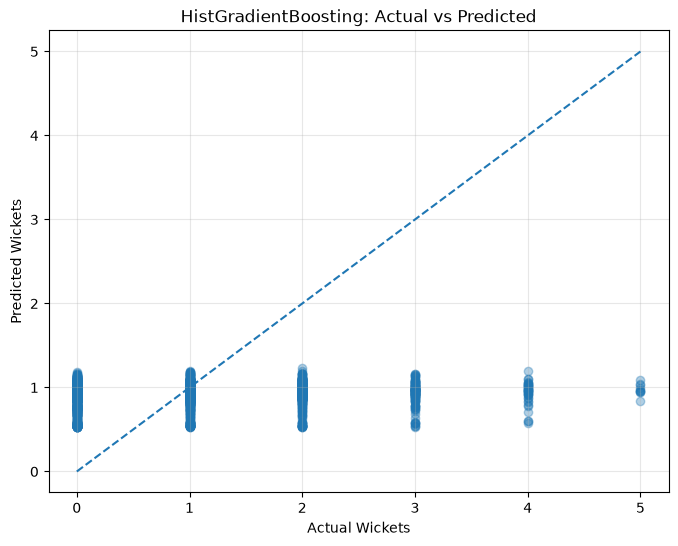

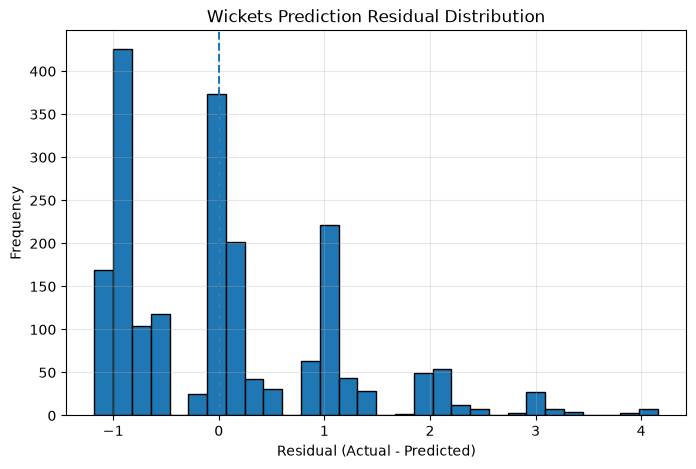

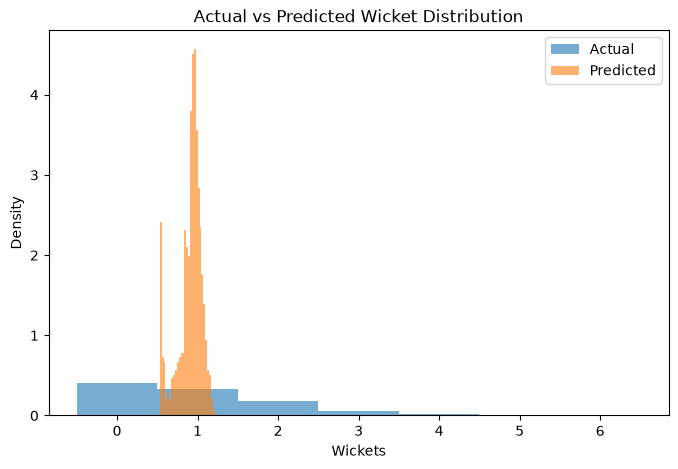

Actual standard deviation: 1.043
Predicted standard deviation: 0.1507
Residual mean: 0.0704
Residual standard deviation: 1.0315


In [167]:
# ============================================================
# HISTGRADIENT BOOSTING — ACTUAL VS PREDICTED DIAGNOSTICS
# ============================================================

import matplotlib.pyplot as plt
import numpy as np

actual = np.asarray(y_val_wickets)
predicted = np.asarray(hist_val_predictions)

residuals = actual - predicted

# Plot 1: Actual vs predicted
plt.figure(figsize=(8, 6))

plt.scatter(
    actual,
    predicted,
    alpha=0.35
)

plt.plot(
    [0, actual.max()],
    [0, actual.max()],
    linestyle="--"
)

plt.xlabel("Actual Wickets")
plt.ylabel("Predicted Wickets")
plt.title("HistGradientBoosting: Actual vs Predicted")

plt.grid(alpha=0.3)
plt.show()


# Plot 2: Residual distribution
plt.figure(figsize=(8, 5))

plt.hist(
    residuals,
    bins=30,
    edgecolor="black"
)

plt.axvline(0, linestyle="--")

plt.xlabel("Residual (Actual - Predicted)")
plt.ylabel("Frequency")
plt.title("Wickets Prediction Residual Distribution")

plt.grid(alpha=0.3)
plt.show()


# Plot 3: Prediction distribution comparison
plt.figure(figsize=(8, 5))

plt.hist(
    actual,
    bins=np.arange(-0.5, 7.5, 1),
    alpha=0.6,
    label="Actual",
    density=True
)

plt.hist(
    predicted,
    bins=30,
    alpha=0.6,
    label="Predicted",
    density=True
)

plt.xlabel("Wickets")
plt.ylabel("Density")
plt.title("Actual vs Predicted Wicket Distribution")
plt.legend()
plt.show()


print("Actual standard deviation:", round(actual.std(), 4))
print("Predicted standard deviation:", round(predicted.std(), 4))
print("Residual mean:", round(residuals.mean(), 4))
print("Residual standard deviation:", round(residuals.std(), 4))

In [168]:
# ============================================================
# TWO-STAGE BOWLING WICKETS MODEL
# ============================================================

import numpy as np
import time

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.ensemble import (
    HistGradientBoostingClassifier,
    HistGradientBoostingRegressor
)

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    mean_poisson_deviance
)

# ------------------------------------------------------------
# STAGE 1: CLASSIFICATION — WILL THE BOWLER TAKE A WICKET?
# ------------------------------------------------------------

y_train_binary = (y_train_wickets > 0).astype(int)
y_val_binary = (y_val_wickets > 0).astype(int)

wicket_classifier = Pipeline([
    ("preprocessor", clone(bowling_preprocessor)),
    ("model", HistGradientBoostingClassifier(
        max_iter=300,
        learning_rate=0.05,
        max_leaf_nodes=15,
        min_samples_leaf=20,
        l2_regularization=1.0,
        random_state=42
    ))
])

start_time = time.time()

wicket_classifier.fit(
    X_train_bowling,
    y_train_binary
)

# Probability of taking at least one wicket
positive_class_index = list(
    wicket_classifier.classes_
).index(1)

val_wicket_probability = (
    wicket_classifier.predict_proba(X_val_bowling)
    [:, positive_class_index]
)

# ------------------------------------------------------------
# STAGE 2: REGRESSION — HOW MANY WICKETS IF POSITIVE?
# ------------------------------------------------------------

positive_mask = y_train_wickets > 0

X_train_positive = X_train_bowling.loc[positive_mask]
y_train_positive = y_train_wickets.loc[positive_mask]

conditional_regressor = Pipeline([
    ("preprocessor", clone(bowling_preprocessor)),
    ("model", HistGradientBoostingRegressor(
        max_iter=300,
        learning_rate=0.05,
        max_leaf_nodes=15,
        min_samples_leaf=10,
        l2_regularization=1.0,
        random_state=42
    ))
])

conditional_regressor.fit(
    X_train_positive,
    y_train_positive
)

# Predict conditional wicket count
val_conditional_wickets = conditional_regressor.predict(
    X_val_bowling
)

# ------------------------------------------------------------
# FINAL EXPECTED WICKETS
# ------------------------------------------------------------

two_stage_val_predictions = (
    val_wicket_probability *
    val_conditional_wickets
)

two_stage_val_predictions = np.clip(
    two_stage_val_predictions,
    1e-9,
    None
)

training_time = time.time() - start_time

# ------------------------------------------------------------
# EVALUATION
# ------------------------------------------------------------

two_stage_mae = mean_absolute_error(
    y_val_wickets,
    two_stage_val_predictions
)

two_stage_rmse = np.sqrt(
    mean_squared_error(
        y_val_wickets,
        two_stage_val_predictions
    )
)

two_stage_r2 = r2_score(
    y_val_wickets,
    two_stage_val_predictions
)

two_stage_poisson = mean_poisson_deviance(
    y_val_wickets,
    two_stage_val_predictions
)

print("=" * 65)
print("TWO-STAGE BOWLING WICKETS MODEL")
print("=" * 65)

print("Positive training records:", len(y_train_positive))
print("Zero-wicket training records:", (~positive_mask).sum())

print("\nValidation metrics:")
print("MAE:", round(two_stage_mae, 4))
print("RMSE:", round(two_stage_rmse, 4))
print("R2:", round(two_stage_r2, 4))
print("Poisson deviance:", round(two_stage_poisson, 4))

print("\nExisting HistGradientBoosting MAE:", round(hist_mae, 4))
print("Two-stage model MAE:", round(two_stage_mae, 4))

print("\nMean predicted wickets:",
      round(two_stage_val_predictions.mean(), 4))

print("Actual mean wickets:",
      round(y_val_wickets.mean(), 4))

print("\nTraining time:", round(training_time, 3), "seconds")

print("\nTWO-STAGE MODEL COMPLETED")

TWO-STAGE BOWLING WICKETS MODEL
Positive training records: 5844
Zero-wicket training records: 4449

Validation metrics:
MAE: 0.7979
RMSE: 1.0372
R2: 0.0111
Poisson deviance: 1.2313

Existing HistGradientBoosting MAE: 0.7873
Two-stage model MAE: 0.7979

Mean predicted wickets: 0.92
Actual mean wickets: 0.9773

Training time: 0.972 seconds

TWO-STAGE MODEL COMPLETED


In [169]:
# ============================================================
# TWO-STAGE MODEL — CLASSIFIER EVALUATION
# ============================================================

import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Predicted classes at threshold 0.5
classifier_predictions = (
    val_wicket_probability >= 0.5
).astype(int)

# Classification metrics
classifier_accuracy = accuracy_score(
    y_val_binary,
    classifier_predictions
)

classifier_precision = precision_score(
    y_val_binary,
    classifier_predictions,
    zero_division=0
)

classifier_recall = recall_score(
    y_val_binary,
    classifier_predictions,
    zero_division=0
)

classifier_f1 = f1_score(
    y_val_binary,
    classifier_predictions,
    zero_division=0
)

classifier_auc = roc_auc_score(
    y_val_binary,
    val_wicket_probability
)

print("=" * 65)
print("WICKET OCCURRENCE CLASSIFIER EVALUATION")
print("=" * 65)

print("Accuracy:", round(classifier_accuracy, 4))
print("Precision:", round(classifier_precision, 4))
print("Recall:", round(classifier_recall, 4))
print("F1-score:", round(classifier_f1, 4))
print("ROC-AUC:", round(classifier_auc, 4))

print("\nConfusion Matrix:")
print(
    confusion_matrix(
        y_val_binary,
        classifier_predictions
    )
)

print("\nClassification Report:")
print(
    classification_report(
        y_val_binary,
        classifier_predictions,
        zero_division=0
    )
)

print("\nCLASSIFIER EVALUATION COMPLETED")

WICKET OCCURRENCE CLASSIFIER EVALUATION
Accuracy: 0.6217
Precision: 0.6311
Recall: 0.8808
F1-score: 0.7353
ROC-AUC: 0.5901

Confusion Matrix:
[[ 195  622]
 [ 144 1064]]

Classification Report:
              precision    recall  f1-score   support

           0       0.58      0.24      0.34       817
           1       0.63      0.88      0.74      1208

    accuracy                           0.62      2025
   macro avg       0.60      0.56      0.54      2025
weighted avg       0.61      0.62      0.57      2025


CLASSIFIER EVALUATION COMPLETED


In [170]:
# ============================================================
# HISTGRADIENT BOOSTING — CONTROLLED HYPERPARAMETER EXPERIMENT
# ============================================================

import time
import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

experiments = [
    {"loss": "squared_error", "max_leaf_nodes": 7,  "min_samples_leaf": 20},
    {"loss": "squared_error", "max_leaf_nodes": 15, "min_samples_leaf": 20},
    {"loss": "squared_error", "max_leaf_nodes": 31, "min_samples_leaf": 20},
    {"loss": "squared_error", "max_leaf_nodes": 15, "min_samples_leaf": 50},
    {"loss": "poisson",       "max_leaf_nodes": 7,  "min_samples_leaf": 20},
    {"loss": "poisson",       "max_leaf_nodes": 15, "min_samples_leaf": 20},
    {"loss": "poisson",       "max_leaf_nodes": 31, "min_samples_leaf": 20},
]

results = []
tuned_models = {}

for i, params in enumerate(experiments, start=1):

    model = Pipeline([
        ("preprocessor", clone(bowling_preprocessor)),
        ("model", HistGradientBoostingRegressor(
            max_iter=300,
            learning_rate=0.05,
            max_leaf_nodes=params["max_leaf_nodes"],
            min_samples_leaf=params["min_samples_leaf"],
            l2_regularization=1.0,
            loss=params["loss"],
            random_state=42
        ))
    ])

    start = time.time()

    model.fit(X_train_bowling, y_train_wickets)

    predictions = model.predict(X_val_bowling)

    elapsed = time.time() - start

    mae = mean_absolute_error(y_val_wickets, predictions)
    rmse = np.sqrt(mean_squared_error(y_val_wickets, predictions))
    r2 = r2_score(y_val_wickets, predictions)

    results.append({
        "experiment": i,
        **params,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2,
        "training_time": elapsed
    })

    tuned_models[i] = model

tuning_results = pd.DataFrame(results).sort_values("MAE")

print("=" * 70)
print("HISTGRADIENT BOOSTING — TUNING RESULTS")
print("=" * 70)

display(tuning_results)

print("\nOriginal validation MAE:", round(hist_mae, 4))
print("Best tuned validation MAE:", round(tuning_results.iloc[0]["MAE"], 4))

HISTGRADIENT BOOSTING — TUNING RESULTS


,experiment,loss,max_leaf_nodes,min_samples_leaf,MAE,RMSE,R2,training_time
4,5,poisson,7,20,0.783476,1.033102,0.018918,0.168776
5,6,poisson,15,20,0.785649,1.034466,0.016324,0.205677
0,1,squared_error,7,20,0.786198,1.033974,0.017260,0.247418
6,7,poisson,31,20,0.786978,1.034931,0.015441,0.279904
1,2,squared_error,15,20,0.787330,1.033918,0.017367,0.226760
3,4,squared_error,15,50,0.787363,1.034334,0.016575,0.188318
2,3,squared_error,31,20,0.791386,1.036575,0.012310,0.253021



Original validation MAE: 0.7873
Best tuned validation MAE: 0.7835


In [171]:
# ============================================================
# SELECT AND VERIFY BEST TUNED WICKETS MODEL
# ============================================================

import numpy as np
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    mean_poisson_deviance
)

# Retrieve best configuration from tuning results
best_experiment = int(
    tuning_results.iloc[0]["experiment"]
)

best_tuned_wickets_model = tuned_models[best_experiment]

# Validation predictions
best_tuned_val_predictions = (
    best_tuned_wickets_model.predict(X_val_bowling)
)

# Ensure predictions are valid for Poisson evaluation
poisson_predictions = np.clip(
    best_tuned_val_predictions, 1e-9, None
)

# Calculate metrics
best_tuned_metrics = {
    "MAE": mean_absolute_error(
        y_val_wickets, best_tuned_val_predictions
    ),
    "RMSE": np.sqrt(
        mean_squared_error(
            y_val_wickets, best_tuned_val_predictions
        )
    ),
    "R2": r2_score(
        y_val_wickets, best_tuned_val_predictions
    ),
    "Poisson Deviance": mean_poisson_deviance(
        y_val_wickets, poisson_predictions
    )
}

print("=" * 65)
print("SELECTED TUNED WICKETS MODEL")
print("=" * 65)

print("Experiment:", best_experiment)
print("Configuration:")
print(tuning_results.iloc[0])

print("\nValidation metrics:")
for metric, value in best_tuned_metrics.items():
    print(f"{metric}: {value:.4f}")

print("\nPrediction distribution:")
print("Actual mean:", round(y_val_wickets.mean(), 4))
print("Predicted mean:", round(best_tuned_val_predictions.mean(), 4))
print("Actual std:", round(y_val_wickets.std(), 4))
print("Predicted std:", round(best_tuned_val_predictions.std(), 4))

print("\nOriginal HGB MAE:", round(hist_mae, 4))
print(
    "Tuned HGB MAE:",
    round(best_tuned_metrics["MAE"], 4)
)

print("\nMODEL VERIFICATION COMPLETED")

SELECTED TUNED WICKETS MODEL
Experiment: 5
Configuration:
experiment                 5
loss                 poisson
max_leaf_nodes             7
min_samples_leaf          20
MAE                 0.783476
RMSE                1.033102
R2                  0.018918
training_time       0.168776
Name: 4, dtype: object

Validation metrics:
MAE: 0.7835
RMSE: 1.0331
R2: 0.0189
Poisson Deviance: 1.2240

Prediction distribution:
Actual mean: 0.9773
Predicted mean: 0.9137
Actual std: 1.0433
Predicted std: 0.1559

Original HGB MAE: 0.7873
Tuned HGB MAE: 0.7835

MODEL VERIFICATION COMPLETED


In [172]:
# ============================================================
# FINAL BOWLING WICKETS — UNTOUCHED TEST EVALUATION
# ============================================================

import numpy as np
import pandas as pd

from sklearn.dummy import DummyRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    mean_poisson_deviance
)

# 1. Predictions from selected tuned model
test_wickets_predictions = best_tuned_wickets_model.predict(
    X_test_bowling
)

# 2. Baseline test predictions
test_baseline_model = DummyRegressor(strategy="mean")

test_baseline_model.fit(
    X_train_bowling,
    y_train_wickets
)

test_baseline_predictions = test_baseline_model.predict(
    X_test_bowling
)

# 3. Evaluation function
def evaluate_wickets(y_true, predictions):
    return {
        "MAE": mean_absolute_error(y_true, predictions),
        "RMSE": np.sqrt(
            mean_squared_error(y_true, predictions)
        ),
        "R2": r2_score(y_true, predictions),
        "Poisson Deviance": mean_poisson_deviance(
            y_true,
            np.clip(predictions, 1e-9, None)
        ),
        "Prediction Mean": np.mean(predictions),
        "Prediction Std": np.std(predictions)
    }

# 4. Metrics
baseline_test_metrics = evaluate_wickets(
    y_test_wickets,
    test_baseline_predictions
)

final_test_metrics = evaluate_wickets(
    y_test_wickets,
    test_wickets_predictions
)

comparison = pd.DataFrame({
    "Baseline": baseline_test_metrics,
    "Tuned_Poisson_HGB": final_test_metrics
}).T

print("=" * 70)
print("FINAL BOWLING WICKETS — TEST RESULTS")
print("=" * 70)

display(comparison.round(4))

print("\nTEST TARGET DISTRIBUTION")
print(y_test_wickets.describe())

print("\nTEST ACTUAL MEAN:", round(y_test_wickets.mean(), 4))
print("TEST ACTUAL STD:", round(y_test_wickets.std(), 4))

print("\nTEST EVALUATION COMPLETED")

FINAL BOWLING WICKETS — TEST RESULTS


,MAE,RMSE,R2,Poisson Deviance,Prediction Mean,Prediction Std
Baseline,0.7821,1.0087,-0.0062,1.1964,0.8997,0.0000
Tuned_Poisson_HGB,0.7637,0.9936,0.0236,1.1611,0.9082,0.1455



TEST TARGET DISTRIBUTION
count    1805.000000
mean        0.978947
std         1.005859
min         0.000000
25%         0.000000
50%         1.000000
75%         2.000000
max         5.000000
Name: target_next_match_wickets, dtype: float64

TEST ACTUAL MEAN: 0.9789
TEST ACTUAL STD: 1.0059

TEST EVALUATION COMPLETED


In [173]:
# ============================================================
# BOWLING MODEL DIRECTORY AUDIT
# ============================================================

from pathlib import Path

BOWLING_MODEL_DIR = PROJECT_ROOT / "models" / "bowling"

print("=" * 65)
print("BOWLING MODEL DIRECTORY AUDIT")
print("=" * 65)

print("\nDirectory:", BOWLING_MODEL_DIR)
print("Directory exists:", BOWLING_MODEL_DIR.exists())

if BOWLING_MODEL_DIR.exists():
    files = list(BOWLING_MODEL_DIR.rglob("*"))

    if not files:
        print("\nDirectory is empty.")
    else:
        print("\nExisting artifacts:")

        for path in files:
            if path.is_file():
                print(
                    f"{path.relative_to(PROJECT_ROOT)} "
                    f"| {path.stat().st_size / 1024:.2f} KB"
                )
else:
    print("\nBowling model directory does not exist yet.")

print("\nDIRECTORY AUDIT COMPLETED")

BOWLING MODEL DIRECTORY AUDIT

Directory: d:\Git\Personal\ipl-player-performance-v2\models\bowling
Directory exists: True

Existing artifacts:
models\bowling\wickets_feature_metadata.json | 3.01 KB
models\bowling\wickets_model.joblib | 71.87 KB
models\bowling\wickets_model_metrics.json | 0.83 KB

DIRECTORY AUDIT COMPLETED


In [174]:
# ============================================================
# SAVE VERIFIED BOWLING WICKETS MODEL
# ============================================================

from pathlib import Path
import joblib
import json
import numpy as np
import pandas as pd
import sklearn
from datetime import datetime, timezone

# 1. Project paths
BOWLING_MODEL_DIR = PROJECT_ROOT / "models" / "bowling"
BOWLING_MODEL_DIR.mkdir(parents=True, exist_ok=True)

model_path = BOWLING_MODEL_DIR / "wickets_model.joblib"
metadata_path = BOWLING_MODEL_DIR / "wickets_feature_metadata.json"
metrics_path = BOWLING_MODEL_DIR / "wickets_model_metrics.json"

# 2. Prevent accidental overwriting
existing_files = [
    path for path in [model_path, metadata_path, metrics_path]
    if path.exists()
]

if existing_files:
    raise FileExistsError(
        f"Existing artifacts found: {existing_files}. "
        "Inspect before overwriting."
    )

# 3. Confirm selected model configuration
assert best_experiment == int(
    tuning_results.iloc[0]["experiment"]
)

assert best_tuned_metrics["MAE"] < baseline_mae

# 4. Save complete fitted pipeline
joblib.dump(best_tuned_wickets_model, model_path)

# 5. Save feature metadata
feature_metadata = {
    "model_name": "Bowling Wickets Prediction",
    "target": "target_next_match_wickets",
    "prediction_definition": (
        "Predicts wickets in the player's next recorded regular appearance, "
        "using information available after the current match."
    ),
    "features": list(X_train_bowling.columns),
    "feature_count": len(X_train_bowling.columns),
    "categorical_features": categorical_features,
    "numerical_features": numeric_features,
    "model_type": "HistGradientBoostingRegressor",
    "loss": "poisson",
    "hyperparameters": {
        "max_iter": 300,
        "learning_rate": 0.05,
        "max_leaf_nodes": 7,
        "min_samples_leaf": 20,
        "l2_regularization": 1.0,
        "random_state": 42
    },
    "created_at_utc": datetime.now(timezone.utc).isoformat(),
    "scikit_learn_version": sklearn.__version__
}

with open(metadata_path, "w", encoding="utf-8") as file:
    json.dump(feature_metadata, file, indent=4)

# 6. Save validation and test metrics
model_metrics = {
    "validation": {
        key: float(value)
        for key, value in best_tuned_metrics.items()
    },
    "test": {
        key: float(value)
        for key, value in final_test_metrics.items()
    },
    "test_baseline": {
        key: float(value)
        for key, value in baseline_test_metrics.items()
    },
    "test_rows": int(len(y_test_wickets)),
    "selection_metric": "MAE",
    "test_baseline_improved": bool(
        final_test_metrics["MAE"]
        < baseline_test_metrics["MAE"]
    )
}

with open(metrics_path, "w", encoding="utf-8") as file:
    json.dump(model_metrics, file, indent=4)

# 7. Reload and verify predictions
loaded_wickets_model = joblib.load(model_path)

reloaded_predictions = loaded_wickets_model.predict(
    X_test_bowling
)

assert np.allclose(
    test_wickets_predictions,
    reloaded_predictions,
    rtol=1e-7,
    atol=1e-9
), "Reloaded predictions do not match!"

# 8. Artifact report
print("=" * 65)
print("BOWLING WICKETS MODEL SERIALIZATION")
print("=" * 65)

for path in [model_path, metadata_path, metrics_path]:
    print(f"\nFile: {path.relative_to(PROJECT_ROOT)}")
    print("Exists:", path.exists())
    print("Size:", round(path.stat().st_size / 1024, 2), "KB")

print("\nReloaded test predictions match: PASS")
print("Model type:", type(loaded_wickets_model).__name__)
print("\nBOWLING WICKETS MODEL SAVING COMPLETED")

FileExistsError: Existing artifacts found: [WindowsPath('d:/Git/Personal/ipl-player-performance-v2/models/bowling/wickets_model.joblib'), WindowsPath('d:/Git/Personal/ipl-player-performance-v2/models/bowling/wickets_feature_metadata.json'), WindowsPath('d:/Git/Personal/ipl-player-performance-v2/models/bowling/wickets_model_metrics.json')]. Inspect before overwriting.

In [175]:
from pathlib import Path

directories = {
    "Correct batting": PROJECT_ROOT / "models" / "batting",
    "Misplaced batting": PROJECT_ROOT / "notebooks" / "models" / "batting",
    "Bowling": PROJECT_ROOT / "models" / "bowling"
}

for label, directory in directories.items():
    print(f"\n{label}: {directory}")
    print("Exists:", directory.exists())

    if directory.exists():
        for file in directory.iterdir():
            if file.is_file():
                print("  ", file.name)


Correct batting: d:\Git\Personal\ipl-player-performance-v2\models\batting
Exists: True
   original_gb_model.joblib
   sqrt_gb_model.joblib

Misplaced batting: d:\Git\Personal\ipl-player-performance-v2\notebooks\models\batting
Exists: False

Bowling: d:\Git\Personal\ipl-player-performance-v2\models\bowling
Exists: True
   wickets_feature_metadata.json
   wickets_model.joblib
   wickets_model_metrics.json


In [176]:
# ============================================================
# BOWLING RUNS CONCEDED — DATASET AUDIT
# ============================================================

import pandas as pd
import numpy as np

DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "features"
    / "bowling_model_dataset.csv"
)

bowling_df = pd.read_csv(DATA_PATH)

target = "target_next_match_runs_conceded"

print("=" * 65)
print("BOWLING RUNS CONCEDED — DATASET AUDIT")
print("=" * 65)

print("\nDataset shape:", bowling_df.shape)

print("\nTarget missing values:")
print(bowling_df[target].isna().sum())

print("\nTarget statistics:")
print(bowling_df[target].describe())

print("\nNegative target values:",
      (bowling_df[target] < 0).sum())

print("\nTarget distribution:")
print(bowling_df[target].value_counts().sort_index().head(15))

print("\nExisting wickets feature matrix:")
print("Training:", X_train_bowling.shape)
print("Validation:", X_val_bowling.shape)
print("Testing:", X_test_bowling.shape)

print("\nDATASET AUDIT COMPLETED")

BOWLING RUNS CONCEDED — DATASET AUDIT

Dataset shape: (14123, 43)

Target missing values:
0

Target statistics:
count    14123.000000
mean        26.876372
std         11.173536
min          0.000000
25%         19.000000
50%         26.000000
75%         34.000000
max         76.000000
Name: target_next_match_runs_conceded, dtype: float64

Negative target values: 0

Target distribution:
target_next_match_runs_conceded
0.0      10
1.0      15
2.0      21
3.0      39
4.0      62
5.0      77
6.0      94
7.0     130
8.0     150
9.0     162
10.0    205
11.0    208
12.0    235
13.0    259
14.0    324
Name: count, dtype: int64

Existing wickets feature matrix:
Training: (10293, 35)
Validation: (2025, 35)
Testing: (1805, 35)

DATASET AUDIT COMPLETED


In [177]:
# ============================================================
# BOWLING RUNS CONCEDED — MODEL EXPERIMENTS
# ============================================================

import time
import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor,
    HistGradientBoostingRegressor
)
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from xgboost import XGBRegressor
from catboost import CatBoostRegressor

TARGET = "target_next_match_runs_conceded"

# 1. Align targets with existing chronological feature partitions
y_train_runs = bowling_df.loc[X_train_bowling.index, TARGET]
y_val_runs = bowling_df.loc[X_val_bowling.index, TARGET]
y_test_runs = bowling_df.loc[X_test_bowling.index, TARGET]

assert y_train_runs.notna().all()
assert y_val_runs.notna().all()
assert y_test_runs.notna().all()

assert X_train_bowling.index.equals(y_train_runs.index)
assert X_val_bowling.index.equals(y_val_runs.index)
assert X_test_bowling.index.equals(y_test_runs.index)

print("Target alignment: PASS")
print("Train:", len(y_train_runs))
print("Validation:", len(y_val_runs))
print("Test:", len(y_test_runs))

# 2. Define candidate models
models = {
    "Random Forest": Pipeline([
        ("preprocessor", clone(bowling_preprocessor)),
        ("model", RandomForestRegressor(
            n_estimators=400,
            max_depth=None,
            min_samples_split=5,
            min_samples_leaf=3,
            max_features=0.7,
            random_state=42,
            n_jobs=-1
        ))
    ]),

    "Gradient Boosting": Pipeline([
        ("preprocessor", clone(bowling_preprocessor)),
        ("model", GradientBoostingRegressor(
            n_estimators=200,
            learning_rate=0.05,
            max_depth=2,
            min_samples_leaf=5,
            random_state=42
        ))
    ]),

    "HistGradientBoosting": Pipeline([
        ("preprocessor", clone(bowling_preprocessor)),
        ("model", HistGradientBoostingRegressor(
            max_iter=200,
            learning_rate=0.05,
            max_leaf_nodes=15,
            min_samples_leaf=20,
            l2_regularization=1.0,
            random_state=42
        ))
    ]),

    "XGBoost": Pipeline([
        ("preprocessor", clone(bowling_preprocessor)),
        ("model", XGBRegressor(
            objective="reg:squarederror",
            n_estimators=500,
            learning_rate=0.03,
            max_depth=3,
            min_child_weight=5,
            subsample=0.8,
            colsample_bytree=0.8,
            reg_alpha=0.1,
            reg_lambda=1.0,
            random_state=42,
            n_jobs=-1,
            tree_method="hist"
        ))
    ])
}

# CatBoost uses raw categorical features
cat_features = [
    col for col in X_train_bowling.columns
    if (
        X_train_bowling[col].dtype == "object"
        or str(X_train_bowling[col].dtype) in ["str", "category", "bool"]
    )
]

X_train_cat_runs = X_train_bowling.copy()
X_val_cat_runs = X_val_bowling.copy()

for col in cat_features:
    X_train_cat_runs[col] = (
        X_train_cat_runs[col].fillna("Unknown").astype(str)
    )
    X_val_cat_runs[col] = (
        X_val_cat_runs[col].fillna("Unknown").astype(str)
    )

cat_runs_model = CatBoostRegressor(
    iterations=500,
    learning_rate=0.03,
    depth=5,
    loss_function="RMSE",
    l2_leaf_reg=3,
    random_seed=42,
    verbose=False,
    allow_writing_files=False,
    thread_count=-1
)

# 3. Train and evaluate on validation data
runs_models = {}
runs_predictions = {}
runs_results = []

for name, model in models.items():
    start = time.time()

    model.fit(X_train_bowling, y_train_runs)

    predictions = model.predict(X_val_bowling)
    elapsed = time.time() - start

    runs_models[name] = model
    runs_predictions[name] = predictions

    runs_results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_val_runs, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_val_runs, predictions)),
        "R2": r2_score(y_val_runs, predictions),
        "Training_Time": elapsed
    })

# 4. CatBoost
start = time.time()

cat_runs_model.fit(
    X_train_cat_runs,
    y_train_runs,
    cat_features=cat_features
)

cat_predictions = cat_runs_model.predict(X_val_cat_runs)
elapsed = time.time() - start

runs_models["CatBoost"] = cat_runs_model
runs_predictions["CatBoost"] = cat_predictions

runs_results.append({
    "Model": "CatBoost",
    "MAE": mean_absolute_error(y_val_runs, cat_predictions),
    "RMSE": np.sqrt(mean_squared_error(y_val_runs, cat_predictions)),
    "R2": r2_score(y_val_runs, cat_predictions),
    "Training_Time": elapsed
})

# 5. Baseline
baseline_prediction = np.full(
    len(y_val_runs),
    y_train_runs.mean()
)

runs_results.append({
    "Model": "Mean Baseline",
    "MAE": mean_absolute_error(y_val_runs, baseline_prediction),
    "RMSE": np.sqrt(mean_squared_error(y_val_runs, baseline_prediction)),
    "R2": r2_score(y_val_runs, baseline_prediction),
    "Training_Time": 0.0
})

runs_leaderboard = (
    pd.DataFrame(runs_results)
    .sort_values("MAE")
    .reset_index(drop=True)
)

print("\n" + "=" * 70)
print("BOWLING RUNS CONCEDED — VALIDATION LEADERBOARD")
print("=" * 70)

display(runs_leaderboard.round(4))

print("\nRUNS-CONCEDED MODEL EXPERIMENTS COMPLETED")

Target alignment: PASS
Train: 10293
Validation: 2025
Test: 1805

BOWLING RUNS CONCEDED — VALIDATION LEADERBOARD


,Model,MAE,RMSE,R2,Training_Time
0,Mean Baseline,8.7403,10.9056,-0.0022,0.0000
1,HistGradientBoosting,8.7966,10.9643,-0.0130,0.4564
2,CatBoost,8.8090,11.0587,-0.0305,16.1353
3,Gradient Boosting,8.8204,10.9833,-0.0165,7.4632
4,XGBoost,8.8627,11.0442,-0.0278,0.7895
5,Random Forest,8.8841,11.0857,-0.0355,6.1469



RUNS-CONCEDED MODEL EXPERIMENTS COMPLETED


In [178]:
# ============================================================
# RUNS CONCEDED — FEATURE SIGNAL AUDIT
# ============================================================

import pandas as pd
import numpy as np

TARGET = "target_next_match_runs_conceded"

# Training data only
audit_df = X_train_bowling.copy()
audit_df[TARGET] = y_train_runs

# Numeric correlation
correlations = (
    audit_df.select_dtypes(include=np.number)
    .corr()[TARGET]
    .drop(TARGET)
    .dropna()
    .sort_values(key=abs, ascending=False)
)

print("=" * 65)
print("RUNS CONCEDED — TOP NUMERIC FEATURE CORRELATIONS")
print("=" * 65)

print(correlations.head(15).round(4))

# Baseline and candidate comparison
print("\nVALIDATION MAE GAP")

baseline_mae = runs_leaderboard.loc[
    runs_leaderboard["Model"] == "Mean Baseline", "MAE"
].iloc[0]

best_ml_row = runs_leaderboard[
    runs_leaderboard["Model"] != "Mean Baseline"
].iloc[0]

print("Baseline MAE:", round(baseline_mae, 4))
print("Best ML model:", best_ml_row["Model"])
print("Best ML MAE:", round(best_ml_row["MAE"], 4))
print("Difference:", round(best_ml_row["MAE"] - baseline_mae, 4))

print("\nFEATURE SIGNAL AUDIT COMPLETED")

RUNS CONCEDED — TOP NUMERIC FEATURE CORRELATIONS
days_since_previous_match      0.0220
bowling_average                0.0200
economy_rate_expanding_mean   -0.0157
previous_economy_rate          0.0153
legal_balls_rolling_mean_3     0.0081
bowling_strike_rate            0.0076
economy_rate                   0.0075
noballs_conceded              -0.0071
economy_rate_rolling_mean_3   -0.0071
previous_runs_conceded         0.0066
legal_balls_expanding_mean     0.0066
wickets_expanding_mean         0.0059
previous_legal_balls          -0.0058
previous_wickets              -0.0057
wides_conceded                -0.0055
Name: target_next_match_runs_conceded, dtype: float64

VALIDATION MAE GAP
Baseline MAE: 8.7403
Best ML model: HistGradientBoosting
Best ML MAE: 8.7966
Difference: 0.0564

FEATURE SIGNAL AUDIT COMPLETED


In [179]:
# ============================================================
# BOWLING LEGAL BALLS — TARGET AUDIT
# ============================================================

TARGET = "target_next_match_legal_balls"

y_train_balls = bowling_df.loc[X_train_bowling.index, TARGET]
y_val_balls = bowling_df.loc[X_val_bowling.index, TARGET]
y_test_balls = bowling_df.loc[X_test_bowling.index, TARGET]

print("=" * 65)
print("BOWLING LEGAL BALLS — TARGET AUDIT")
print("=" * 65)

for name, target in [
    ("Train", y_train_balls),
    ("Validation", y_val_balls),
    ("Test", y_test_balls)
]:
    print(f"\n{name}:")
    print(target.describe())
    print("Missing:", target.isna().sum())
    print("Negative:", (target < 0).sum())

assert y_train_balls.notna().all()
assert y_val_balls.notna().all()
assert y_test_balls.notna().all()

print("\nLEGAL BALLS TARGET AUDIT PASSED")

BOWLING LEGAL BALLS — TARGET AUDIT

Train:
count    10293.000000
mean        19.448557
std          6.009175
min          0.000000
25%         18.000000
50%         24.000000
75%         24.000000
max         25.000000
Name: target_next_match_legal_balls, dtype: float64
Missing: 0
Negative: 0

Validation:
count    2025.000000
mean       19.924938
std         5.904401
min         2.000000
25%        18.000000
50%        24.000000
75%        24.000000
max        24.000000
Name: target_next_match_legal_balls, dtype: float64
Missing: 0
Negative: 0

Test:
count    1805.000000
mean       18.744044
std         6.556329
min         1.000000
25%        12.000000
50%        24.000000
75%        24.000000
max        24.000000
Name: target_next_match_legal_balls, dtype: float64
Missing: 0
Negative: 0

LEGAL BALLS TARGET AUDIT PASSED


In [180]:
# ============================================================
# BOWLING LEGAL BALLS — MODEL EXPERIMENTS
# ============================================================

import time
import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor,
    HistGradientBoostingRegressor
)
from sklearn.dummy import DummyRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from xgboost import XGBRegressor
from catboost import CatBoostRegressor

TARGET = "target_next_match_legal_balls"

# 1. Verify target alignment
assert X_train_bowling.index.equals(y_train_balls.index)
assert X_val_bowling.index.equals(y_val_balls.index)
assert X_test_bowling.index.equals(y_test_balls.index)

# 2. Define models
legal_models = {
    "Random Forest": Pipeline([
        ("preprocessor", clone(bowling_preprocessor)),
        ("model", RandomForestRegressor(
            n_estimators=400,
            min_samples_split=5,
            min_samples_leaf=3,
            max_features=0.7,
            random_state=42,
            n_jobs=-1
        ))
    ]),

    "Gradient Boosting": Pipeline([
        ("preprocessor", clone(bowling_preprocessor)),
        ("model", GradientBoostingRegressor(
            n_estimators=200,
            learning_rate=0.05,
            max_depth=2,
            min_samples_leaf=5,
            random_state=42
        ))
    ]),

    "HistGradientBoosting": Pipeline([
        ("preprocessor", clone(bowling_preprocessor)),
        ("model", HistGradientBoostingRegressor(
            max_iter=200,
            learning_rate=0.05,
            max_leaf_nodes=15,
            min_samples_leaf=20,
            l2_regularization=1.0,
            random_state=42
        ))
    ]),

    "XGBoost": Pipeline([
        ("preprocessor", clone(bowling_preprocessor)),
        ("model", XGBRegressor(
            objective="reg:squarederror",
            n_estimators=500,
            learning_rate=0.03,
            max_depth=3,
            min_child_weight=5,
            subsample=0.8,
            colsample_bytree=0.8,
            reg_alpha=0.1,
            reg_lambda=1.0,
            random_state=42,
            n_jobs=-1,
            tree_method="hist"
        ))
    ])
}

# 3. Prepare CatBoost categorical columns
cat_features_balls = [
    col for col in X_train_bowling.columns
    if (
        X_train_bowling[col].dtype == "object"
        or str(X_train_bowling[col].dtype)
        in ["str", "category", "bool"]
    )
]

X_train_cat_balls = X_train_bowling.copy()
X_val_cat_balls = X_val_bowling.copy()

for col in cat_features_balls:
    X_train_cat_balls[col] = (
        X_train_cat_balls[col].fillna("Unknown").astype(str)
    )
    X_val_cat_balls[col] = (
        X_val_cat_balls[col].fillna("Unknown").astype(str)
    )

cat_legal_model = CatBoostRegressor(
    iterations=500,
    learning_rate=0.03,
    depth=5,
    loss_function="RMSE",
    l2_leaf_reg=3,
    random_seed=42,
    verbose=False,
    allow_writing_files=False,
    thread_count=-1
)

# 4. Train and evaluate
legal_models_trained = {}
legal_predictions = {}
legal_results = []

for name, model in legal_models.items():

    start = time.time()

    model.fit(X_train_bowling, y_train_balls)

    predictions = model.predict(X_val_bowling)

    legal_models_trained[name] = model
    legal_predictions[name] = predictions

    legal_results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_val_balls, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_val_balls, predictions)),
        "R2": r2_score(y_val_balls, predictions),
        "Training_Time": time.time() - start
    })

# 5. CatBoost
start = time.time()

cat_legal_model.fit(
    X_train_cat_balls,
    y_train_balls,
    cat_features=cat_features_balls
)

cat_predictions = cat_legal_model.predict(X_val_cat_balls)

legal_models_trained["CatBoost"] = cat_legal_model
legal_predictions["CatBoost"] = cat_predictions

legal_results.append({
    "Model": "CatBoost",
    "MAE": mean_absolute_error(y_val_balls, cat_predictions),
    "RMSE": np.sqrt(mean_squared_error(y_val_balls, cat_predictions)),
    "R2": r2_score(y_val_balls, cat_predictions),
    "Training_Time": time.time() - start
})

# 6. Mean baseline
baseline_legal_model = DummyRegressor(strategy="mean")

baseline_legal_model.fit(
    X_train_bowling,
    y_train_balls
)

baseline_legal_predictions = baseline_legal_model.predict(
    X_val_bowling
)

legal_results.append({
    "Model": "Mean Baseline",
    "MAE": mean_absolute_error(
        y_val_balls, baseline_legal_predictions
    ),
    "RMSE": np.sqrt(
        mean_squared_error(y_val_balls, baseline_legal_predictions)
    ),
    "R2": r2_score(y_val_balls, baseline_legal_predictions),
    "Training_Time": 0.0
})

# 7. Leaderboard
legal_leaderboard = (
    pd.DataFrame(legal_results)
    .sort_values("MAE")
    .reset_index(drop=True)
)

print("=" * 70)
print("BOWLING LEGAL BALLS — VALIDATION LEADERBOARD")
print("=" * 70)

display(legal_leaderboard.round(4))

print("\nLEGAL BALLS MODEL EXPERIMENTS COMPLETED")

BOWLING LEGAL BALLS — VALIDATION LEADERBOARD


,Model,MAE,RMSE,R2,Training_Time
0,HistGradientBoosting,5.0326,5.9254,-0.0076,0.3961
1,Gradient Boosting,5.0685,5.9347,-0.0108,8.7854
2,CatBoost,5.0788,5.9956,-0.0316,14.9119
3,Mean Baseline,5.0838,5.9221,-0.0065,0.0000
4,XGBoost,5.1021,5.9832,-0.0274,0.9650
5,Random Forest,5.1163,6.0193,-0.0398,7.3061



LEGAL BALLS MODEL EXPERIMENTS COMPLETED


In [181]:
# ============================================================
# LEGAL BALLS — FINAL TEST EVALUATION
# ============================================================

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
from sklearn.dummy import DummyRegressor
import numpy as np
import pandas as pd

# Selected validation candidate
best_legal_model = legal_models_trained[
    "HistGradientBoosting"
]

# Predict untouched test set
legal_test_predictions = best_legal_model.predict(
    X_test_bowling
)

# Baseline
legal_test_baseline = DummyRegressor(strategy="mean")
legal_test_baseline.fit(X_train_bowling, y_train_balls)

legal_baseline_predictions = legal_test_baseline.predict(
    X_test_bowling
)

# Evaluation
def legal_metrics(y_true, predictions):
    return {
        "MAE": mean_absolute_error(y_true, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_true, predictions)),
        "R2": r2_score(y_true, predictions),
        "Prediction Mean": np.mean(predictions),
        "Prediction Std": np.std(predictions)
    }

legal_test_results = pd.DataFrame({
    "Baseline": legal_metrics(
        y_test_balls, legal_baseline_predictions
    ),
    "HistGradientBoosting": legal_metrics(
        y_test_balls, legal_test_predictions
    )
}).T

print("=" * 65)
print("LEGAL BALLS — UNTOUCHED TEST RESULTS")
print("=" * 65)

display(legal_test_results.round(4))

print("\nActual test mean:", round(y_test_balls.mean(), 4))
print("Actual test std:", round(y_test_balls.std(), 4))

print("\nLEGAL BALLS TEST EVALUATION COMPLETED")

LEGAL BALLS — UNTOUCHED TEST RESULTS


,MAE,RMSE,R2,Prediction Mean,Prediction Std
Baseline,5.5449,6.5923,-0.0116,19.4486,0.0000
HistGradientBoosting,5.5242,6.6365,-0.0252,19.6816,0.4211



Actual test mean: 18.744
Actual test std: 6.5563

LEGAL BALLS TEST EVALUATION COMPLETED


In [188]:
# ============================================================
# KERNEL STATE — ECONOMY RATE RECOVERY AUDIT
# ============================================================

required = [
    "bowling_df",
    "X_train_bowling",
    "X_val_bowling",
    "X_test_bowling",
    "y_train_economy_clean",
    "y_val_economy_clean",
    "y_test_economy_clean"
]

for name in required:
    exists = name in globals()
    print(f"{name}: {'AVAILABLE' if exists else 'MISSING'}")

if "bowling_df" in globals():
    print("\nDataset shape:", bowling_df.shape)

if "X_train_bowling" in globals():
    print("Training features:", X_train_bowling.shape)

if "X_val_bowling" in globals():
    print("Validation features:", X_val_bowling.shape)

if "X_test_bowling" in globals():
    print("Test features:", X_test_bowling.shape)

bowling_df: AVAILABLE
X_train_bowling: AVAILABLE
X_val_bowling: AVAILABLE
X_test_bowling: AVAILABLE
y_train_economy_clean: MISSING
y_val_economy_clean: MISSING
y_test_economy_clean: MISSING

Dataset shape: (14123, 43)
Training features: (10293, 35)
Validation features: (2025, 35)
Test features: (1805, 35)


In [190]:
TARGET = "target_next_match_economy_rate"

y_train_economy_raw = bowling_df.loc[
    X_train_bowling.index, TARGET
]

y_val_economy = bowling_df.loc[
    X_val_bowling.index, TARGET
]

y_test_economy = bowling_df.loc[
    X_test_bowling.index, TARGET
]

# Exclude only the missing training target
train_mask = y_train_economy_raw.notna()

X_train_economy_clean = X_train_bowling.loc[train_mask].copy()
y_train_economy_clean = y_train_economy_raw.loc[train_mask].copy()

X_val_economy_clean = X_val_bowling.copy()
y_val_economy_clean = y_val_economy.copy()

X_test_economy_clean = X_test_bowling.copy()
y_test_economy_clean = y_test_economy.copy()

print("Train:", X_train_economy_clean.shape, y_train_economy_clean.shape)
print("Validation:", X_val_economy_clean.shape, y_val_economy_clean.shape)
print("Test:", X_test_economy_clean.shape, y_test_economy_clean.shape)

assert y_train_economy_clean.notna().all()
assert y_val_economy_clean.notna().all()
assert y_test_economy_clean.notna().all()

print("ECONOMY RATE VARIABLES RECOVERED")

Train: (10292, 35) (10292,)
Validation: (2025, 35) (2025,)
Test: (1805, 35) (1805,)
ECONOMY RATE VARIABLES RECOVERED


In [191]:

# ============================================================
# ECONOMY RATE — MISSING TARGET INVESTIGATION
# ============================================================

targets = {
    "Train": y_train_economy_clean,
    "Validation": y_val_economy_clean,
    "Test": y_test_economy_clean
}

print("=" * 65)
print("ECONOMY RATE — MISSING TARGET INVESTIGATION")
print("=" * 65)

for name, target in targets.items():
    print(f"\n{name}")
    print("Total records:", len(target))
    print("Missing targets:", target.isna().sum())

print("\nMISSING TARGET INVESTIGATION COMPLETED")


ECONOMY RATE — MISSING TARGET INVESTIGATION

Train
Total records: 10292
Missing targets: 0

Validation
Total records: 2025
Missing targets: 0

Test
Total records: 1805
Missing targets: 0

MISSING TARGET INVESTIGATION COMPLETED


In [193]:
# ============================================================
# ECONOMY RATE — CURRENT KERNEL CHECK
# ============================================================

required_variables = [
    "bowling_df",
    "X_train_bowling",
    "X_val_bowling",
    "X_test_bowling",
    "y_train_economy",
    "y_val_economy",
    "y_test_economy"
]

for name in required_variables:
    print(
        f"{name}:",
        "AVAILABLE" if name in globals() else "MISSING"
    )

print("\nPROJECT DATASET CHECK")

from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

dataset_path = (
    PROJECT_ROOT / "data" / "processed" /
    "features" / "bowling_model_dataset.csv"
)

print("Dataset exists:", dataset_path.exists())
print("Dataset path:", dataset_path)

bowling_df: AVAILABLE
X_train_bowling: AVAILABLE
X_val_bowling: AVAILABLE
X_test_bowling: AVAILABLE
y_train_economy: MISSING
y_val_economy: AVAILABLE
y_test_economy: AVAILABLE

PROJECT DATASET CHECK
Dataset exists: True
Dataset path: d:\Git\Personal\ipl-player-performance-v2\data\processed\features\bowling_model_dataset.csv


In [195]:

# ============================================================
# ECONOMY RATE — RECOVER MISSING TRAINING TARGET
# ============================================================

TARGET = "target_next_match_economy_rate"

# Reconstruct training target using existing chronological indices
y_train_economy = bowling_df.loc[
    X_train_bowling.index, TARGET
].copy()

# Validation and test targets already exist
assert y_val_economy is not None
assert y_test_economy is not None

# Remove only the missing training target
train_mask = y_train_economy.notna()

X_train_economy_clean = X_train_bowling.loc[train_mask].copy()
y_train_economy_clean = y_train_economy.loc[train_mask].copy()

# Preserve validation and test partitions
X_val_economy_clean = X_val_bowling.copy()
y_val_economy_clean = y_val_economy.copy()

X_test_economy_clean = X_test_bowling.copy()
y_test_economy_clean = y_test_economy.copy()

# Verification
assert X_train_economy_clean.index.equals(
    y_train_economy_clean.index
)
assert X_val_economy_clean.index.equals(y_val_economy_clean.index)
assert X_test_economy_clean.index.equals(y_test_economy_clean.index)

assert y_train_economy_clean.notna().all()
assert y_val_economy_clean.notna().all()
assert y_test_economy_clean.notna().all()

print("=" * 65)
print("ECONOMY RATE — TARGET RECOVERY PASSED")
print("=" * 65)

print("Training:", X_train_economy_clean.shape)
print("Validation:", X_val_economy_clean.shape)
print("Testing:", X_test_economy_clean.shape)

print("Excluded training records:", int((~train_mask).sum()))
print("Training mean:", round(y_train_economy_clean.mean(), 4))
print("Validation missing:", y_val_economy_clean.isna().sum())
print("Test missing:", y_test_economy_clean.isna().sum())

print("\nECONOMY RATE VARIABLES RECOVERED SUCCESSFULLY")


ECONOMY RATE — TARGET RECOVERY PASSED
Training: (10292, 35)
Validation: (2025, 35)
Testing: (1805, 35)
Excluded training records: 1
Training mean: 8.6293
Validation missing: 0
Test missing: 0

ECONOMY RATE VARIABLES RECOVERED SUCCESSFULLY


In [196]:
# ============================================================
# ECONOMY RATE — CLEAN TARGET ALIGNMENT
# ============================================================

# Keep only rows with known training targets
train_mask = y_train_economy.notna()

X_train_economy_clean = X_train_bowling.loc[train_mask].copy()
y_train_economy_clean = y_train_economy.loc[train_mask].copy()

# Validation and test targets have no missing values
X_val_economy_clean = X_val_bowling.copy()
y_val_economy_clean = y_val_economy.copy()

X_test_economy_clean = X_test_bowling.copy()
y_test_economy_clean = y_test_economy.copy()

# Verify alignment
assert X_train_economy_clean.index.equals(
    y_train_economy_clean.index
)

assert X_val_economy_clean.index.equals(
    y_val_economy_clean.index
)

assert X_test_economy_clean.index.equals(
    y_test_economy_clean.index
)

assert y_train_economy_clean.notna().all()
assert y_val_economy_clean.notna().all()
assert y_test_economy_clean.notna().all()

print("=" * 65)
print("ECONOMY RATE — CLEAN DATASET VERIFICATION")
print("=" * 65)

print("Training:", X_train_economy_clean.shape)
print("Validation:", X_val_economy_clean.shape)
print("Testing:", X_test_economy_clean.shape)

print("\nExcluded training rows:", int((~train_mask).sum()))
print("Remaining missing targets:",
      y_train_economy_clean.isna().sum())

print("\nECONOMY RATE DATA PREPARATION PASSED")

ECONOMY RATE — CLEAN DATASET VERIFICATION
Training: (10292, 35)
Validation: (2025, 35)
Testing: (1805, 35)

Excluded training rows: 1
Remaining missing targets: 0

ECONOMY RATE DATA PREPARATION PASSED


In [197]:
# ============================================================
# BOWLING ECONOMY RATE — MODEL EXPERIMENTS
# ============================================================

import time
import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor,
    HistGradientBoostingRegressor
)
from sklearn.dummy import DummyRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from xgboost import XGBRegressor
from catboost import CatBoostRegressor

# 1. Define candidates
economy_models = {
    "Random Forest": Pipeline([
        ("preprocessor", clone(bowling_preprocessor)),
        ("model", RandomForestRegressor(
            n_estimators=400,
            min_samples_split=5,
            min_samples_leaf=3,
            max_features=0.7,
            random_state=42,
            n_jobs=-1
        ))
    ]),
    "Gradient Boosting": Pipeline([
        ("preprocessor", clone(bowling_preprocessor)),
        ("model", GradientBoostingRegressor(
            n_estimators=200,
            learning_rate=0.05,
            max_depth=2,
            min_samples_leaf=5,
            random_state=42
        ))
    ]),
    "HistGradientBoosting": Pipeline([
        ("preprocessor", clone(bowling_preprocessor)),
        ("model", HistGradientBoostingRegressor(
            max_iter=200,
            learning_rate=0.05,
            max_leaf_nodes=15,
            min_samples_leaf=20,
            l2_regularization=1.0,
            random_state=42
        ))
    ]),
    "XGBoost": Pipeline([
        ("preprocessor", clone(bowling_preprocessor)),
        ("model", XGBRegressor(
            objective="reg:squarederror",
            n_estimators=500,
            learning_rate=0.03,
            max_depth=3,
            min_child_weight=5,
            subsample=0.8,
            colsample_bytree=0.8,
            reg_alpha=0.1,
            reg_lambda=1.0,
            random_state=42,
            n_jobs=-1,
            tree_method="hist"
        ))
    ])
}

# 2. Prepare CatBoost categorical inputs
cat_features_economy = [
    col for col in X_train_economy_clean.columns
    if (
        X_train_economy_clean[col].dtype == "object"
        or str(X_train_economy_clean[col].dtype)
        in ["str", "category", "bool"]
    )
]

X_train_cat_economy = X_train_economy_clean.copy()
X_val_cat_economy = X_val_economy_clean.copy()

for col in cat_features_economy:
    X_train_cat_economy[col] = (
        X_train_cat_economy[col].fillna("Unknown").astype(str)
    )
    X_val_cat_economy[col] = (
        X_val_cat_economy[col].fillna("Unknown").astype(str)
    )

cat_economy_model = CatBoostRegressor(
    iterations=500,
    learning_rate=0.03,
    depth=5,
    loss_function="RMSE",
    l2_leaf_reg=3,
    random_seed=42,
    verbose=False,
    allow_writing_files=False,
    thread_count=-1
)

# 3. Train candidate models
economy_models_trained = {}
economy_predictions = {}
economy_results = []

for name, model in economy_models.items():
    start = time.time()

    model.fit(
        X_train_economy_clean,
        y_train_economy_clean
    )

    predictions = model.predict(X_val_economy_clean)

    economy_models_trained[name] = model
    economy_predictions[name] = predictions

    economy_results.append({
        "Model": name,
        "MAE": mean_absolute_error(
            y_val_economy_clean, predictions
        ),
        "RMSE": np.sqrt(mean_squared_error(
            y_val_economy_clean, predictions
        )),
        "R2": r2_score(
            y_val_economy_clean, predictions
        ),
        "Training_Time": time.time() - start
    })

# 4. CatBoost
start = time.time()

cat_economy_model.fit(
    X_train_cat_economy,
    y_train_economy_clean,
    cat_features=cat_features_economy
)

cat_predictions = cat_economy_model.predict(
    X_val_cat_economy
)

economy_models_trained["CatBoost"] = cat_economy_model
economy_predictions["CatBoost"] = cat_predictions

economy_results.append({
    "Model": "CatBoost",
    "MAE": mean_absolute_error(
        y_val_economy_clean, cat_predictions
    ),
    "RMSE": np.sqrt(mean_squared_error(
        y_val_economy_clean, cat_predictions
    )),
    "R2": r2_score(
        y_val_economy_clean, cat_predictions
    ),
    "Training_Time": time.time() - start
})

# 5. Mean baseline
economy_baseline_model = DummyRegressor(strategy="mean")

economy_baseline_model.fit(
    X_train_economy_clean,
    y_train_economy_clean
)

economy_baseline_predictions = (
    economy_baseline_model.predict(X_val_economy_clean)
)

economy_results.append({
    "Model": "Mean Baseline",
    "MAE": mean_absolute_error(
        y_val_economy_clean,
        economy_baseline_predictions
    ),
    "RMSE": np.sqrt(mean_squared_error(
        y_val_economy_clean,
        economy_baseline_predictions
    )),
    "R2": r2_score(
        y_val_economy_clean,
        economy_baseline_predictions
    ),
    "Training_Time": 0.0
})

# 6. Validation leaderboard
economy_leaderboard = (
    pd.DataFrame(economy_results)
    .sort_values("MAE")
    .reset_index(drop=True)
)

print("=" * 70)
print("BOWLING ECONOMY RATE — VALIDATION LEADERBOARD")
print("=" * 70)

display(economy_leaderboard.round(4))

print("\nECONOMY RATE MODEL EXPERIMENTS COMPLETED")

BOWLING ECONOMY RATE — VALIDATION LEADERBOARD


,Model,MAE,RMSE,R2,Training_Time
0,CatBoost,2.4409,3.2330,-0.0564,21.7063
1,Mean Baseline,2.4783,3.1717,-0.0168,0.0000
2,HistGradientBoosting,2.4797,3.1760,-0.0195,0.2874
3,Gradient Boosting,2.4883,3.1817,-0.0232,9.8123
4,XGBoost,2.4916,3.1941,-0.0312,1.6264
5,Random Forest,2.5320,3.2262,-0.0520,7.1936



ECONOMY RATE MODEL EXPERIMENTS COMPLETED


In [198]:
# ============================================================
# ECONOMY RATE — UNTOUCHED TEST EVALUATION
# ============================================================

import numpy as np
import pandas as pd

from sklearn.dummy import DummyRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Selected validation candidate
best_economy_model = economy_models_trained["CatBoost"]

# Prepare test categorical features exactly as training
X_test_cat_economy = X_test_economy_clean.copy()

for col in cat_features_economy:
    X_test_cat_economy[col] = (
        X_test_cat_economy[col]
        .fillna("Unknown")
        .astype(str)
    )

# CatBoost predictions
economy_test_predictions = best_economy_model.predict(
    X_test_cat_economy
)

# Mean baseline
economy_test_baseline = DummyRegressor(strategy="mean")

economy_test_baseline.fit(
    X_train_economy_clean,
    y_train_economy_clean
)

economy_baseline_test_predictions = (
    economy_test_baseline.predict(X_test_economy_clean)
)

# Metrics
def evaluate_economy(y_true, predictions):
    return {
        "MAE": mean_absolute_error(y_true, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_true, predictions)),
        "R2": r2_score(y_true, predictions),
        "Prediction Mean": np.mean(predictions),
        "Prediction Std": np.std(predictions)
    }

economy_test_results = pd.DataFrame({
    "Baseline": evaluate_economy(
        y_test_economy_clean,
        economy_baseline_test_predictions
    ),
    "CatBoost": evaluate_economy(
        y_test_economy_clean,
        economy_test_predictions
    )
}).T

print("=" * 65)
print("ECONOMY RATE — UNTOUCHED TEST RESULTS")
print("=" * 65)

display(economy_test_results.round(4))

print("\nActual test mean:", round(y_test_economy_clean.mean(), 4))
print("Actual test std:", round(y_test_economy_clean.std(), 4))

print("\nECONOMY RATE TEST EVALUATION COMPLETED")

ECONOMY RATE — UNTOUCHED TEST RESULTS


,MAE,RMSE,R2,Prediction Mean,Prediction Std
Baseline,2.5952,3.5843,-0.0129,8.6293,0.0000
CatBoost,2.8074,3.9399,-0.2239,7.4717,0.5226



Actual test mean: 9.0342
Actual test std: 3.5624

ECONOMY RATE TEST EVALUATION COMPLETED


# Notebook 09 — Baseline Machine Learning: Final Summary

## 1. Objective

Develop and evaluate machine learning models for next-match IPL batting and bowling performance prediction using chronological training, validation and test partitions.

## 2. Batting modelling

- Evaluated multiple regression algorithms and target transformations.
- Compared original and square-root Gradient Boosting approaches.
- Completed validation analysis, error analysis and untouched test evaluation.
- Saved verified inference pipelines under `models/batting/`.
- Verified model serialization by reloading and comparing predictions.

## 3. Bowling modelling

### Wickets
- Evaluated baseline, Random Forest, Gradient Boosting, HistGradientBoosting, XGBoost and CatBoost.
- Tuned HistGradientBoosting using Poisson loss.
- Final test MAE: 0.7637.
- Baseline test MAE: 0.7821.
- Retained the tuned model and verified serialization.

### Runs conceded
- Evaluated multiple regression algorithms.
- HistGradientBoosting did not outperform the validation baseline.
- Retained the baseline as the reference.

### Legal balls
- HistGradientBoosting achieved test MAE 5.5242 against baseline MAE 5.5449.
- RMSE and R² were worse than baseline.
- No reliable predictive improvement established.

### Economy rate
- CatBoost achieved validation MAE 2.4409.
- On the untouched test set, CatBoost MAE was 2.8074 against baseline MAE 2.5952.
- Rejected CatBoost due to poor generalization.

## 4. Data and validation practices

- Used chronological train, validation and test splits.
- Investigated missing economy-rate targets.
- Excluded one training record with an unavailable target.
- Kept the untouched test set separate from model selection.
- Compared models against mean baselines.

## 5. Final conclusion

The tuned bowling wickets model demonstrated measurable improvement over its baseline. Other bowling targets did not demonstrate sufficiently reliable improvements in the reported experiments.

Batting and bowling inference artifacts are stored separately under the project-level `models/` directory.

## 6. Next phase

Proceed to Notebook 10 — Model Error Analysis and Feature Importance. Consolidate model performance, residual diagnostics, feature importance and final model limitations.

In [199]:
# ============================================================
# BOWLING BASELINE ARTIFACT — VARIABLE DISCOVERY
# ============================================================

import numpy as np
import pandas as pd

candidate_names = [
    "X_train_bowling",
    "y_train_runs",
    "y_train_runs_conceded",
    "y_train_balls",
    "y_train_economy_clean",
    "X_train_economy_clean",
    "X_train_runs",
    "X_train_runs_clean"
]

print("=" * 65)
print("BOWLING BASELINE VARIABLE DISCOVERY")
print("=" * 65)

for name in candidate_names:
    if name in globals():
        obj = globals()[name]

        print(f"\n{name}")
        print("Type:", type(obj).__name__)

        if hasattr(obj, "shape"):
            print("Shape:", obj.shape)

        if isinstance(obj, pd.Series):
            print("Missing:", obj.isna().sum())
            print("Mean:", obj.mean())

        elif isinstance(obj, pd.DataFrame):
            print("Columns:", len(obj.columns))

    else:
        print(f"\n{name}: NOT AVAILABLE")

print("\nVARIABLE DISCOVERY COMPLETED")

BOWLING BASELINE VARIABLE DISCOVERY

X_train_bowling
Type: DataFrame
Shape: (10293, 35)
Columns: 35

y_train_runs
Type: Series
Shape: (10293,)
Missing: 0
Mean: 26.937044593413

y_train_runs_conceded: NOT AVAILABLE

y_train_balls
Type: Series
Shape: (10293,)
Missing: 0
Mean: 19.44855727193238

y_train_economy_clean
Type: Series
Shape: (10292,)
Missing: 0
Mean: 8.629273705784637

X_train_economy_clean
Type: DataFrame
Shape: (10292, 35)
Columns: 35

X_train_runs: NOT AVAILABLE

X_train_runs_clean: NOT AVAILABLE

VARIABLE DISCOVERY COMPLETED


In [200]:

# ============================================================
# SAVE THREE BOWLING BASELINE ARTIFACTS
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
import json
import joblib
import numpy as np
import pandas as pd
import sklearn

from sklearn.dummy import DummyRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

PROJECT_ROOT = Path.cwd().parent
MODEL_ROOT = PROJECT_ROOT / "models"

# Training targets and their corresponding feature matrices
baseline_configs = {
    "runs_conceded": {
        "X_train": X_train_bowling,
        "y_train": y_train_runs,
        "target": "target_next_match_runs_conceded",
        "folder": "bowling_runs_conceded",
        "validation": ["y_val_runs", "y_val_runs_conceded"],
        "test": ["y_test_runs", "y_test_runs_conceded"]
    },
    "legal_balls": {
        "X_train": X_train_bowling,
        "y_train": y_train_balls,
        "target": "target_next_match_legal_balls",
        "folder": "bowling_legal_balls",
        "validation": ["y_val_balls"],
        "test": ["y_test_balls"]
    },
    "economy_rate": {
        "X_train": X_train_economy_clean,
        "y_train": y_train_economy_clean,
        "target": "target_next_match_economy_rate",
        "folder": "bowling_economy_rate",
        "validation": ["y_val_economy_clean"],
        "test": ["y_test_economy_clean"]
    }
}

# Preflight: prevent partial saves and accidental overwrites
artifact_files = []

for name, config in baseline_configs.items():
    folder = MODEL_ROOT / config["folder"]
    artifact_files.extend([
        folder / "baseline_model.joblib",
        folder / "feature_metadata.json",
        folder / "model_metrics.json"
    ])

existing = [p for p in artifact_files if p.exists()]

if existing:
    raise FileExistsError(
        "Existing artifacts found. Inspect before overwriting:\n"
        + "\n".join(str(p) for p in existing)
    )

# Save each baseline
saved_models = {}

for name, config in baseline_configs.items():

    X_train = config["X_train"]
    y_train = config["y_train"]

    assert X_train.index.equals(y_train.index)
    assert y_train.notna().all()

    model = DummyRegressor(strategy="mean")
    model.fit(X_train, y_train)

    folder = MODEL_ROOT / config["folder"]
    folder.mkdir(parents=True, exist_ok=True)

    model_path = folder / "baseline_model.joblib"
    metadata_path = folder / "feature_metadata.json"
    metrics_path = folder / "model_metrics.json"

    joblib.dump(model, model_path)

    metadata = {
        "model_name": f"{name}_mean_baseline",
        "model_type": "DummyRegressor",
        "strategy": "mean",
        "target": config["target"],
        "training_mean": float(y_train.mean()),
        "training_rows": int(len(y_train)),
        "feature_count": int(X_train.shape[1]),
        "feature_columns": list(X_train.columns),
        "created_at_utc": datetime.now(timezone.utc).isoformat(),
        "sklearn_version": sklearn.__version__
    }

    # Find available validation/test targets
    metrics = {
        "model_name": f"{name}_mean_baseline",
        "target": config["target"],
        "training_mean": float(y_train.mean()),
        "training_rows": int(len(y_train))
    }

    for split in ["validation", "test"]:
        target_series = None

        for variable_name in config[split]:
            candidate = globals().get(variable_name)

            if isinstance(candidate, pd.Series):
                target_series = candidate
                break

        if target_series is not None and target_series.notna().all():
            # Mean baseline predicts the training mean
            predictions = model.predict(
                pd.DataFrame(
                    np.zeros((len(target_series), X_train.shape[1])),
                    columns=X_train.columns
                )
            )

            metrics[split] = {
                "rows": int(len(target_series)),
                "MAE": float(mean_absolute_error(
                    target_series, predictions
                )),
                "RMSE": float(np.sqrt(mean_squared_error(
                    target_series, predictions
                ))),
                "R2": float(r2_score(
                    target_series, predictions
                ))
            }
        else:
            metrics[split] = (
                "Target variable not found; metrics not recalculated."
            )

    metadata_path.write_text(
        json.dumps(metadata, indent=4),
        encoding="utf-8"
    )

    metrics_path.write_text(
        json.dumps(metrics, indent=4),
        encoding="utf-8"
    )

    saved_models[name] = {
        "model": model,
        "X_train": X_train,
        "path": model_path
    }

    print(f"\n{name.upper()}")
    print("Directory:", folder)
    print("Training mean:", round(float(y_train.mean()), 4))
    print("Model saved:", model_path.exists())

print("\nALL THREE BASELINE ARTIFACTS SAVED")


FileExistsError: Existing artifacts found. Inspect before overwriting:
d:\Git\Personal\ipl-player-performance-v2\models\bowling_runs_conceded\baseline_model.joblib
d:\Git\Personal\ipl-player-performance-v2\models\bowling_runs_conceded\feature_metadata.json
d:\Git\Personal\ipl-player-performance-v2\models\bowling_runs_conceded\model_metrics.json
d:\Git\Personal\ipl-player-performance-v2\models\bowling_legal_balls\baseline_model.joblib
d:\Git\Personal\ipl-player-performance-v2\models\bowling_legal_balls\feature_metadata.json
d:\Git\Personal\ipl-player-performance-v2\models\bowling_legal_balls\model_metrics.json
d:\Git\Personal\ipl-player-performance-v2\models\bowling_economy_rate\baseline_model.joblib
d:\Git\Personal\ipl-player-performance-v2\models\bowling_economy_rate\feature_metadata.json
d:\Git\Personal\ipl-player-performance-v2\models\bowling_economy_rate\model_metrics.json

In [201]:

# ============================================================
# VERIFY EXISTING BOWLING BASELINE ARTIFACTS
# READ-ONLY — NO TRAINING OR OVERWRITING
# ============================================================

from pathlib import Path
import joblib
import json

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
MODEL_ROOT = PROJECT_ROOT / "models"

folders = [
    "bowling_runs_conceded",
    "bowling_legal_balls",
    "bowling_economy_rate"
]

all_passed = True

for folder_name in folders:

    folder = MODEL_ROOT / folder_name

    files = [
        "baseline_model.joblib",
        "feature_metadata.json",
        "model_metrics.json"
    ]

    print(f"\n{'=' * 60}")
    print(folder_name.upper())
    print("=" * 60)

    for filename in files:
        path = folder / filename

        try:
            assert path.exists(), f"Missing file: {path}"

            if filename.endswith(".joblib"):
                obj = joblib.load(path)
                print(f"MODEL: PASS | {type(obj).__name__}")

            else:
                with open(path, "r", encoding="utf-8") as f:
                    json.load(f)
                print(f"{filename}: PASS")

        except Exception as error:
            all_passed = False
            print(f"FAIL: {filename} | {error}")

print("\n" + "=" * 60)

if all_passed:
    print("ALL NINE BOWLING BASELINE ARTIFACT FILES VERIFIED")
else:
    print("SOME ARTIFACTS NEED INSPECTION")



BOWLING_RUNS_CONCEDED
MODEL: PASS | DummyRegressor
feature_metadata.json: PASS
model_metrics.json: PASS

BOWLING_LEGAL_BALLS
MODEL: PASS | DummyRegressor
feature_metadata.json: PASS
model_metrics.json: PASS

BOWLING_ECONOMY_RATE
MODEL: PASS | DummyRegressor
feature_metadata.json: PASS
model_metrics.json: PASS

ALL NINE BOWLING BASELINE ARTIFACT FILES VERIFIED


In [202]:

# ============================================================
# VERIFY THREE BOWLING BASELINE ARTIFACTS
# ============================================================

for name, config in baseline_configs.items():

    folder = MODEL_ROOT / config["folder"]

    model_path = folder / "baseline_model.joblib"
    metadata_path = folder / "feature_metadata.json"
    metrics_path = folder / "model_metrics.json"

    assert model_path.exists()
    assert metadata_path.exists()
    assert metrics_path.exists()

    loaded_model = joblib.load(model_path)
    metadata = json.loads(metadata_path.read_text(encoding="utf-8"))
    metrics = json.loads(metrics_path.read_text(encoding="utf-8"))

    X_check = config["X_train"].iloc[:5]
    predictions = loaded_model.predict(X_check)

    expected_mean = float(config["y_train"].mean())

    assert np.allclose(predictions, expected_mean)
    assert metadata["feature_count"] == X_check.shape[1]

    print(f"\n{name.upper()}: PASS")
    print("Model:", model_path.stat().st_size, "bytes")
    print("Metadata: PASS")
    print("Metrics JSON: PASS")
    print("Reloaded predictions:", predictions[:2])

print("\nALL THREE BASELINE ARTIFACTS VERIFIED")



RUNS_CONCEDED: PASS
Model: 1471 bytes
Metadata: PASS
Metrics JSON: PASS
Reloaded predictions: [26.93704459 26.93704459]

LEGAL_BALLS: PASS
Model: 1471 bytes
Metadata: PASS
Metrics JSON: PASS
Reloaded predictions: [19.44855727 19.44855727]

ECONOMY_RATE: PASS
Model: 1471 bytes
Metadata: PASS
Metrics JSON: PASS
Reloaded predictions: [8.62927371 8.62927371]

ALL THREE BASELINE ARTIFACTS VERIFIED


In [203]:

# ============================================================
# FINAL NOTEBOOK 09 — MODEL ARTIFACT INVENTORY
# ============================================================

from pathlib import Path
import joblib
import json

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
MODEL_ROOT = PROJECT_ROOT / "models"

expected_artifacts = {
    "Batting Original GB": "batting/original_gb_model.joblib",
    "Batting Square Root GB": "batting/sqrt_gb_model.joblib",

    "Bowling Wickets": "bowling/wickets_model.joblib",

    "Runs Conceded Baseline":
        "bowling_runs_conceded/baseline_model.joblib",

    "Legal Balls Baseline":
        "bowling_legal_balls/baseline_model.joblib",

    "Economy Rate Baseline":
        "bowling_economy_rate/baseline_model.joblib",
}

print("=" * 70)
print("FINAL MODEL ARTIFACT INVENTORY")
print("=" * 70)

passed = 0
failed = []

for name, relative_path in expected_artifacts.items():

    path = MODEL_ROOT / relative_path

    try:
        assert path.exists(), f"Missing: {path}"

        model = joblib.load(path)

        print(f"\n{name}: PASS")
        print("File:", path.relative_to(PROJECT_ROOT))
        print("Size:", round(path.stat().st_size / 1024, 2), "KB")
        print("Loaded type:", type(model).__name__)

        passed += 1

    except Exception as error:
        failed.append((name, str(error)))
        print(f"\n{name}: FAIL")
        print("Reason:", error)

# Verify bowling metadata and metrics
json_files = [
    "bowling/wickets_feature_metadata.json",
    "bowling/wickets_model_metrics.json",
    "bowling_runs_conceded/feature_metadata.json",
    "bowling_runs_conceded/model_metrics.json",
    "bowling_legal_balls/feature_metadata.json",
    "bowling_legal_balls/model_metrics.json",
    "bowling_economy_rate/feature_metadata.json",
    "bowling_economy_rate/model_metrics.json",
]

json_passed = 0

for relative_path in json_files:
    path = MODEL_ROOT / relative_path

    try:
        assert path.exists(), f"Missing: {path}"
        json.loads(path.read_text(encoding="utf-8"))
        json_passed += 1
    except Exception as error:
        failed.append((relative_path, str(error)))

print("\n" + "=" * 70)
print("FINAL SUMMARY")
print("=" * 70)
print("Model artifacts:", passed, "/", len(expected_artifacts))
print("JSON files:", json_passed, "/", len(json_files))
print("Failures:", len(failed))

if not failed:
    print("\nALL MODEL ARTIFACTS VERIFIED SUCCESSFULLY")
else:
    print("\nINSPECTION REQUIRED")
    for item in failed:
        print(item)


FINAL MODEL ARTIFACT INVENTORY

Batting Original GB: PASS
File: models\batting\original_gb_model.joblib
Size: 161.4 KB
Loaded type: Pipeline

Batting Square Root GB: PASS
File: models\batting\sqrt_gb_model.joblib
Size: 161.85 KB
Loaded type: TransformedTargetRegressor

Bowling Wickets: PASS
File: models\bowling\wickets_model.joblib
Size: 71.87 KB
Loaded type: Pipeline

Runs Conceded Baseline: PASS
File: models\bowling_runs_conceded\baseline_model.joblib
Size: 1.44 KB
Loaded type: DummyRegressor

Legal Balls Baseline: PASS
File: models\bowling_legal_balls\baseline_model.joblib
Size: 1.44 KB
Loaded type: DummyRegressor

Economy Rate Baseline: PASS
File: models\bowling_economy_rate\baseline_model.joblib
Size: 1.44 KB
Loaded type: DummyRegressor

FINAL SUMMARY
Model artifacts: 6 / 6
JSON files: 8 / 8
Failures: 0

ALL MODEL ARTIFACTS VERIFIED SUCCESSFULLY
